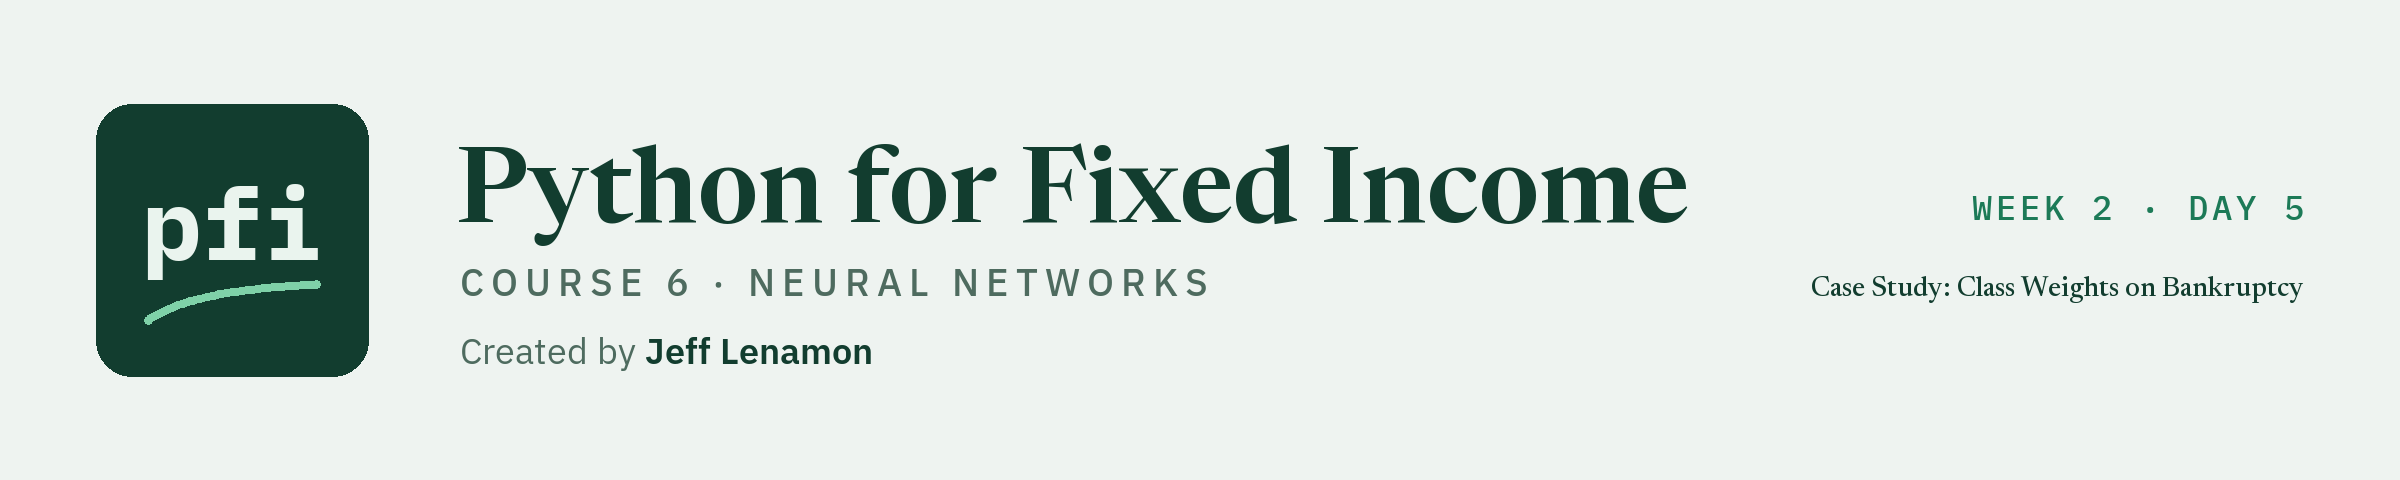

# Case Study: Class Weights on Bankruptcy

Week 2, Day 5. Week 2 ends with a case study on a rare outcome: what class weights do to a network's loss and to its output, then a network chosen by five folds inside Course 4's Polish training rows, with and without class weights, beside Course 4's logistic regression and Course 5's LightGBM on the same folds, with bootstrap intervals and a written description of what it shows and where it fails.

**Data:** `polish_bankruptcy_5year.csv`, 5,910 financial statements of Polish companies: **real**, UCI Machine Learning Repository dataset 365, CC BY 4.0. Citation: Tomczak, S. (2016). Polish Companies Bankruptcy [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5F600.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course06_neural_networks/week2/day5/10_case_study_class_weights_on_bankruptcy.ipynb)

Days 6 to 9 trained networks: losses, learning rates, optimizers, starting weights, batch normalization, dropout, and early stopping. Today the training meets a file where the outcome is rare. Of Course 4's 4,680 Polish training rows, 326 were followed by bankruptcy, 6.97 percent. The usual answer to a rare outcome is to weight it: make every bankrupt company count more in the loss. The question for the day is what that weight really does, and whether it helps a network rank these companies.

**The Polish rules, as on every Polish day in this course.**

* **The data is real.** `polish_bankruptcy_5year.csv` is the UCI file Course 4's capstone and Course 5's week 3 modelled: financial statements of Polish companies, anonymised, with no company names, and a flag for bankruptcy. The dataset page says: "The bankrupt companies were analyzed in the period 2000-2012, while the still operating companies were evaluated from 2007 to 2013." The companies are Polish, and the statements come from the 2000s and early 2010s: corporate credit there and then differs from US credit today, and nothing here describes any other country, period, or company.
* **Course 4's split, rebuilt, with its test rows closed.** Course 4 dropped 60 exact duplicate rows and split the remaining 5,850 80/20, stratified, with the course seed. Its 1,170 test rows were opened once, in its capstone, and by day 1's test-row rule they are never scored in Course 6: `ensemblekit.course4_polish_rows` returns the 4,680 training rows only. Every number today comes from rows carved from them or from folds inside them.
* **A model's output is described, never acted on.** A network's output is the model probability of bankruptcy in this file, or a flag at a threshold; a network fitted with class weights gives the model's score. No output is a credit view on any company, a rating, or an investment decision.

The day has two halves.

**Hands-on, sections 10.1 and 10.2.**

1. `balanced_class_weight`: the weights that make each class count equally, against scikit-learn's.
2. What `class_weight` does inside `fit`: a weighted log loss, worked by hand and checked against Keras.
3. `output_vs_rate`: what the weights do to the network's average output.

**Case study, sections 10.3 to 10.10.** The rows, the preparation, a network chosen one setting at a time by five folds, class weights against none against a lower threshold, the comparison with Course 4's logistic regression and Course 5's LightGBM on the same folds, intervals, a results workbook, and **What the Model Shows, and Where It Fails**.

Q. Set up today's work folder: TensorFlow's settings, the thread settings, the seed, and the Polish file.

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course06_neural_networks/requirements.txt
NEEDED = {
    "imblearn": "imbalanced-learn==0.14.2",
    "ipykernel": "ipykernel==7.4.0",
    "ipywidgets": "ipywidgets==8.1.9",
    "jinja2": "jinja2==3.1.6",
    "keras": "keras==3.15.1",
    "lightgbm": "lightgbm==4.7.0",
    "matplotlib": "matplotlib==3.11.2",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "pandas": "pandas==3.0.6",
    "pytest": "pytest==9.1.1",
    "sklearn": "scikit-learn==1.9.1",
    "scipy": "scipy==1.18.1",
    "shap": "shap==0.52.0",
    "statsmodels": "statsmodels==0.15.0",
    "tensorflow": "tensorflow==2.21.0",
    "xgboost": "xgboost==3.4.1",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

17 packages checked, all present


In [2]:
# today's setup: the TensorFlow and thread settings, the modules, the seed, the course data, and a fresh work folder
import os

# TensorFlow writes start-up notices to stderr: these three lines must run before TensorFlow is imported
os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

# one thread for the maths libraries, so every run of the notebook gives the same last digits.
# These lines must run before numpy, pandas, scikit-learn, TensorFlow, or LightGBM is imported: if you ran another
# cell first, restart the kernel and run this cell first (in Colab: Runtime, Restart session).
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import importlib
import importlib.metadata
import importlib.util
import platform
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

# packages a Colab runtime or a new environment may lack: stop with the line that installs the missing one
for module_name, install_name in [("sklearn", "scikit-learn"), ("statsmodels", "statsmodels"), ("scipy", "scipy"), ("tensorflow", "tensorflow"), ("keras", "keras"), ("lightgbm", "lightgbm"), ("pytest", "pytest")]:
    if importlib.util.find_spec(module_name) is None:
        raise RuntimeError(f"{install_name} is not installed. Run  !pip install {install_name}  in a new cell, "
                           "then run this cell again.")

import numpy as np
import pandas as pd
import tensorflow as tf
import keras

# one thread for TensorFlow too, set before TensorFlow runs anything
tf.config.threading.set_intra_op_parallelism_threads(1)
tf.config.threading.set_inter_op_parallelism_threads(1)
# TensorFlow's own Python notices are turned down to errors; on Windows the one it writes is that it has no GPU
# support there (day 1 explains it)
tf.get_logger().setLevel("ERROR")
# where TensorFlow has a deterministic version of an operation, use it
tf.config.experimental.enable_op_determinism()

# the versions the saved outputs of this notebook came from (course06_neural_networks/requirements.txt)
PINNED = {"numpy": "2.5.3", "pandas": "3.0.6", "scikit-learn": "1.9.1", "scipy": "1.18.1", "tensorflow": "2.21.0", "keras": "3.15.1", "lightgbm": "4.7.0", "matplotlib": "3.11.2", "pytest": "9.1.1"}
installed = {name: importlib.metadata.version(name) for name in PINNED}
print(f"Python {platform.python_version()}; " + ", ".join(f"{name} {version}" for name, version in installed.items()))
different = [name for name in PINNED if installed[name] != PINNED[name]]
if different:
    print(f"Not the course's pinned version: {', '.join(different)}. Printed numbers may differ in the last digits from the saved notebook.")

# the seed: one number for every random choice the course makes, so every run makes the same choices
SEED = 42
# Keras's seed sets Python's, numpy's, and TensorFlow's random generators at once
keras.utils.set_random_seed(SEED)

# the kinds of device TensorFlow can use on this machine
devices = sorted({device.device_type for device in tf.config.list_physical_devices()})
print(f"Devices TensorFlow can use: {', '.join(devices)}")

# remember the notebook's own folder, so that running this cell again starts from the same place
if "notebook_folder" not in globals():
    notebook_folder = Path.cwd()

# 1. find the course data before moving: the repo's data folder on your machine, GitHub in Colab
RAW_DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"
local_data = (notebook_folder / ".." / ".." / ".." / "data").resolve()
on_github = not (local_data / "credit_card_default.csv").exists()

# 2. a fresh work folder for today, in the system temp folder, outside the course repo
work = Path(tempfile.mkdtemp(prefix="pfi_course6_10_"))
os.chdir(work)

# 3. copy today's data files into the work folder
DATA_FILES = ["polish_bankruptcy_5year.csv"]
for name in DATA_FILES:
    if on_github:
        urllib.request.urlretrieve(RAW_DATA + name, work / name)
    else:
        shutil.copy(local_data / name, work / name)

# print the folder's name only: its full path would show your user name
print(f"Work folder: {work.name}, in your temp folder")
print(f"Data files from {'GitHub' if on_github else 'the data folder of the course repo'}: {', '.join(DATA_FILES)}")
print(f"SEED = {SEED}")

Python 3.13.8; numpy 2.5.3, pandas 3.0.6, scikit-learn 1.9.1, scipy 1.18.1, tensorflow 2.21.0, keras 3.15.1, lightgbm 4.7.0, matplotlib 3.11.2, pytest 9.1.1
Devices TensorFlow can use: CPU
Work folder: pfi_course6_10_zeioh9un, in your temp folder
Data files from the data folder of the course repo: polish_bankruptcy_5year.csv
SEED = 42


Q. Write `mlkit.py`, Course 4's complete module, and `ensemblekit.py`, Course 5's complete module, both unchanged. `netkit` imports them.

In [3]:
%%writefile mlkit.py
"""mlkit: the small pieces of machine learning that scikit-learn leaves to the analyst, written down and tested.

Written day by day in Python for Fixed Income, Course 4: Machine Learning.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one, so every run gives the same numbers.
- Spreads are in basis points (bp). A model of log_oas is fitted in natural logs of bp; its errors are reported
  in bp after exp, and exp of a fitted log is a median-type value, not a mean.
- The positive class is 1 (default, bankrupt). Precision, recall, and F1 are for class 1 only.
- A row is flagged when its model probability is at least the threshold (probability >= threshold).
- Rows that fit a model, rows that choose a setting, and rows that report a result are kept apart; the split
  functions here prove it with a check that stops.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
from numpy.typing import ArrayLike  # a list, an array, or a pandas Series


def assert_disjoint(train_index: ArrayLike, test_index: ArrayLike) -> None:
    """Stop if any row label is in both the training rows and the test rows.

    Inputs: the labels (or positions) of the rows in each part, for example X_train.index and X_test.index.
    Output: None when the parts share no label.
    Convention: a row in both parts is a test row the model has already seen, which flatters every metric.
    Raises AssertionError naming how many labels are in both parts, and ValueError if either part is empty.
    """
    # the labels of each part as sets
    train = set(np.asarray(train_index).tolist())
    test = set(np.asarray(test_index).tolist())
    if not train or not test:
        raise ValueError("train_index and test_index must both hold at least one label")
    # the labels found in both parts
    shared = train & test
    if shared:
        raise AssertionError(f"{len(shared)} row labels are in both the training and the test rows")


def _as_1d_array(values: ArrayLike, name: str) -> np.ndarray:
    """Return `values` as a 1-D float array, or raise ValueError naming the input."""
    array = np.asarray(values, dtype=float)
    if array.ndim != 1:
        raise ValueError(f"{name} must be one-dimensional, not {array.ndim}-dimensional")
    if array.size == 0:
        raise ValueError(f"{name} is empty")
    return array


def regression_metrics(y_true: ArrayLike, y_fitted: ArrayLike) -> dict[str, float]:
    """R-squared, mean absolute error, and root mean squared error of fitted values.

    Inputs: y_true and y_fitted, the same length, in the target's unit (for example oas in bp).
    Output: {"r2", "mae", "rmse"}. r2 is unitless, 1 - SS_res / SS_tot on the rows given (on test rows it can
    be negative); mae and rmse are in the target's unit. For a log_oas model, pass exp of both to get bp.
    Convention: equal to scikit-learn's r2_score, mean_absolute_error, and root_mean_squared_error.
    Excel: =RSQ(...) only for a straight line on one feature; =AVERAGE(ABS(a-b)) and =SQRT(SUMXMY2(a,b)/COUNT(a)).
    Raises ValueError if the inputs are empty, not one-dimensional, or of different lengths.
    """
    # check both inputs and that they line up row for row
    actual = _as_1d_array(y_true, "y_true")
    fitted = _as_1d_array(y_fitted, "y_fitted")
    if actual.size != fitted.size:
        raise ValueError(f"y_true has {actual.size} values and y_fitted has {fitted.size}")
    # each error in the target's unit
    errors = actual - fitted
    # R-squared: the share of the spread around the mean that the fitted values account for
    ss_res = float(np.sum(errors ** 2))
    ss_tot = float(np.sum((actual - actual.mean()) ** 2))
    r2 = 1 - ss_res / ss_tot
    # the average size of an error, and the square root of the average squared error
    mae = float(np.mean(np.abs(errors)))
    rmse = float(np.sqrt(np.mean(errors ** 2)))
    return {"r2": r2, "mae": mae, "rmse": rmse}


def adjusted_r2(r2: float, n_rows: int, n_features: int) -> float:
    """Adjusted R-squared: R-squared with a charge for each feature.

    Inputs: r2 on the training rows (unitless), n_rows the number of training rows, n_features the number of
    features not counting the intercept.
    Output: 1 - (1 - r2) x (n_rows - 1) / (n_rows - n_features - 1), unitless. An in-sample measure, so it is
    computed on training rows only.
    Excel: =1-(1-R2)*(n-1)/(n-k-1)
    Raises ValueError if n_features is negative or n_rows is not above n_features + 1.
    """
    # the formula needs at least one degree of freedom left after the features and the intercept
    if n_features < 0:
        raise ValueError(f"n_features must be 0 or more, not {n_features}")
    if n_rows <= n_features + 1:
        raise ValueError(f"n_rows ({n_rows}) must be greater than n_features + 1 ({n_features + 1})")
    # scale the unexplained share by the ratio of degrees of freedom
    return 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1)


def rating_dummies(ratings: pd.Series, levels: list[str], reference: str) -> pd.DataFrame:
    """One indicator column per rating level except the reference level, which the intercept stands for.

    Inputs: ratings, one text rating per bond (for example "BBB+"); levels, every allowed level in the order the
    columns should follow (the rating column of ratings.csv, known in advance, not learned from the data);
    reference, the level left out.
    Output: a DataFrame with the same index, one float column (0.0 or 1.0) per level except reference, named
    rating_<level>, in the order of levels. A coefficient on rating_BB is then the difference from a bond rated
    `reference`, other features fixed.
    Convention: floats, not booleans, so every library and an Excel formula read the same 0.0 and 1.0. The
    reference is named by the caller, never chosen by alphabetical order.
    Raises ValueError if ratings is empty, reference is not in levels, or a rating is not in levels.
    """
    # check the inputs before building anything
    if len(ratings) == 0:
        raise ValueError("ratings is empty")
    if reference not in levels:
        raise ValueError(f"reference {reference!r} is not one of the levels")
    unknown = sorted(set(ratings) - set(levels))
    if unknown:
        raise ValueError(f"ratings not in levels: {unknown}")
    # one column per level, 1.0 where the bond has that rating
    columns = {f"rating_{level}": (ratings == level).astype(float) for level in levels if level != reference}
    return pd.DataFrame(columns, index=ratings.index)


def vif_table(X: pd.DataFrame) -> pd.Series:
    """Variance inflation factor of each feature: how much its coefficient's variance grows from the overlap with
    the other features.

    Input: X, the features as numeric columns (no constant column; one is added inside).
    Output: a Series named vif, one value per column, sorted from highest to lowest. VIF_j = 1 / (1 - R2_j),
    where R2_j is the R-squared of column j regressed on a constant and every other column. 1 means no overlap;
    above 5 is called high and above 10 very high, as conventions. A column that is an exact copy (or exact
    combination) of others has R2_j = 1 and VIF infinity.
    Convention: equal to statsmodels' variance_inflation_factor on X with a constant added.
    Excel: =1/(1-INDEX(LINEST(xj, other columns, TRUE, TRUE), 3, 1))
    Raises ValueError if X has fewer than two columns or fewer rows than columns plus two.
    """
    # check there is something to regress on, and enough rows to do it
    if X.shape[1] < 2:
        raise ValueError(f"X needs at least two columns, not {X.shape[1]}")
    if X.shape[0] < X.shape[1] + 2:
        raise ValueError(f"X has {X.shape[0]} rows, too few for {X.shape[1]} columns")
    values = X.to_numpy(dtype=float)
    result = {}
    for j, name in enumerate(X.columns):
        # column j is the target; a constant and the other columns are the features
        target = values[:, j]
        others = np.column_stack([np.ones(len(values)), np.delete(values, j, axis=1)])
        # least squares fit and its R-squared
        coefficients, *_ = np.linalg.lstsq(others, target, rcond=None)
        ss_res = float(np.sum((target - others @ coefficients) ** 2))
        ss_tot = float(np.sum((target - target.mean()) ** 2))
        r2 = 1 - ss_res / ss_tot
        # an exact combination of the others leaves no residual (R-squared 1 to the last digit): the VIF is infinite
        result[name] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(result, name="vif").sort_values(ascending=False)


from scipy import stats  # Jarque-Bera and Shapiro-Wilk
from statsmodels.stats.diagnostic import het_breuschpagan  # Breusch-Pagan
from statsmodels.tools import add_constant  # the intercept column


def residual_tests(residuals: pd.Series, exog: pd.DataFrame) -> dict[str, float]:
    """p-values of three checks on a regression's residuals: constant variance and normality (two tests).

    Inputs: residuals, actual minus fitted on the training rows, in the target's unit; exog, the features the
    model was fitted on, without a constant (one is added inside), with the same rows.
    Output: {"breusch_pagan", "jarque_bera", "shapiro_wilk"}, each a p-value between 0 and 1. A small p-value
    (below 0.05, the course's convention) means the data would be surprising if the assumption held:
    - breusch_pagan: statsmodels het_breuschpagan with its default (Koenker's form, n x R-squared of the squared
      residuals regressed on a constant and exog); the assumption is constant variance;
    - jarque_bera: scipy.stats.jarque_bera (skew and kurtosis); the assumption is normal residuals;
    - shapiro_wilk: scipy.stats.shapiro; the assumption is normal residuals.
    Excel has no function for these; Breusch-Pagan can be built from LINEST and CHISQ.DIST.RT.
    Raises ValueError if the inputs are empty or have different numbers of rows.
    """
    # check the two inputs line up
    if len(residuals) == 0 or len(exog) == 0:
        raise ValueError("residuals and exog must not be empty")
    if len(residuals) != len(exog):
        raise ValueError(f"residuals has {len(residuals)} rows and exog has {len(exog)}")
    values = np.asarray(residuals, dtype=float)
    # Breusch-Pagan: returns the LM statistic, its p-value, then an F form; the LM p-value is kept
    _, bp_pvalue, _, _ = het_breuschpagan(values, add_constant(np.asarray(exog, dtype=float), has_constant="add"))
    # the two normality tests
    jb_pvalue = stats.jarque_bera(values).pvalue
    sw_pvalue = stats.shapiro(values).pvalue
    return {"breusch_pagan": float(bp_pvalue), "jarque_bera": float(jb_pvalue), "shapiro_wilk": float(sw_pvalue)}


from sklearn.pipeline import Pipeline  # the type of a chain of steps


def named_coefficients(pipeline: Pipeline) -> pd.Series:
    """The fitted coefficients of a pipeline's last step, labelled with the feature names that step saw.

    Input: a fitted scikit-learn Pipeline whose last step has coef_ (LinearRegression, Ridge, Lasso,
    LogisticRegression) and whose step before it has get_feature_names_out (a ColumnTransformer, a scaler).
    Output: a Series of coefficients indexed by feature name, in the order the model used them. Units: per unit
    of each feature as the model saw it, so per standard deviation after StandardScaler; the intercept is not
    included. For a binary LogisticRegression the one row of coef_ is used (log-odds of class 1).
    Raises ValueError if the last step has no coef_ (a tree, for example) or the pipeline has one step only.
    """
    # the model is the last step; the names come from everything before it
    if len(pipeline.steps) < 2:
        raise ValueError("the pipeline needs a preprocessing step before the model")
    model = pipeline.steps[-1][1]
    if not hasattr(model, "coef_"):
        raise ValueError(f"the last step, {type(model).__name__}, has no coef_")
    names = pipeline[:-1].get_feature_names_out()
    # a binary classifier keeps its coefficients in one row; flatten it
    coefficients = np.ravel(model.coef_)
    if coefficients.size != len(names):
        raise ValueError(f"{coefficients.size} coefficients but {len(names)} feature names")
    return pd.Series(coefficients, index=names, name="coefficient")


def odds_ratios(coefficients: pd.Series) -> pd.Series:
    """Odds ratios from logistic regression coefficients: exp of each coefficient, the intercept left out.

    Input: coefficients in log-odds, indexed by feature name, as statsmodels' Logit params (the intercept is
    named "const") or a Series with an entry named "intercept".
    Output: a Series of exp(coefficient) per feature: the factor by which the odds of class 1 multiply for one
    more unit of that feature, other features fixed. The unit is the feature's own (per 10,000 NT dollars if the
    feature was divided by 10,000; per standard deviation if it was scaled).
    Excel: =EXP(coef)
    Raises ValueError if no coefficient is left once the intercept is removed.
    """
    # leave out the intercept: exp of it is the odds when every feature is 0, not a ratio
    slopes = coefficients.drop(labels=["const", "intercept"], errors="ignore")
    if slopes.empty:
        raise ValueError("no coefficients left after removing the intercept")
    return np.exp(slopes).rename("odds_ratio")


def logistic_probability(z: float | ArrayLike) -> float | np.ndarray:
    """The logistic curve: turns log-odds z into a probability between 0 and 1.

    Input: z, a number or an array of numbers in log-odds (intercept plus coefficients times features).
    Output: 1 / (1 + exp(-z)), a float for a number, an array for an array. z = 0 gives 0.5.
    Excel: =1/(1+EXP(-z))
    """
    # numpy's exp works on a number and on an array alike
    probability = 1 / (1 + np.exp(-np.asarray(z, dtype=float)))
    return float(probability) if probability.ndim == 0 else probability


def _check_labels(y_true: ArrayLike, y_flag: ArrayLike) -> tuple[np.ndarray, np.ndarray]:
    """Return both inputs as integer arrays of 0 and 1, or raise ValueError."""
    actual = np.asarray(y_true)
    flagged = np.asarray(y_flag)
    if actual.ndim != 1 or flagged.ndim != 1 or actual.size == 0:
        raise ValueError("y_true and y_flag must be non-empty and one-dimensional")
    if actual.size != flagged.size:
        raise ValueError(f"y_true has {actual.size} values and y_flag has {flagged.size}")
    for name, values in (("y_true", actual), ("y_flag", flagged)):
        others = sorted(set(values.tolist()) - {0, 1})
        if others:
            raise ValueError(f"{name} holds labels other than 0 and 1: {others[:5]}")
    return actual.astype(int), flagged.astype(int)


def confusion_counts(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, int]:
    """The four cells of the confusion matrix, with 1 (default) as the positive class.

    Inputs: y_true, the actual outcome per row (0 or 1); y_flag, the model's flag per row (0 or 1), for example
    (probability >= threshold).
    Output: {"tn", "fp", "fn", "tp"} as whole numbers: true negatives (0 flagged 0), false positives (0 flagged
    1), false negatives (1 flagged 0), true positives (1 flagged 1). They add up to the number of rows.
    Convention: the same counts as confusion_matrix(y_true, y_flag).ravel() in scikit-learn.
    Excel: =COUNTIFS(actual,1,flag,1) and the other three combinations.
    Raises ValueError on labels other than 0 and 1, empty inputs, or inputs of different lengths.
    """
    actual, flagged = _check_labels(y_true, y_flag)
    # count each combination of actual and flag
    return {"tn": int(np.sum((actual == 0) & (flagged == 0))), "fp": int(np.sum((actual == 0) & (flagged == 1))),
            "fn": int(np.sum((actual == 1) & (flagged == 0))), "tp": int(np.sum((actual == 1) & (flagged == 1)))}


def classification_metrics(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, float]:
    """Accuracy, precision, recall, and F1 for class 1 (default), from 0/1 flags.

    Inputs: y_true and y_flag, as confusion_counts.
    Output: {"accuracy", "precision", "recall", "f1"}, each between 0 and 1:
    accuracy (TP + TN) / n; precision TP / (TP + FP), the share of flagged rows that are defaults; recall
    TP / (TP + FN), the share of defaults that are flagged; F1 their harmonic mean, 2TP / (2TP + FP + FN).
    Convention: pos_label=1, binary averaging, zero_division=0 (a model that flags nothing has precision 0, not
    an error), as scikit-learn's functions with those arguments.
    Excel: =TP/(TP+FP), =TP/(TP+FN) with the COUNTIFS cells.
    Raises ValueError as confusion_counts.
    """
    counts = confusion_counts(y_true, y_flag)
    tn, fp, fn, tp = counts["tn"], counts["fp"], counts["fn"], counts["tp"]
    # each ratio is 0 when its denominator is 0 (zero_division=0)
    accuracy = (tp + tn) / (tn + fp + fn + tp)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}


def threshold_for_recall(y_true: ArrayLike, proba: ArrayLike, target_recall: float) -> float:
    """The highest threshold at which the model still catches at least `target_recall` of the defaults.

    Inputs: y_true, actual outcomes (0 or 1) on the rows used to choose (validation rows, or out-of-fold
    predictions on training rows, never test rows); proba, the model probability of class 1 per row;
    target_recall, the share of defaults the desk asks to catch, above 0 and at most 1.
    Output: one of the distinct probabilities. Flagging rows with probability >= that threshold gives recall at
    least target_recall, and the next higher distinct probability would give less. A higher threshold flags
    fewer rows, so this is the threshold with the fewest flags that meets the target.
    Convention: the course's threshold rule, stated as an illustration of the recall-against-precision choice.
    Raises ValueError if target_recall is not in (0, 1], the inputs differ in length, or there is no row of
    class 1.
    """
    # check the target and the inputs
    if not 0 < target_recall <= 1:
        raise ValueError(f"target_recall must be above 0 and at most 1, not {target_recall}")
    scores = _as_1d_array(proba, "proba")
    # y_true is checked as a set of 0/1 labels the same length as proba
    actual, _ = _check_labels(y_true, np.zeros(scores.size, dtype=int))
    positives = int(actual.sum())
    if positives == 0:
        raise ValueError("y_true has no row of class 1, so recall is undefined")
    # sort rows from the highest probability down; lowering the threshold adds rows in this order
    order = np.argsort(-scores, kind="stable")
    sorted_scores, sorted_actual = scores[order], actual[order]
    # defaults caught when every row down to this one is flagged
    caught = np.cumsum(sorted_actual)
    # a threshold equal to a probability flags every row with that probability, so look at the last row of
    # each run of equal probabilities
    last_of_run = np.append(sorted_scores[1:] != sorted_scores[:-1], True)
    recall = caught[last_of_run] / positives
    thresholds = sorted_scores[last_of_run]
    # thresholds run from high to low and recall only rises: take the first one that meets the target
    meets = np.nonzero(recall >= target_recall)[0]
    return float(thresholds[meets[0]])


from sklearn.model_selection import KFold, StratifiedKFold  # the course's cross-validation splitters


def cv_folds(kind: str = "classification") -> KFold | StratifiedKFold:
    """The course's cross-validation splitter, so the choice lives in one place.

    Input: kind, "classification" or "regression".
    Output: StratifiedKFold(5, shuffle=True, random_state=42) for classification (each fold keeps the share of
    class 1), KFold(5, shuffle=True, random_state=42) for regression. Pass it as cv= to GridSearchCV,
    cross_val_score, or cross_val_predict, on training rows only.
    Convention: never for dated rows, which use walk_forward_splits or TimeSeriesSplit (no shuffle).
    Raises ValueError for any other kind.
    """
    # five folds, shuffled once with the course's seed
    if kind == "classification":
        return StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    if kind == "regression":
        return KFold(n_splits=5, shuffle=True, random_state=42)
    raise ValueError(f'kind must be "classification" or "regression", not {kind!r}')


import re  # whole-word search

from sklearn.metrics import average_precision_score, roc_auc_score

# words that turn a description into a forecast, advice, or a lending decision; a reminder, not a proof
FORECAST_WORDS = ["will", "expect", "expects", "should", "forecast", "forecasts", "cheap", "rich", "attractive",
                  "signal", "signals", "buy", "sell", "approve", "decline", "lend", "invest"]


def compare_models(models: dict, X: pd.DataFrame, y: ArrayLike, thresholds: dict[str, float]) -> pd.DataFrame:
    """One row of metrics per fitted model, on the rows given.

    Inputs: models, {name: a fitted classifier with predict_proba}, fitted by the caller on training rows;
    X and y, the rows to report on (validation rows, or the test rows once at the end); thresholds,
    {name: threshold} for every model, chosen on rows other than these test rows.
    Output: a DataFrame indexed by model name with columns roc_auc and average_precision (from probabilities,
    no threshold), then threshold, accuracy, precision, recall, f1 for rows flagged at probability >= threshold.
    Convention: nothing is fitted here; an unfitted model raises scikit-learn's NotFittedError.
    Raises ValueError if models is empty or a model has no threshold.
    """
    # check every model has a threshold before computing anything
    if not models:
        raise ValueError("models is empty")
    missing = sorted(set(models) - set(thresholds))
    if missing:
        raise ValueError(f"no threshold for: {missing}")
    rows = {}
    for name, model in models.items():
        # the model probability of class 1 per row
        proba = model.predict_proba(X)[:, 1]
        # metrics that rank without a threshold, then metrics at the model's threshold
        row = {"roc_auc": roc_auc_score(y, proba), "average_precision": average_precision_score(y, proba),
               "threshold": thresholds[name]}
        row |= classification_metrics(y, (proba >= thresholds[name]).astype(int))
        rows[name] = row
    return pd.DataFrame.from_dict(rows, orient="index")


def assert_descriptive(text: str) -> None:
    """Stop if a written description uses a word from FORECAST_WORDS.

    Input: text, a description of what a model shows.
    Output: None if no listed word appears as a whole word, in any case.
    Convention: the list is a reminder, not a proof. A text can pass and still make a forecast in other words,
    and a listed word can be harmless in context; the check makes the writer look again.
    Raises ValueError naming every listed word found, in the order of FORECAST_WORDS.
    """
    # whole words only, ignoring case: "willing" does not match "will"
    found = [word for word in FORECAST_WORDS if re.search(rf"\b{word}\b", text, flags=re.IGNORECASE)]
    if found:
        raise ValueError(f"the text uses forecast, advice, or lending words: {found}")


def walk_forward_splits(dates: pd.DatetimeIndex, min_train: int, test_size: int,
                        gap: int = 0) -> list[tuple[np.ndarray, np.ndarray]]:
    """Expanding-window splits for dated rows: train on the past, test on the rows that follow.

    Inputs: dates, the rows' dates, unique and ascending; min_train, the rows in the first training window;
    test_size, the rows in each test window; gap, rows left out between the last training row and the first
    test row (use the number of rows a target or feature spans; 0 for a same-day target).
    Output: a list of (train_positions, test_positions), integer positions into dates. Fold k trains on
    positions 0 to min_train + k x test_size - 1 and tests the next test_size positions after `gap` rows.
    The window steps forward by test_size; a last test window shorter than test_size is dropped.
    Convention: never shuffled; every training date is before every test date.
    Raises ValueError if the dates are not unique and ascending, min_train or test_size is below 1, gap is
    negative, or there are too few rows for one fold.
    """
    # check the dates and the sizes
    index = pd.DatetimeIndex(dates)
    if not (index.is_unique and index.is_monotonic_increasing):
        raise ValueError("dates must be unique and ascending")
    if min_train < 1 or test_size < 1 or gap < 0:
        raise ValueError(f"need min_train >= 1, test_size >= 1, gap >= 0; got {min_train}, {test_size}, {gap}")
    splits = []
    train_end = min_train  # one past the last training position
    # add folds while a whole test window fits after the gap
    while train_end + gap + test_size <= len(index):
        test_start = train_end + gap
        splits.append((np.arange(0, train_end), np.arange(test_start, test_start + test_size)))
        train_end += test_size
    if not splits:
        raise ValueError(f"{len(index)} rows are too few for min_train {min_train}, gap {gap}, test_size {test_size}")
    return splits


def assert_past_only(train_dates: ArrayLike, test_dates: ArrayLike, gap: int = 0,
                     calendar: ArrayLike | None = None) -> None:
    """Stop unless every training date is earlier than every test date, with a gap where one is asked for.

    Inputs: the dates of the training rows and of the test rows; gap, the rows of `calendar` that must lie
    strictly between the last training date and the first test date; calendar, every date of the dataset
    (needed when gap is above 0).
    Output: None when the split uses only the past.
    Raises AssertionError naming the last training date and the first test date when the order or the gap is
    wrong, and ValueError if either part is empty or a gap is asked for without a calendar.
    """
    train = pd.DatetimeIndex(train_dates)
    test = pd.DatetimeIndex(test_dates)
    if len(train) == 0 or len(test) == 0:
        raise ValueError("train_dates and test_dates must both hold at least one date")
    # the latest training date must come before the earliest test date
    last_train, first_test = train.max(), test.min()
    if not last_train < first_test:
        raise AssertionError(f"a training date ({last_train.date()}) is not before the first test date "
                             f"({first_test.date()})")
    if gap > 0:
        if calendar is None:
            raise ValueError("a gap is counted in rows of the calendar, so calendar is needed")
        # rows of the calendar strictly between the two dates
        days = pd.DatetimeIndex(calendar)
        between = int(((days > last_train) & (days < first_test)).sum())
        if between < gap:
            raise AssertionError(f"only {between} rows lie between {last_train.date()} and {first_test.date()}, "
                                 f"fewer than the gap of {gap}")


from collections.abc import Iterable

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


def elbow_table(X: ArrayLike, k_values: Iterable[int], seed: int = 42) -> pd.DataFrame:
    """Inertia and silhouette of K-means for each number of clusters, to choose k by judgement.

    Inputs: X, the features already scaled (K-means measures distance, so units decide the clusters); k_values,
    the numbers of clusters to try, each 2 or more; seed, passed as random_state.
    Output: a DataFrame indexed by k (named k) with columns inertia (the within-cluster sum of squared distances,
    in squared scaled units; it falls as k rises) and silhouette (the mean silhouette coefficient, Euclidean,
    -1 to 1; higher means tighter, better separated clusters).
    Convention: KMeans(n_clusters=k, n_init=10, random_state=seed), n_init written out.
    Raises ValueError if k_values is empty, a k is below 2, or a k is not below the number of rows.
    """
    # check the k values before fitting
    ks = list(k_values)
    if not ks:
        raise ValueError("k_values is empty")
    n_rows = len(X)
    bad = [k for k in ks if k < 2 or k >= n_rows]
    if bad:
        raise ValueError(f"each k must be at least 2 and below the {n_rows} rows; not {bad}")
    rows = []
    for k in ks:
        # fit K-means with ten starts and the course's seed
        model = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X)
        rows.append({"k": k, "inertia": float(model.inertia_), "silhouette": float(silhouette_score(X, model.labels_))})
    return pd.DataFrame(rows).set_index("k")


def cluster_profile(frame: pd.DataFrame, labels: ArrayLike, columns: list[str]) -> pd.DataFrame:
    """Describe each cluster in the data's own units: how many rows, and the median of each column.

    Inputs: frame, the rows in their original units (oas in bp, duration in years), not the scaled features the
    clusters were fitted on; labels, the cluster of each row, in the same order; columns, the columns to profile.
    Output: a DataFrame indexed by cluster (named cluster, sorted), with count and one median column per name in
    columns, in the frame's units. A profile describes a group; it does not rank one.
    Excel: a pivot table counts and averages but has no median; =MEDIAN(IF(labels=k, column)) does.
    Raises ValueError if labels and frame differ in length, frame is empty, or a column is not in frame.
    """
    # check the inputs line up and the columns exist
    labels = np.asarray(labels)
    if len(frame) == 0:
        raise ValueError("frame is empty")
    if len(labels) != len(frame):
        raise ValueError(f"labels has {len(labels)} values and frame has {len(frame)} rows")
    missing = [c for c in columns if c not in frame.columns]
    if missing:
        raise ValueError(f"columns not in frame: {missing}")
    # group the original rows by cluster, then count and take medians
    grouped = frame[columns].groupby(pd.Series(labels, index=frame.index, name="cluster"))
    profile = grouped.median()
    profile.insert(0, "count", grouped.size())
    return profile.sort_index()


from sklearn.decomposition import PCA


def pca_loadings(pca: PCA, names: list[str]) -> pd.DataFrame:
    """The loadings of a fitted PCA, one column per component, each with a fixed sign.

    Inputs: pca, a fitted scikit-learn PCA; names, the input columns in the order the PCA saw them (for the
    curve, the tenors).
    Output: a DataFrame indexed by name with columns PC1, PC2, ...: each component's weights on the inputs
    (pca.components_ transposed, unit length). A component's sign is arbitrary, so each column is multiplied by
    -1 where needed to make its loadings sum to a positive number; a rerun or another library then gives the
    same picture. Scores that match these loadings are (X - pca.mean_) @ loadings.
    Excel: no PCA function; =MMULT(changes less their column means, loadings) gives the scores.
    Raises ValueError if names does not have one entry per input column.
    """
    # one name per input column
    components = np.asarray(pca.components_)
    if len(names) != components.shape[1]:
        raise ValueError(f"{len(names)} names for {components.shape[1]} input columns")
    loadings = pd.DataFrame(components.T, index=names,
                            columns=[f"PC{i}" for i in range(1, components.shape[0] + 1)])
    # flip each component whose loadings sum to a negative number
    signs = np.where(loadings.sum(axis=0) < 0, -1.0, 1.0)
    return loadings * signs


def explained_table(pca: PCA) -> pd.DataFrame:
    """The share of variance each component of a fitted PCA accounts for, and the running total, in percent.

    Input: pca, a fitted scikit-learn PCA.
    Output: a DataFrame indexed by PC1, PC2, ... with explained_pct (explained_variance_ratio_ x 100) and
    cumulative_pct (the running sum). With every component kept, the last cumulative_pct is 100.
    """
    # the ratios in percent, then their running sum
    explained = np.asarray(pca.explained_variance_ratio_) * 100
    index = [f"PC{i}" for i in range(1, len(explained) + 1)]
    return pd.DataFrame({"explained_pct": explained, "cumulative_pct": np.cumsum(explained)}, index=index)

Writing mlkit.py


In [4]:
%%writefile ensemblekit.py
"""ensemblekit: the pieces of ensembles, tuning, and rare-event modelling that the libraries leave to the analyst,
written down and tested.

Written day by day in Python for Fixed Income, Course 5: Advanced Machine Learning. It imports mlkit (Course 4's
module) and never changes it.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one, so every run gives the same numbers.
- The positive class is 1 (default, bankrupt). A row is flagged when its model output is at least the threshold.
- Course 5 never scores a row that Course 4 used as a test row. The course4_*_rows functions rebuild Course 4's
  splits exactly and return only the rows Course 5 may use; the closed rows are never returned.
- Rows that fit a model, rows that choose a setting, and rows that report a result are kept apart.
- Every library call that can use more than one thread is given n_jobs=1, so every run gives the same digits.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
from sklearn.model_selection import train_test_split  # Course 4's split, rebuilt

import mlkit  # Course 4's module: thresholds, metrics, splitters, and the no-leak check

# the card file: its outcome column and the 19 model columns (the four person columns are never features)
CARD_TARGET = "default payment next month"
CARD_FEATURES = ["LIMIT_BAL", "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"] + \
    [f"BILL_AMT{i}" for i in range(1, 7)] + [f"PAY_AMT{i}" for i in range(1, 7)]


def course4_card_rows(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame, pd.Series, pd.Series]:
    """Course 4's 60/20/20 split of the card file, rebuilt, without its test rows.

    Input: frame, the 30,000 accounts of credit_card_default.csv as read by pd.read_csv.
    Output: X_train (18,000 rows), X_valid (6,000 rows), y_train, y_valid, with the 19 model columns in
    CARD_FEATURES and the file's row labels. Course 4's 6,000 test rows are never returned.
    Convention: the same two calls as Course 4: train_test_split(test_size=0.2, stratify=y, random_state=42), then
    the remaining 80 percent split with test_size=0.25, stratified, same seed. The validation rows were used in
    Course 4 to choose a threshold and a pruning level, never to fit.
    Raises ValueError if a column is missing or the frame does not have 30,000 rows.
    """
    # check the frame is the whole card file
    missing = [name for name in CARD_FEATURES + [CARD_TARGET] if name not in frame.columns]
    if missing:
        raise ValueError(f"frame lacks the columns {missing}")
    if len(frame) != 30_000:
        raise ValueError(f"frame must hold the 30,000 card accounts, not {len(frame)}")
    X, y = frame[CARD_FEATURES], frame[CARD_TARGET]
    # Course 4's first cut puts 20 percent aside as test rows: they are dropped here, never returned
    X_rest, _, y_rest, _ = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
    # Course 4's second cut: a quarter of the rest (20 percent of the file) as validation rows
    X_train, X_valid, y_train, y_valid = train_test_split(X_rest, y_rest, test_size=0.25, stratify=y_rest,
                                                          random_state=42)
    mlkit.assert_disjoint(X_train.index, X_valid.index)
    return X_train, X_valid, y_train, y_valid


def bootstrap_positions(n_rows: int, seed: int = 42) -> np.ndarray:
    """Draw n_rows row positions with replacement: one bootstrap sample.

    Input: n_rows, how many rows the data has (at least 1); seed, the random seed.
    Output: an array of n_rows positions from 0 to n_rows - 1, in the order drawn. A position can appear more than
    once, and some positions do not appear at all (about 36.8 percent of them for large n_rows).
    Convention: np.random.default_rng(seed).integers(0, n_rows, n_rows), so the same seed gives the same sample.
    Excel: =RANDBETWEEN(1,n) draws one position but takes no seed and changes at every recalculation.
    Raises ValueError if n_rows is below 1.
    """
    if n_rows < 1:
        raise ValueError(f"n_rows must be at least 1, not {n_rows}")
    # one generator per call, seeded, so the draw does not depend on anything drawn before
    rng = np.random.default_rng(seed)
    return rng.integers(0, n_rows, n_rows)


def out_of_bag(n_rows: int, drawn: np.ndarray) -> np.ndarray:
    """The positions a bootstrap sample never drew: its out-of-bag rows.

    Inputs: n_rows, how many rows the data has; drawn, the positions of a bootstrap sample.
    Output: the sorted positions from 0 to n_rows - 1 that are not in drawn.
    Convention: a model fitted on the drawn rows has never seen these rows, so they can score it.
    Raises ValueError if drawn is empty or holds a position outside 0 to n_rows - 1.
    """
    positions = np.asarray(drawn)
    if positions.size == 0:
        raise ValueError("drawn is empty")
    if positions.min() < 0 or positions.max() > n_rows - 1:
        raise ValueError(f"drawn holds a position outside 0 to {n_rows - 1}")
    # every position, minus the ones drawn at least once
    return np.setdiff1d(np.arange(n_rows), positions)


from sklearn.metrics import roc_auc_score  # ranking quality from probabilities


def bagged_proba(bagging, X: pd.DataFrame) -> np.ndarray:
    """Bagging by hand: the average of each fitted tree's class-1 probability, each on its own columns.

    Inputs: bagging, a fitted BaggingClassifier; X, the rows to score, with the columns it was fitted on.
    Output: one number per row, the mean over bagging.estimators_ of each tree's class-1 probability on the
    columns listed in bagging.estimators_features_. It equals bagging.predict_proba(X)[:, 1] within 1e-12.
    Convention: a tree whose bootstrap sample held only one class gives 0 for class 1 when that class is 0.
    Excel: with each tree's column of outputs pasted side by side, =AVERAGE(B2:K2) filled down.
    Raises ValueError if bagging is not fitted.
    """
    if not hasattr(bagging, "estimators_"):
        raise ValueError("bagging is not fitted: call fit first")
    # the trees were fitted on plain arrays of the chosen columns, so score them the same way
    values = np.asarray(X, dtype=float)
    total = np.zeros(len(values))
    for tree, columns in zip(bagging.estimators_, bagging.estimators_features_):
        proba = tree.predict_proba(values[:, columns])
        # the tree's classes are positions in bagging.classes_; class 1 is position 1
        position = np.flatnonzero(tree.classes_ == 1)
        total += proba[:, position[0]] if position.size else 0.0
    return total / len(bagging.estimators_)


def oob_auc(model, y_train) -> float:
    """ROC AUC of the out-of-bag probabilities of a bagged model or a random forest.

    Inputs: model, fitted with oob_score=True on the training rows; y_train, those rows' outcomes, in order.
    Output: roc_auc_score(y_train, model.oob_decision_function_[:, 1]): each row scored only by the trees that
    did not draw it.
    Convention: model.oob_score_ is the accuracy of the out-of-bag votes for a classifier, not ROC AUC; this
    function gives the ranking number the course compares models by.
    Raises ValueError if the model was fitted without oob_score=True, or if a row has no out-of-bag vote (too few
    trees, so some row was drawn by every tree).
    """
    if not hasattr(model, "oob_decision_function_"):
        raise ValueError("the model has no out-of-bag outputs: fit it with oob_score=True")
    proba = model.oob_decision_function_[:, 1]
    if np.isnan(proba).any():
        raise ValueError(f"{int(np.isnan(proba).sum())} rows have no out-of-bag vote: use more trees")
    return float(roc_auc_score(y_train, proba))


def tree_correlation(forest, X: pd.DataFrame) -> float:
    """How much the trees of an ensemble agree: the mean pairwise correlation of their class-1 outputs.

    Inputs: forest, a fitted random forest, extra-trees, or bagging model (anything with estimators_, and
    estimators_features_ for bagging); X, the rows to score (validation rows).
    Output: the mean of the upper triangle of np.corrcoef over the trees' class-1 probabilities on X: 1 means
    every tree gives the same ranking, 0 means no linear agreement.
    Convention: averaging trees removes less noise the more they agree; a random forest tries a random subset of
    columns at each split to lower this number.
    Excel: =CORREL(B2:B6001,C2:C6001) for one pair of pasted tree columns.
    Raises ValueError if the ensemble has fewer than two trees.
    """
    trees = list(forest.estimators_)
    if len(trees) < 2:
        raise ValueError(f"need at least two trees, the ensemble has {len(trees)}")
    # each tree was fitted on a plain array; bagging may give each tree its own columns
    values = np.asarray(X, dtype=float)
    columns = getattr(forest, "estimators_features_", [slice(None)] * len(trees))
    outputs = np.array([tree.predict_proba(values[:, cols])[:, -1] for tree, cols in zip(trees, columns)])
    # the correlation of every pair of trees, then the mean above the diagonal
    matrix = np.corrcoef(outputs)
    return float(matrix[np.triu_indices(len(trees), k=1)].mean())


from sklearn.inspection import permutation_importance  # the drop in a score when one column is shuffled


def importance_table(model, X_valid: pd.DataFrame, y_valid, scoring: str = "roc_auc", n_repeats: int = 5,
                     seed: int = 42) -> pd.DataFrame:
    """Two importance measures side by side: impurity importance and permutation importance.

    Inputs: model, a fitted tree ensemble with feature_importances_, fitted on a DataFrame; X_valid, y_valid,
    rows the model was NOT fitted on (validation rows); scoring, the score whose drop is measured; n_repeats, how
    many shuffles per column; seed, the random seed of the shuffles.
    Output: a DataFrame indexed by feature with columns impurity (model.feature_importances_, from the training
    rows, sums to 1), permutation (the mean drop in the score over n_repeats shuffles of that column),
    permutation_sd (their standard deviation), impurity_rank and permutation_rank (1 = largest), sorted by
    permutation, largest first.
    Convention: impurity importance is learned on the training rows and rewards columns the trees could split on
    to fit noise; permutation importance on unseen rows measures how much the score leans on a column there.
    Neither measure is a cause. permutation_importance runs with n_jobs=1.
    Raises ValueError if the model has no feature_importances_ (an unfitted model, or a linear model).
    """
    if not hasattr(model, "feature_importances_"):
        raise ValueError("the model has no feature_importances_: fit a tree ensemble first")
    # shuffle each column n_repeats times on the rows given and record the drop in the score
    result = permutation_importance(model, X_valid, y_valid, scoring=scoring, n_repeats=n_repeats,
                                    random_state=seed, n_jobs=1)
    table = pd.DataFrame({"impurity": model.feature_importances_, "permutation": result.importances_mean,
                          "permutation_sd": result.importances_std}, index=pd.Index(X_valid.columns, name="feature"))
    # rank 1 is the largest value; ties share the better rank
    table["impurity_rank"] = table["impurity"].rank(ascending=False, method="min").astype(int)
    table["permutation_rank"] = table["permutation"].rank(ascending=False, method="min").astype(int)
    return table.sort_values("permutation", ascending=False, kind="stable")


from sklearn.model_selection import cross_val_predict  # out-of-fold outputs, one per row


def course4_bench_rows(bench: pd.DataFrame, ratings: pd.DataFrame) -> pd.DataFrame:
    """Course 4's 615 training bonds of the synthetic benchmark, without its 206 test bonds.

    Inputs: bench, the 821 bonds of benchmark.csv; ratings, ratings.csv (rating and score).
    Output: the 615 training bonds with every column of bench plus score (the rating's number, 1 = AAA),
    log_oas (natural log of oas in bp), years (days from as_of_date to maturity / 365.25), and amount_bn
    (amount_outstanding in billions), with bench's row labels. Course 4's 206 test bonds are never returned.
    Convention: Course 4's split, train_test_split(test_size=0.25, random_state=42) on the joined rows. The bonds
    and their spreads are invented by the course's generator.
    Raises ValueError if bench does not hold 821 bonds.
    """
    if len(bench) != 821:
        raise ValueError(f"bench must hold the 821 benchmark bonds, not {len(bench)}")
    # the rating's number, joined row for row (each rating appears once in ratings)
    frame = bench.merge(ratings[["rating", "score"]], on="rating", how="left", validate="many_to_one")
    frame["log_oas"] = np.log(frame["oas"])
    dates = pd.to_datetime(frame["maturity"]) - pd.to_datetime(frame["as_of_date"])
    frame["years"] = dates.dt.days / 365.25
    frame["amount_bn"] = frame["amount_outstanding"] / 1e9
    # Course 4's split: the second part was its test set, dropped here
    train, _ = train_test_split(frame, test_size=0.25, random_state=42)
    return train


def oof_threshold(model, X, y, target_recall: float = 0.70, cv=None) -> tuple[float, np.ndarray]:
    """The course's threshold rule, applied to out-of-fold probabilities on the training rows.

    Inputs: model, an unfitted (or fitted) classifier with predict_proba; X, y, the training rows; target_recall,
    the share of defaults to catch; cv, a splitter (default mlkit.cv_folds(), stratified 5-fold, seed 42).
    Output: (threshold, proba): proba holds each training row's class-1 probability from the fold model that did
    not see it (cross_val_predict, n_jobs=1); threshold is mlkit.threshold_for_recall(y, proba, target_recall),
    the highest threshold whose out-of-fold recall is at least target_recall.
    Convention: the threshold is chosen on training rows only, so validation and test rows stay for reporting.
    cross_val_predict fits clones, so the caller's model is left as it was.
    Raises ValueError from mlkit.threshold_for_recall on a bad target or no row of class 1.
    """
    folds = cv if cv is not None else mlkit.cv_folds()
    proba = cross_val_predict(model, X, y, cv=folds, method="predict_proba", n_jobs=1)[:, 1]
    return mlkit.threshold_for_recall(y, proba, target_recall), proba


def samme_alpha(weighted_error: float, learning_rate: float = 1.0) -> float:
    """The weight AdaBoost gives one stump's vote, for two classes.

    Inputs: weighted_error, the stump's error with each row counted by its weight (above 0, below 0.5);
    learning_rate, the shrinkage AdaBoostClassifier applies (default 1.0).
    Output: learning_rate * ln((1 - e) / e), in natural logs. A stump right on 80 percent of the weight gets
    ln(4) = 1.3863; one barely better than a coin gets almost 0.
    Convention: the SAMME weight with two classes (its extra term ln(classes - 1) is ln 1 = 0); it equals
    AdaBoostClassifier's estimator_weights_.
    Excel: =LN((1-e)/e).
    Raises ValueError unless 0 < weighted_error < 0.5.
    """
    if not 0 < weighted_error < 0.5:
        raise ValueError(f"weighted_error must be above 0 and below 0.5, not {weighted_error}")
    return float(learning_rate * np.log((1 - weighted_error) / weighted_error))


def reweight(weights: np.ndarray, missed: np.ndarray, alpha: float) -> np.ndarray:
    """AdaBoost's new row weights after one round: the rows the stump missed count for more.

    Inputs: weights, the current row weights (non-negative); missed, 1 where the stump was wrong and 0 where it
    was right, the same length; alpha, the stump's weight (samme_alpha).
    Output: weights * exp(alpha * missed), divided by their sum so the new weights sum to 1.
    Excel: =w*EXP(alpha*miss) filled down, then each divided by the column's SUM.
    Raises ValueError if the lengths differ, the input is empty, or a weight is negative.
    """
    w = np.asarray(weights, dtype=float)
    m = np.asarray(missed, dtype=float)
    if w.size == 0 or w.shape != m.shape:
        raise ValueError(f"weights and missed must be non-empty and the same length, not {w.size} and {m.size}")
    if (w < 0).any():
        raise ValueError("weights must not be negative")
    # a missed row is multiplied by e^alpha, a correct row by 1
    new = w * np.exp(alpha * m)
    return new / new.sum()


from sklearn.tree import DecisionTreeRegressor  # one round's tree, fitted to the residuals


def boost_by_hand(X, y, n_rounds: int, learning_rate: float, max_depth: int, seed: int = 42) -> np.ndarray:
    """Gradient boosting for a squared error, by hand: start from the mean, then fit trees to the residuals.

    Inputs: X, the feature rows; y, the target (for example log_oas); n_rounds, how many trees; learning_rate,
    the fraction of each tree's output added; max_depth, each tree's depth; seed, each tree's random_state.
    Output: the fitted values on X after n_rounds: F0 = mean(y), then for each round
    F = F + learning_rate * tree.predict(X), with the tree fitted to the residuals y - F.
    Convention: equals GradientBoostingRegressor(n_estimators=n_rounds, learning_rate=..., max_depth=...,
    random_state=seed).predict(X) on the rows it was fitted on, within 1e-12. No criterion= is passed (scikit-learn
    1.9 deprecates "friedman_mse" for a regression tree).
    Excel: one round is =y-F, the two leaf means by AVERAGEIFS on either side of the stump's threshold, and
    =F+lr*IF(x<=t,left,right).
    Raises ValueError if n_rounds is below 1 or learning_rate is not positive.
    """
    if n_rounds < 1 or learning_rate <= 0:
        raise ValueError(f"n_rounds must be at least 1 and learning_rate positive, not {n_rounds}, {learning_rate}")
    target = np.asarray(y, dtype=float)
    # round 0: every row's fitted value is the mean
    fitted = np.full(target.size, target.mean())
    for _ in range(n_rounds):
        # fit a small tree to what is still unexplained, then add a fraction of it
        tree = DecisionTreeRegressor(max_depth=max_depth, random_state=seed).fit(X, target - fitted)
        fitted = fitted + learning_rate * tree.predict(X)
    return fitted


def mae_bp(log_true, log_fitted) -> float:
    """Mean absolute error in bp of a model fitted on log spreads.

    Inputs: log_true and log_fitted, natural logs of spreads in bp, the same length.
    Output: mean(|exp(log_true) - exp(log_fitted)|), in bp.
    Convention: the course's benchmark metric; exp of a fitted log is a median-type value, not a mean.
    Excel: =AVERAGE(ABS(EXP(a)-EXP(b))).
    Raises ValueError if the inputs are empty or of different lengths.
    """
    true, fitted = np.asarray(log_true, dtype=float), np.asarray(log_fitted, dtype=float)
    if true.size == 0 or true.shape != fitted.shape:
        raise ValueError(f"inputs must be non-empty and the same length, not {true.size} and {fitted.size}")
    return float(np.mean(np.abs(np.exp(true) - np.exp(fitted))))


def early_stopping_rows(X_train, y_train, fraction: float = 0.2, seed: int = 42) -> tuple:
    """Carve stopping rows out of the training rows, for early stopping, so no report row chooses the trees.

    Inputs: X_train, y_train, the training rows; fraction, the share set aside to stop on (above 0, below 0.5);
    seed, the split's seed.
    Output: X_fit, X_stop, y_fit, y_stop: a stratified split of the training rows only. Fit on X_fit and pass
    (X_stop, y_stop) as eval_set; validation and test rows are never an eval_set.
    Convention: train_test_split(test_size=fraction, stratify=y_train, random_state=seed), checked with
    mlkit.assert_disjoint.
    Raises ValueError unless 0 < fraction < 0.5.
    """
    if not 0 < fraction < 0.5:
        raise ValueError(f"fraction must be above 0 and below 0.5, not {fraction}")
    X_fit, X_stop, y_fit, y_stop = train_test_split(X_train, y_train, test_size=fraction, stratify=y_train,
                                                    random_state=seed)
    mlkit.assert_disjoint(X_fit.index, X_stop.index)
    return X_fit, X_stop, y_fit, y_stop


def scale_pos_weight(y) -> float:
    """XGBoost's weight for the rare class: negatives divided by positives.

    Input: y, the outcomes of the training rows (0 or 1).
    Output: (number of 0s) / (number of 1s). On Course 4's card training rows about 3.5.
    Convention: passed as XGBClassifier(scale_pos_weight=...); the model's output is then a score whose average
    is above the outcome rate, not a probability.
    Raises ValueError if y is empty or has no positive.
    """
    outcomes = np.asarray(y)
    positives = int((outcomes == 1).sum())
    if positives == 0:
        raise ValueError("y has no row of class 1")
    return float((outcomes == 0).sum() / positives)


def stack_inputs(models: dict, X, y, cv=None) -> pd.DataFrame:
    """The columns a stack's final model is fitted on: each base model's out-of-fold class-1 probability.

    Inputs: models, {name: classifier with predict_proba}; X, y, the training rows; cv, a splitter (default
    mlkit.cv_folds()).
    Output: a DataFrame with X's row labels and one column per model, in the order of models: each row's
    probability from the fold model that did not see it (cross_val_predict, n_jobs=1).
    Convention: what StackingClassifier(stack_method="predict_proba", cv=cv) feeds its final estimator for two
    classes. A final model fitted on in-sample outputs would learn to trust the base models too much.
    Raises ValueError if models is empty.
    """
    if not models:
        raise ValueError("models is empty")
    folds = cv if cv is not None else mlkit.cv_folds()
    columns = {name: cross_val_predict(model, X, y, cv=folds, method="predict_proba", n_jobs=1)[:, 1]
               for name, model in models.items()}
    return pd.DataFrame(columns, index=X.index)


def bootstrap_interval(y_true, proba, metric, n_boot: int = 1000, level: float = 0.95,
                       seed: int = 42) -> tuple[float, float]:
    """A percentile interval for a metric, from resampling the scored rows.

    Inputs: y_true, the outcomes of the scored rows (0 or 1); proba, the model's outputs on them; metric, a
    function metric(y_true, proba) such as roc_auc_score; n_boot, how many resamples; level, the interval's
    coverage (0.95 for a 95 percent interval); seed, the resampling seed.
    Output: (lower, upper), numpy.percentile (linear) of the n_boot values at (1 - level) / 2 and (1 + level) / 2.
    Convention: each resample draws len(y_true) rows with replacement by np.random.default_rng(seed); a resample
    holding one class only is drawn again. The interval describes the noise from which rows happened to be
    scored, not the noise from refitting the model.
    Excel: =PERCENTILE.INC(range,0.025) and =PERCENTILE.INC(range,0.975) on the pasted resampled values.
    Raises ValueError on inputs of different lengths, fewer than both classes, n_boot below 1, or level outside
    (0, 1).
    """
    actual, scores = np.asarray(y_true), np.asarray(proba, dtype=float)
    if actual.size == 0 or actual.shape != scores.shape:
        raise ValueError(f"y_true and proba must be non-empty and the same length, not {actual.size} and {scores.size}")
    if len(np.unique(actual)) < 2:
        raise ValueError("y_true must hold both classes")
    if n_boot < 1 or not 0 < level < 1:
        raise ValueError(f"n_boot must be at least 1 and level between 0 and 1, not {n_boot}, {level}")
    rng = np.random.default_rng(seed)
    values = []
    while len(values) < n_boot:
        rows = rng.integers(0, actual.size, actual.size)
        # a resample with one class has no ROC AUC; draw again
        if len(np.unique(actual[rows])) < 2:
            continue
        values.append(metric(actual[rows], scores[rows]))
    lower, upper = np.percentile(values, [100 * (1 - level) / 2, 100 * (1 + level) / 2])
    return float(lower), float(upper)


from sklearn.model_selection import cross_val_score  # one score per fold


def course4_polish_rows(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:
    """Course 4's 4,680 training rows of the Polish bankruptcy file, without its 1,170 test rows.

    Input: frame, the 5,910 rows of polish_bankruptcy_5year.csv read with float_precision="round_trip".
    Output: X_train (Attr1 to Attr64, missing values kept) and y_train (class), 4,680 rows, 326 of them bankrupt,
    with the file's row labels. Course 4's 1,170 test rows are never returned.
    Convention: Course 4's capstone steps: exact duplicate rows dropped (5,910 to 5,850), then
    train_test_split(test_size=0.2, stratify=y, random_state=42).
    Raises ValueError if the frame does not hold 5,910 rows with a class column.
    """
    if len(frame) != 5_910 or "class" not in frame.columns:
        raise ValueError(f"frame must be the 5,910 rows of the Polish file with a class column, not {len(frame)} rows")
    unique = frame.drop_duplicates()
    X, y = unique.drop(columns="class"), unique["class"]
    # Course 4's split: the second part was its test set, dropped here
    X_train, _, y_train, _ = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
    return X_train, y_train


def nested_score(search, X, y, outer=None, scoring: str = "average_precision") -> pd.Series:
    """An honest score for a tuned model: the whole search is repeated inside each outer fold.

    Inputs: search, an unfitted RandomizedSearchCV or GridSearchCV that carries its own inner cv; X, y, the
    training rows; outer, the outer splitter (default mlkit.cv_folds()); scoring, the metric.
    Output: one score per outer fold, indexed fold_1, fold_2, ...: each fold's search tunes on the other folds
    only and is scored on its own held-out rows (cross_val_score, n_jobs=1).
    Convention: a search's best_score_ is the best of many noisy numbers and is not an honest score of the model it
    chose; the mean of this Series is.
    Raises ValueError if the search has no inner cv.
    """
    if getattr(search, "cv", None) is None:
        raise ValueError("give the search its own inner cv, for example StratifiedKFold(3, shuffle=True, random_state=42)")
    folds = outer if outer is not None else mlkit.cv_folds()
    scores = cross_val_score(search, X, y, cv=folds, scoring=scoring, n_jobs=1)
    return pd.Series(scores, index=[f"fold_{i}" for i in range(1, len(scores) + 1)], name=scoring)


def search_table(search, top: int = 5) -> pd.DataFrame:
    """A fitted search's results as a short table, best first.

    Inputs: search, a fitted RandomizedSearchCV or GridSearchCV; top, how many candidates to keep.
    Output: columns rank, mean, sd (the mean and standard deviation of the fold scores, ddof=0, as cv_results_),
    then one column per searched parameter (the param_ prefix dropped), sorted by rank.
    Excel: =AVERAGE and =STDEV.P of a candidate's five fold scores give its mean and sd (STDEV.S does not).
    Raises ValueError if the search is not fitted.
    """
    if not hasattr(search, "cv_results_"):
        raise ValueError("the search is not fitted: call fit first")
    results = pd.DataFrame(search.cv_results_)
    params = [name for name in results.columns if name.startswith("param_")]
    table = results[["rank_test_score", "mean_test_score", "std_test_score"] + params]
    table.columns = ["rank", "mean", "sd"] + [name[len("param_"):] for name in params]
    return table.sort_values("rank", kind="stable").head(top).reset_index(drop=True)


from sklearn.base import BaseEstimator, TransformerMixin  # what makes a class a scikit-learn transformer
from sklearn.utils.validation import check_is_fitted  # stops a transformer used before fit


def safe_ratio(numerator: pd.Series, denominator: pd.Series) -> pd.Series:
    """A ratio of two columns that is never infinite: missing where the denominator is 0 or either side is missing.

    Inputs: numerator, denominator, two Series with the same row labels.
    Output: numerator / denominator as floats, with NaN where the denominator is 0 or either value is missing.
    Convention: a model that handles missing values (or an imputer inside a pipeline) then deals with those rows;
    an infinity would break most estimators.
    Excel: =IF(OR(B2=0,B2="",A2=""),NA(),A2/B2), where =A2/B2 alone gives #DIV/0!.
    Raises ValueError if the two Series do not have the same row labels.
    """
    if not numerator.index.equals(denominator.index):
        raise ValueError("numerator and denominator must have the same row labels")
    defined = denominator.ne(0) & numerator.notna() & denominator.notna()
    # divide only where the ratio is defined; every other row stays NaN
    return numerator.astype(float).div(denominator.astype(float).where(defined)).where(defined)


class ClipToTraining(TransformerMixin, BaseEstimator):
    """Clip each column to bounds learned from the rows it is fitted on (by default the 1st and 99th percentiles).

    Inside a pipeline, fit sees only each fold's training rows, so the bounds never come from held-out rows.
    Parameters: lower, upper, the quantiles (0 <= lower < upper <= 1).
    Fitted attributes: lower_, upper_, one bound per column (numpy.nanquantile, linear, missing values ignored);
    n_features_in_; feature_names_in_ when fitted on a DataFrame.
    transform returns a float array; a missing value stays missing.
    Excel: =PERCENTILE.INC(training_range,0.01) and 0.99 give the bounds; =MIN(MAX(x,low),high) clips.
    """

    def __init__(self, lower: float = 0.01, upper: float = 0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        if not 0 <= self.lower < self.upper <= 1:
            raise ValueError(f"need 0 <= lower < upper <= 1, not {self.lower}, {self.upper}")
        values = np.asarray(X, dtype=float)
        if hasattr(X, "columns"):
            self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.n_features_in_ = values.shape[1]
        # each column's bounds, from these rows only
        self.lower_ = np.nanquantile(values, self.lower, axis=0)
        self.upper_ = np.nanquantile(values, self.upper, axis=0)
        return self

    def transform(self, X):
        check_is_fitted(self, ["lower_", "upper_"])
        values = np.asarray(X, dtype=float)
        if values.shape[1] != self.n_features_in_:
            raise ValueError(f"X has {values.shape[1]} columns, the transformer was fitted on {self.n_features_in_}")
        return np.clip(values, self.lower_, self.upper_)

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self, ["lower_", "upper_"])
        if input_features is not None:
            return np.asarray(input_features, dtype=object)
        if hasattr(self, "feature_names_in_"):
            return self.feature_names_in_
        return np.asarray([f"x{i}" for i in range(self.n_features_in_)], dtype=object)


def class_counts_after(sampler, X, y) -> pd.Series:
    """How many rows of each class a resampler leaves: for showing what a sampler does.

    Inputs: sampler, an imbalanced-learn sampler such as SMOTE(random_state=42); X, y, rows with no missing value.
    Output: the count of each class after sampler.fit_resample(X, y), indexed by class.
    Convention: a demonstration only. Rows a model is scored on are never resampled; resampling belongs inside an
    imblearn pipeline, where cross-validation resamples each fold's training rows only.
    """
    _, y_resampled = sampler.fit_resample(X, y)
    return pd.Series(y_resampled).value_counts().sort_index()


def prior_correction(score, fitted_rate: float, true_rate: float) -> np.ndarray:
    """Move a score from a model fitted at one outcome rate back to the rate of the real rows.

    Inputs: score, the model's outputs (between 0 and 1); fitted_rate, the outcome rate of the rows the model was
    fitted on (0.5 after SMOTE to balance); true_rate, the outcome rate of the real training rows.
    Output: each score's odds multiplied by k = (true_rate / (1 - true_rate)) / (fitted_rate / (1 - fitted_rate)),
    turned back into a number between 0 and 1: s * k / (s * k + 1 - s).
    Convention: a closed form that assumes resampling changed only the class shares; it leaves the ranking of rows
    unchanged. Equal rates give the score back.
    Excel: k in one cell, =(t/(1-t))/(f/(1-f)), then =p*k/(p*k+1-p) filled down.
    Raises ValueError if a rate is not strictly between 0 and 1 or a score is outside [0, 1].
    """
    for name, rate in (("fitted_rate", fitted_rate), ("true_rate", true_rate)):
        if not 0 < rate < 1:
            raise ValueError(f"{name} must be strictly between 0 and 1, not {rate}")
    s = np.asarray(score, dtype=float)
    if s.size == 0 or (s < 0).any() or (s > 1).any():
        raise ValueError("score must be non-empty and between 0 and 1")
    # the factor that moves odds from the fitted rate to the true rate
    k = (true_rate / (1 - true_rate)) / (fitted_rate / (1 - fitted_rate))
    return s * k / (s * k + 1 - s)


import re  # whole-word search

# words that turn a description of a model into a claim about causes; a reminder, not a proof
EXPLANATION_WORDS = ["cause", "causes", "caused", "driver", "drivers", "drives", "reason", "reasons", "because"]


def shap_table(shap_values, top: int | None = None) -> pd.DataFrame:
    """Mean absolute SHAP value per feature, largest first.

    Inputs: shap_values, a shap.Explanation for one output (rows by features), for example
    shap.TreeExplainer(model)(X); top, how many features to keep (all if None).
    Output: a DataFrame indexed by feature with columns mean_abs_shap (the average size of the feature's
    contribution to the model's log-odds, in log-odds) and rank (1 = largest).
    Convention: a SHAP value describes how the model's output for a row splits across features; it is not the
    effect of changing a feature and not a cause.
    Excel: =AVERAGE(ABS(column)) on a pasted column of SHAP values.
    Raises ValueError if the values are not one row per observation and one column per feature.
    """
    values = np.asarray(shap_values.values, dtype=float)
    if values.ndim != 2 or values.shape[1] != len(shap_values.feature_names):
        raise ValueError(f"expected rows by features, got shape {values.shape}")
    table = pd.DataFrame({"mean_abs_shap": np.abs(values).mean(axis=0)},
                         index=pd.Index(shap_values.feature_names, name="feature"))
    table = table.sort_values("mean_abs_shap", ascending=False, kind="stable")
    table["rank"] = np.arange(1, len(table) + 1)
    return table if top is None else table.head(top)


def assert_additive(shap_values, raw_score, tol: float = 1e-9) -> None:
    """Stop unless each row's SHAP values add up to the model's raw output (log-odds).

    Inputs: shap_values, a shap.Explanation for one output; raw_score, the model's log-odds for the same rows
    (LightGBM: predict(X, raw_score=True); XGBoost: predict(X, output_margin=True)); tol, the largest gap allowed
    (1e-9 for LightGBM; 1e-5 for XGBoost, which computes in float32).
    Output: None when base value + the row's SHAP values equals raw_score in every row within tol.
    Convention: the contributions add up in log-odds, not in probability; mlkit.logistic_probability turns the sum
    into the model's probability.
    Raises AssertionError naming the largest gap and its row position, and ValueError on lengths that differ.
    """
    values = np.asarray(shap_values.values, dtype=float)
    raw = np.asarray(raw_score, dtype=float)
    if values.ndim != 2 or values.shape[0] != raw.size:
        raise ValueError(f"shap_values has {values.shape[0]} rows and raw_score {raw.size}")
    # base value plus the row's contributions, against the model's own log-odds
    gaps = np.abs(np.asarray(shap_values.base_values, dtype=float) + values.sum(axis=1) - raw)
    worst = int(np.argmax(gaps))
    if gaps[worst] > tol:
        raise AssertionError(f"SHAP values do not add up to raw_score: largest gap {gaps[worst]:.3g} at row "
                             f"position {worst} (tolerance {tol:g}); raw_score must be log-odds, not a probability")


def assert_described(text: str) -> None:
    """Stop if a written description uses a forecast word or a cause word.

    Input: text, a description of what a model shows.
    Output: None if the text passes mlkit.assert_descriptive and holds no word of EXPLANATION_WORDS as a whole word,
    in any case.
    Convention: the lists are a reminder, not a proof. "because" is on the list so the writer looks again at every
    causal sentence; a description that needs it rewrites the sentence.
    Raises ValueError naming the words found.
    """
    mlkit.assert_descriptive(text)
    found = [word for word in EXPLANATION_WORDS if re.search(rf"\b{word}\b", text, flags=re.IGNORECASE)]
    if found:
        raise ValueError(f"the text uses cause or explanation words: {found}")

Writing ensemblekit.py


Q. Write `netkit.py` and `test_netkit.py` as they stand at the start of today: the reference version at the end of the last notebook.

In [5]:
%%writefile netkit.py
"""netkit: the pieces of neural networks that Keras leaves to the analyst, written down and tested.

Written day by day in Python for Fixed Income, Course 6: Neural Networks. It imports mlkit (Course 4's module) and
ensemblekit (Course 5's module) and never changes either.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one. Every function that builds a Keras model calls
  keras.utils.set_random_seed(seed) first, so a model's numbers do not depend on what ran before it.
- Keras runs quietly: verbose=0 on every fit, predict, and evaluate.
- The positive class is 1 (default, bankrupt). A row is flagged when its model output is at least the threshold.
- Course 6 never scores a row that an earlier course used as a test row: rows come from ensemblekit.course4_*_rows.
- Rows that fit a network, rows that stop or choose, and rows that report a result are kept apart. A scaler is
  fitted on the fit rows only (fit_arrays).
- Changes and errors on the Treasury curve are in basis points (bp).
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import os

# TensorFlow reads these when it is imported. setdefault keeps whatever a notebook's setup cell already set, and
# quiets TensorFlow's start-up notices when the tests run from PowerShell.
os.environ.setdefault("KERAS_BACKEND", "tensorflow")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")

import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
import tensorflow as tf  # tensors and automatic gradients
import keras  # networks: layers, optimizers, losses

import ensemblekit  # Course 5's module: the card, benchmark, and Polish rows, stopping rows, mae_bp
import mlkit  # Course 4's module: folds, thresholds, metrics, and the no-leak checks


def _labels_and_scores(y, p) -> tuple[np.ndarray, np.ndarray]:
    """y and p as float64 arrays of the same length, y holding only 0 and 1; raises ValueError otherwise."""
    labels = np.asarray(y, dtype=float).ravel()
    scores = np.asarray(p, dtype=float).ravel()
    if labels.size == 0 or labels.size != scores.size:
        raise ValueError(f"y and p must be non-empty and the same length, not {labels.size} and {scores.size}")
    if not np.isin(labels, (0.0, 1.0)).all():
        raise ValueError("y must hold only 0 and 1")
    return labels, scores


def mean_log_loss(y, p, epsilon: float = 1e-7) -> float:
    """The mean log loss (binary cross-entropy) of outputs p for outcomes y.

    Inputs: y, outcomes (0 or 1); p, the model's outputs, between 0 and 1, the same length; epsilon, how far from 0
    and 1 each output is clipped.
    Output: mean of -(y ln p + (1 - y) ln(1 - p)), with p clipped to [epsilon, 1 - epsilon] as Keras clips (its
    default epsilon is 1e-7). Equals sklearn.metrics.log_loss within 1e-12 when no output is clipped.
    Excel: =-(B2*LN(C2)+(1-B2)*LN(1-C2)) filled down, then =AVERAGE of the column.
    Raises ValueError on lengths that differ or labels other than 0 and 1.
    """
    labels, scores = _labels_and_scores(y, p)
    # keep every output inside (0, 1), so no logarithm is of 0
    clipped = np.clip(scores, epsilon, 1 - epsilon)
    return float(np.mean(-(labels * np.log(clipped) + (1 - labels) * np.log(1 - clipped))))


def _neuron_inputs(w, b: float, X, y) -> tuple[np.ndarray, float, np.ndarray, np.ndarray]:
    """w, X, y as float64 arrays that line up with each other; raises ValueError otherwise."""
    weights = np.asarray(w, dtype=float).ravel()
    rows = np.asarray(X, dtype=float)
    if rows.ndim != 2 or rows.shape[0] == 0:
        raise ValueError(f"X must be a non-empty 2-D array of rows by columns, not shape {rows.shape}")
    if rows.shape[1] != weights.size:
        raise ValueError(f"X has {rows.shape[1]} columns but w has {weights.size} weights")
    labels, _ = _labels_and_scores(y, np.zeros(rows.shape[0]))
    return weights, float(b), rows, labels


def log_loss_gradient(w, b: float, X, y) -> tuple[np.ndarray, float]:
    """The gradient of the mean log loss of one sigmoid neuron, worked by hand.

    Inputs: w, one weight per column of X; b, the intercept; X, the rows (rows by columns); y, the outcomes (0 or 1).
    Output: (gradient for the weights, gradient for the intercept), in float64: ((p - y) @ X / n, mean(p - y)),
    where p = 1 / (1 + exp(-(X @ w + b))) and n is the number of rows.
    Convention: the gradient is averaged over the rows, as Keras averages the loss over a batch. Equals
    tf.GradientTape on float64 tensors within 1e-12.
    Excel: =SUMPRODUCT(C2:C18001-B2:B18001,A2:A18001)/ROWS(A2:A18001) for a weight and
    =SUMPRODUCT(C2:C18001-B2:B18001)/ROWS(A2:A18001) for the intercept.
    Raises ValueError if the shapes do not line up or y holds labels other than 0 and 1.
    """
    weights, intercept, rows, labels = _neuron_inputs(w, b, X, y)
    # the neuron's output for each row, then how far it is from the outcome
    p = 1 / (1 + np.exp(-(rows @ weights + intercept)))
    error = p - labels
    return error @ rows / rows.shape[0], float(error.mean())


def gradient_step(w, b: float, X, y, learning_rate: float) -> tuple[np.ndarray, float]:
    """One full-batch step of gradient descent for one sigmoid neuron.

    Inputs: w, b, X, y as log_loss_gradient; learning_rate, the size of the step (above 0).
    Output: (w - learning_rate * gradient for the weights, b - learning_rate * gradient for the intercept).
    Convention: a learning rate that is too large makes the loss rise instead of fall.
    Excel: =$H$2-$H$5*$H$7 for each weight, with the gradient in its own cell.
    Raises ValueError unless learning_rate > 0, and as log_loss_gradient.
    """
    if not learning_rate > 0:
        raise ValueError(f"learning_rate must be above 0, not {learning_rate}")
    gradient_w, gradient_b = log_loss_gradient(w, b, X, y)
    return np.asarray(w, dtype=float).ravel() - learning_rate * gradient_w, float(b) - learning_rate * gradient_b


from sklearn.base import clone  # a fresh, unfitted copy of a transformer


def fit_arrays(transformer, X_fit, *others) -> tuple:
    """Fit a scaler (or any scikit-learn transformer) on the fit rows only, then transform every set of rows.

    Inputs: transformer, an unfitted scikit-learn transformer, for example StandardScaler(), a ColumnTransformer,
    or a Pipeline of an imputer and a QuantileTransformer; X_fit, the rows the network is fitted on; others, any
    other sets of rows (stopping rows, validation rows, a held-out fold).
    Output: (fitted, A_fit, *A_others): a clone of transformer fitted on X_fit only, and float32 arrays of X_fit and
    of each of others transformed by that fitted copy.
    Convention: this is the course's one way to scale rows for a network. The rows in others are never seen by the
    fit, so their statistics cannot leak into the scaling.
    Raises ValueError if X_fit is empty.
    """
    if len(X_fit) == 0:
        raise ValueError("X_fit is empty")
    # a clone, so the transformer passed in stays unfitted and can be used again
    fitted = clone(transformer).fit(X_fit)
    arrays = [np.asarray(fitted.transform(rows), dtype="float32") for rows in (X_fit, *others)]
    return (fitted, *arrays)


def neuron_coefficients(model, names: list[str]) -> pd.Series:
    """The intercept and weights of a network that is one neuron.

    Inputs: model, a Keras model with exactly one Dense layer of one unit; names, the input columns' names.
    Output: a Series indexed intercept, then names, in the model's input units (scaled inputs give weights per
    standard deviation). With a sigmoid output these are log-odds coefficients, as a logistic regression's.
    Raises ValueError if the model has another Dense layer, the layer has more than one unit, or names has the
    wrong length.
    """
    dense = [layer for layer in model.layers if isinstance(layer, keras.layers.Dense)]
    if len(dense) != 1 or dense[0].units != 1:
        raise ValueError("the model must have exactly one Dense layer with one unit")
    kernel, bias = dense[0].get_weights()
    if len(names) != kernel.shape[0]:
        raise ValueError(f"the layer has {kernel.shape[0]} inputs but {len(names)} names were given")
    return pd.Series(np.concatenate([bias, kernel[:, 0]]).astype(float), index=["intercept", *names])


ACTIVATIONS = {
    "linear": lambda z: z,
    "relu": lambda z: np.maximum(0.0, z),
    "tanh": np.tanh,
    "sigmoid": lambda z: 1 / (1 + np.exp(-z)),
}


def forward_pass(model, A) -> np.ndarray:
    """A dense network's output computed with numpy, layer by layer, in float64.

    Inputs: model, a Keras Sequential model of Dense layers (activations linear, relu, tanh, or sigmoid) and
    Dropout layers; A, the scaled input rows (rows by inputs).
    Output: the model's output for each row, shaped as model.predict's (rows by output units). Each Dense layer
    computes activation(inputs @ kernel + bias); Dropout passes its inputs through, as at scoring time.
    Convention: equals model.predict(A, verbose=0) within 1e-5 (Keras computes in float32).
    Excel: one unit is =MAX(0,SUMPRODUCT(inputs,weights)+bias) for ReLU, =TANH(...) for tanh,
    =1/(1+EXP(-(...))) for sigmoid.
    Raises ValueError on any other layer or activation, or rows of the wrong width.
    """
    values = np.asarray(A, dtype=float)
    if values.ndim != 2 or values.shape[0] == 0:
        raise ValueError(f"A must be a non-empty 2-D array of rows by inputs, not shape {values.shape}")
    for layer in model.layers:
        if isinstance(layer, keras.layers.Dropout):
            continue  # at scoring time dropout changes nothing
        if not isinstance(layer, keras.layers.Dense):
            raise ValueError(f"forward_pass handles Dense and Dropout layers only, not {type(layer).__name__}")
        activation = layer.get_config()["activation"]
        if activation not in ACTIVATIONS:
            raise ValueError(f"forward_pass handles {sorted(ACTIVATIONS)} activations only, not {activation!r}")
        kernel, bias = (w.astype(float) for w in layer.get_weights())
        if values.shape[1] != kernel.shape[0]:
            raise ValueError(f"layer {layer.name} expects {kernel.shape[0]} inputs, not {values.shape[1]}")
        values = ACTIVATIONS[activation](values @ kernel + bias)
    return values


def parameter_count(layer_sizes: list[int]) -> int:
    """How many weights and biases a stack of dense layers has.

    Input: layer_sizes, the number of inputs first, then each layer's units, the output layer last, for example
    [19, 64, 32, 1].
    Output: the sum of a * b + b over consecutive sizes a, b (a kernel of a by b weights and b biases per layer).
    Convention: equals model.count_params() for a Sequential model of Dense layers.
    Excel: =19*64+64 for one layer, added up over the layers.
    Raises ValueError on fewer than two sizes or a size below 1.
    """
    sizes = list(layer_sizes)
    if len(sizes) < 2 or min(sizes) < 1:
        raise ValueError(f"need at least two sizes, each at least 1, not {sizes}")
    return int(sum(a * b + b for a, b in zip(sizes[:-1], sizes[1:])))


import math  # ceil for whole steps


def steps_per_epoch(n_rows: int, batch_size: int) -> int:
    """How many gradient steps one epoch takes: one per batch, the last batch possibly smaller.

    Inputs: n_rows, the rows the network is fitted on; batch_size, the rows per step.
    Output: ceil(n_rows / batch_size), for example 225 for 14,400 rows at batch 64.
    Excel: =ROUNDUP(14400/64,0).
    Raises ValueError unless both are at least 1.
    """
    if n_rows < 1 or batch_size < 1:
        raise ValueError(f"n_rows and batch_size must both be at least 1, not {n_rows} and {batch_size}")
    return math.ceil(n_rows / batch_size)


def history_table(history) -> pd.DataFrame:
    """The losses Keras recorded during fit, one row per epoch.

    Input: history, the object model.fit returns.
    Output: a DataFrame indexed epoch (from 1), one column per key of history.history, for example loss (the fit
    rows) and val_loss (the stopping rows).
    Raises ValueError if nothing was recorded.
    """
    if not history.history:
        raise ValueError("the history holds no recorded values")
    table = pd.DataFrame(history.history)
    table.index = pd.RangeIndex(1, len(table) + 1, name="epoch")
    return table


def best_epoch(history, monitor: str = "val_loss") -> int:
    """The epoch with the smallest value of monitor, counted from 1.

    Inputs: history, the object model.fit returns; monitor, the recorded value to read.
    Output: the first epoch (from 1) at which monitor is smallest; on a tie the earlier epoch.
    Convention: the stopping rule reads the stopping rows' loss (val_loss), never the training loss, which keeps
    falling as the network fits its own rows more closely.
    Excel: =MATCH(MIN(C2:C41),C2:C41,0) on a pasted loss column.
    Raises ValueError if monitor is not recorded.
    """
    if monitor not in history.history:
        raise ValueError(f"{monitor!r} is not recorded; recorded: {sorted(history.history)}")
    # argmin returns the first position of the smallest value
    return int(np.argmin(history.history[monitor])) + 1


from sklearn.metrics import average_precision_score, roc_auc_score  # scores from the network's outputs


def dense_classifier(n_inputs: int, units: tuple = (64, 32), activation: str = "relu", dropout: float = 0.0,
                     learning_rate: float = 1e-3, seed: int = 42) -> keras.Model:
    """A compiled dense network for a 0/1 outcome: the course's default classification network.

    Inputs: n_inputs, the number of input columns; units, the width of each hidden layer, first layer first;
    activation, the hidden layers' activation; dropout, the share of a hidden layer's outputs dropped in training
    (0 for none); learning_rate, Adam's step size; seed, the seed set before the weights are drawn.
    Output: keras.Sequential with keras.Input, one Dense layer per entry of units (named hidden_1, hidden_2, ...,
    each followed by Dropout(dropout), named dropout_1, ..., when dropout > 0), and Dense(1, activation="sigmoid")
    named output; compiled with Adam(learning_rate) and binary_crossentropy.
    Convention: keras.utils.set_random_seed(seed) runs first, so two builds start from the same weights.
    Raises ValueError on an empty units, a width below 1, or dropout outside [0, 1).
    """
    if len(units) == 0 or min(units) < 1:
        raise ValueError(f"units must hold at least one width, each at least 1, not {units}")
    if not 0 <= dropout < 1:
        raise ValueError(f"dropout must be at least 0 and below 1, not {dropout}")
    keras.utils.set_random_seed(seed)
    layers = [keras.Input(shape=(n_inputs,))]
    for i, width in enumerate(units, start=1):
        layers.append(keras.layers.Dense(width, activation=activation, name=f"hidden_{i}"))
        if dropout > 0:
            layers.append(keras.layers.Dropout(dropout, name=f"dropout_{i}"))
    layers.append(keras.layers.Dense(1, activation="sigmoid", name="output"))
    model = keras.Sequential(layers, name="dense_classifier")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate), loss="binary_crossentropy")
    return model


def cv_network(build, transformer, X, y, cv=None, epochs: int = 200, batch_size: int = 64, patience: int = 10,
               class_weight=None) -> tuple[pd.DataFrame, np.ndarray]:
    """Cross-validate a network: out-of-fold outputs, with early stopping on rows carved from each fold.

    Inputs: build, a function build(n_inputs) that returns a compiled model; transformer, an unfitted scaler or
    pipeline (fit_arrays fits a fresh clone per fold); X, y, the training rows (a DataFrame and a Series); cv, the
    splitter (default mlkit.cv_folds()); epochs, the most epochs; batch_size; patience, the epochs early stopping
    waits; class_weight, passed to fit (None for none).
    Output: (table, out_of_fold). table has one row per fold (fold_1, ...) with roc_auc and average_precision on
    the held-out fold, best_epoch (from 1), and epochs_run. out_of_fold holds each row's output from the network
    that did not see it, in the order of X.
    Convention: per fold, the fold's training rows are split by ensemblekit.early_stopping_rows into fit rows and
    stopping rows; the transformer is fitted on the fit rows only; EarlyStopping(monitor="val_loss",
    patience=patience, restore_best_weights=True) watches the stopping rows. The held-out fold is never fitted,
    stopped, or scaled on (mlkit.assert_disjoint proves it). keras.utils.set_random_seed(42) runs before each
    fold's build. A class-weighted network's output is a score, not a probability.
    Raises ValueError if X and y differ in length.
    """
    if len(X) != len(y) or len(X) == 0:
        raise ValueError(f"X and y must be non-empty and the same length, not {len(X)} and {len(y)}")
    folds = cv if cv is not None else mlkit.cv_folds()
    out_of_fold = np.full(len(X), np.nan)
    rows = {}
    for number, (train, held_out) in enumerate(folds.split(X, y), start=1):
        X_train, y_train = X.iloc[train], y.iloc[train]
        X_held, y_held = X.iloc[held_out], y.iloc[held_out]
        # stopping rows come from the fold's training rows, never from the held-out fold
        X_fit, X_stop, y_fit, y_stop = ensemblekit.early_stopping_rows(X_train, y_train)
        mlkit.assert_disjoint(X_fit.index, X_held.index)
        mlkit.assert_disjoint(X_stop.index, X_held.index)
        _, A_fit, A_stop, A_held = fit_arrays(transformer, X_fit, X_stop, X_held)
        keras.utils.set_random_seed(42)
        model = build(A_fit.shape[1])
        stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)
        history = model.fit(A_fit, y_fit.to_numpy("float32"), validation_data=(A_stop, y_stop.to_numpy("float32")),
                            epochs=epochs, batch_size=batch_size, class_weight=class_weight, callbacks=[stop],
                            verbose=0)
        output = model.predict(A_held, verbose=0).ravel()
        out_of_fold[held_out] = output
        rows[f"fold_{number}"] = {"roc_auc": roc_auc_score(y_held, output),
                                  "average_precision": average_precision_score(y_held, output),
                                  "best_epoch": best_epoch(history), "epochs_run": len(history.history["loss"])}
    return pd.DataFrame.from_dict(rows, orient="index"), out_of_fold


from sklearn.model_selection import train_test_split  # a random fifth of a fold's training rows to stop on


def regression_losses(y_true, y_fitted, delta: float = 1.0) -> dict[str, float]:
    """Three regression losses by hand: mean squared error, mean absolute error, and the Huber loss.

    Inputs: y_true and y_fitted, the same length, in the target's unit; delta, where the Huber loss turns from
    squared to straight (in the target's unit, above 0).
    Output: {"mse", "mae", "huber"}. Huber is the mean of 0.5 e^2 where |e| <= delta and
    delta (|e| - 0.5 delta) elsewhere, so a large residual counts in proportion, not squared.
    Convention: equal to keras.losses.mean_squared_error, mean_absolute_error, and Huber(delta) within 1e-6.
    Excel: =SUMXMY2(a,b)/COUNT(a), =AVERAGE(ABS(a-b)), and =IF(ABS(e)<=d,0.5*e^2,d*(ABS(e)-0.5*d)) averaged.
    Raises ValueError on inputs that are empty or of different lengths, or delta not above 0.
    """
    actual = np.asarray(y_true, dtype=float).ravel()
    fitted = np.asarray(y_fitted, dtype=float).ravel()
    if actual.size == 0 or actual.size != fitted.size:
        raise ValueError(f"inputs must be non-empty and the same length, not {actual.size} and {fitted.size}")
    if not delta > 0:
        raise ValueError(f"delta must be above 0, not {delta}")
    error = actual - fitted
    size = np.abs(error)
    huber = np.where(size <= delta, 0.5 * error ** 2, delta * (size - 0.5 * delta))
    return {"mse": float(np.mean(error ** 2)), "mae": float(np.mean(size)), "huber": float(np.mean(huber))}


def cv_regressor(build, transformer, X, y, cv=None, epochs: int = 100, batch_size: int = 32,
                 patience: int = 10) -> tuple[pd.DataFrame, np.ndarray]:
    """Cross-validate a regression network: out-of-fold fitted values, in the target's own units.

    Inputs: build, a function build(n_inputs) that returns a compiled model with a linear output; transformer, an
    unfitted scaler or ColumnTransformer (fit_arrays fits a fresh clone per fold); X, y, the training rows (a
    DataFrame and a Series, for example log_oas); cv, the splitter (default mlkit.cv_folds("regression")); epochs,
    batch_size, patience as cv_network.
    Output: (table, out_of_fold). table has one row per fold (fold_1, ...) with mae and r2 on the held-out fold in
    the target's units (mlkit.regression_metrics) and best_epoch; out_of_fold holds each row's fitted value from
    the network that did not see it, in the order of X and in the target's units.
    Convention: per fold, a random fifth of the fold's training rows (seed 42) are the stopping rows; the target is
    standardized with the fit rows' mean and standard deviation (ddof=0) for fitting and turned back before anything
    is returned. For a log_oas target, ensemblekit.mae_bp(y, out_of_fold) gives the error in bp.
    Raises ValueError if X and y differ in length.
    """
    if len(X) != len(y) or len(X) == 0:
        raise ValueError(f"X and y must be non-empty and the same length, not {len(X)} and {len(y)}")
    folds = cv if cv is not None else mlkit.cv_folds("regression")
    out_of_fold = np.full(len(X), np.nan)
    rows = {}
    for number, (train, held_out) in enumerate(folds.split(X, y), start=1):
        X_train, y_train = X.iloc[train], y.iloc[train]
        X_held, y_held = X.iloc[held_out], y.iloc[held_out]
        X_fit, X_stop, y_fit, y_stop = train_test_split(X_train, y_train, test_size=0.2, random_state=42)
        mlkit.assert_disjoint(X_fit.index, X_held.index)
        mlkit.assert_disjoint(X_stop.index, X_held.index)
        _, A_fit, A_stop, A_held = fit_arrays(transformer, X_fit, X_stop, X_held)
        # the target in standard units of the fit rows, so the network's output layer starts near the right scale
        centre, spread = float(y_fit.mean()), float(y_fit.std(ddof=0))
        t_fit = ((y_fit.to_numpy(float) - centre) / spread).astype("float32")
        t_stop = ((y_stop.to_numpy(float) - centre) / spread).astype("float32")
        keras.utils.set_random_seed(42)
        model = build(A_fit.shape[1])
        stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)
        history = model.fit(A_fit, t_fit, validation_data=(A_stop, t_stop), epochs=epochs, batch_size=batch_size,
                            callbacks=[stop], verbose=0)
        # turned back to the target's units before anything is scored or returned
        fitted = model.predict(A_held, verbose=0).ravel().astype(float) * spread + centre
        out_of_fold[held_out] = fitted
        metrics = mlkit.regression_metrics(y_held, fitted)
        rows[f"fold_{number}"] = {"mae": metrics["mae"], "r2": metrics["r2"], "best_epoch": best_epoch(history)}
    return pd.DataFrame.from_dict(rows, orient="index"), out_of_fold


def momentum_step(w, velocity, gradient, learning_rate: float, momentum: float) -> tuple[np.ndarray, np.ndarray]:
    """One step of gradient descent with momentum, as Keras's SGD optimizer takes it.

    Inputs: w, the weights; velocity, the velocity carried from the last step (zeros before the first); gradient,
    the loss gradient at w; learning_rate, above 0; momentum, from 0 (plain SGD) to below 1.
    Output: (new w, new velocity): velocity = momentum * velocity - learning_rate * gradient, then w + velocity.
    Convention: Keras 3's SGD update (read from its sgd.py, without Nesterov). Equals
    keras.optimizers.SGD(learning_rate, momentum) for two steps within 1e-6.
    Excel: =$B$1*C2-$B$2*D2 for the velocity, then =A2+E2.
    Raises ValueError on shapes that differ, learning_rate not above 0, or momentum outside [0, 1).
    """
    weights, carried, step = (np.asarray(a, dtype=float) for a in (w, velocity, gradient))
    if not weights.shape == carried.shape == step.shape:
        raise ValueError(f"w, velocity, gradient must have the same shape, not {weights.shape}, {carried.shape}, "
                         f"{step.shape}")
    if not learning_rate > 0 or not 0 <= momentum < 1:
        raise ValueError(f"need learning_rate > 0 and 0 <= momentum < 1, not {learning_rate} and {momentum}")
    carried = momentum * carried - learning_rate * step
    return weights + carried, carried


def adam_step(w, m, v, gradient, step: int, learning_rate: float = 1e-3, beta_1: float = 0.9, beta_2: float = 0.999,
              epsilon: float = 1e-7) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """One step of Adam, as Keras takes it, with the bias correction.

    Inputs: w, the weights; m and v, the running averages of the gradient and of its square (zeros before the
    first step); gradient, the loss gradient at w; step, the step number, from 1; learning_rate, beta_1, beta_2,
    epsilon, Keras's defaults.
    Output: (w, m, v) after the step: m += (g - m) (1 - beta_1); v += (g^2 - v) (1 - beta_2);
    alpha = learning_rate sqrt(1 - beta_2^step) / (1 - beta_1^step); w - alpha m / (sqrt(v) + epsilon).
    Convention: Keras 3's Adam update (read from its adam.py). The bias correction in alpha makes the first steps
    about learning_rate in size; without its 1 - beta_1^step term they are about ten times smaller. Equals
    keras.optimizers.Adam for three steps within 1e-6.
    Excel: =$B$2*SQRT(1-$B$4^t)/(1-$B$3^t) for alpha, then =w-alpha*m/(SQRT(v)+$B$5).
    Raises ValueError unless step >= 1, or on shapes that differ.
    """
    if step < 1:
        raise ValueError(f"step counts from 1, not {step}")
    weights, first, second, g = (np.asarray(a, dtype=float) for a in (w, m, v, gradient))
    if not weights.shape == first.shape == second.shape == g.shape:
        raise ValueError("w, m, v, and gradient must have the same shape")
    first = first + (g - first) * (1 - beta_1)
    second = second + (g ** 2 - second) * (1 - beta_2)
    alpha = learning_rate * np.sqrt(1 - beta_2 ** step) / (1 - beta_1 ** step)
    return weights - alpha * first / (np.sqrt(second) + epsilon), first, second


def gradient_norms(model, A, y) -> pd.Series:
    """The size of the loss gradient for each Dense layer's weights, on the rows given.

    Inputs: model, a compiled Keras model; A, the input rows (one batch); y, their outcomes.
    Output: a Series indexed by layer name, first layer first: the Euclidean norm of the gradient of the model's
    own loss (averaged over the rows) with respect to each Dense layer's kernel.
    Convention: computed by tf.GradientTape with the model in scoring mode (training=False), so a dropout layer
    changes nothing and a batch-normalization layer uses, and does not update, its moving averages. Very small norms
    in the first layers of a deep sigmoid network are the vanishing gradients.
    Raises ValueError if the model is not compiled or A and y differ in length.
    """
    if model.loss is None:
        raise ValueError("compile the model first: its loss is used")
    inputs = tf.constant(np.asarray(A, dtype="float32"))
    if inputs.shape[0] != len(y) or len(y) == 0:
        raise ValueError(f"A and y must be non-empty and the same length, not {inputs.shape[0]} and {len(y)}")
    dense = [layer for layer in model.layers if isinstance(layer, keras.layers.Dense)]
    loss_function = keras.losses.get(model.loss)
    with tf.GradientTape() as tape:
        output = model(inputs, training=False)
        # the outcomes shaped like the output, so the loss compares row with row
        target = tf.reshape(tf.constant(np.asarray(y, dtype="float32")), output.shape)
        loss = tf.reduce_mean(loss_function(target, output))
    gradients = tape.gradient(loss, [layer.kernel for layer in dense])
    return pd.Series([float(tf.norm(g)) for g in gradients], index=[layer.name for layer in dense], name="gradient_norm")


def batch_norm_by_hand(values, gamma: float = 1.0, beta: float = 0.0, epsilon: float = 1e-3) -> np.ndarray:
    """Batch normalization in training mode, by hand: each column standardized with the batch's own statistics.

    Inputs: values, a batch (rows by columns); gamma and beta, the layer's scale and shift (Keras starts them at 1
    and 0); epsilon, added to the variance (Keras's default 1e-3, read from the layer).
    Output: (x - column mean) / sqrt(column population variance + epsilon) * gamma + beta, in float64.
    Convention: equals keras.layers.BatchNormalization()(values, training=True) within 1e-5. At scoring time the
    layer uses moving averages instead, so one row's output does not depend on the other rows scored with it.
    Excel: =(A2-AVERAGE(A$2:A$65))/SQRT(VAR.P(A$2:A$65)+0.001).
    Raises ValueError unless values is a 2-D batch of at least one row.
    """
    batch = np.asarray(values, dtype=float)
    if batch.ndim != 2 or batch.shape[0] == 0:
        raise ValueError(f"values must be a 2-D batch of rows by columns, not shape {batch.shape}")
    # population variance (divide by n), as the layer computes it
    return (batch - batch.mean(axis=0)) / np.sqrt(batch.var(axis=0) + epsilon) * gamma + beta


def l2_penalty(model, factor: float) -> float:
    """The L2 penalty Keras adds to the loss, by hand.

    Inputs: model, a Keras model; factor, the L2 factor given to keras.regularizers.L2.
    Output: factor times the sum of squared kernel weights, over every Dense layer whose kernel_regularizer is an
    L2 regularizer of that factor (layers without one add nothing). Biases are not penalized.
    Convention: equals sum(model.losses) within 1e-6 when every regularized layer uses this factor.
    Excel: =0.001*SUMSQ(range) on a pasted kernel.
    Raises ValueError if factor is not above 0.
    """
    if not factor > 0:
        raise ValueError(f"factor must be above 0, not {factor}")
    total = 0.0
    for layer in model.layers:
        regularizer = getattr(layer, "kernel_regularizer", None)
        if isinstance(layer, keras.layers.Dense) and isinstance(regularizer, keras.regularizers.L2) \
                and np.isclose(regularizer.l2, factor, rtol=1e-9, atol=0):
            total += float(np.sum(layer.get_weights()[0].astype(float) ** 2))
    return factor * total


def dropout_by_hand(values, rate: float, uniforms) -> np.ndarray:
    """Inverted dropout, by hand: drop each value whose uniform draw is below rate, scale the rest up.

    Inputs: values, a layer's outputs; rate, the share dropped (0 to below 1); uniforms, one draw from [0, 1) per
    value, the same shape.
    Output: values * (uniforms >= rate) / (1 - rate). Dividing by 1 - rate keeps each value's average the same, so
    at scoring time, when nothing is dropped, the layer passes values through unchanged.
    Excel: =A2*(B2>=0.2)/(1-0.2) on pasted uniforms.
    Raises ValueError unless 0 <= rate < 1 and the shapes match.
    """
    if not 0 <= rate < 1:
        raise ValueError(f"rate must be at least 0 and below 1, not {rate}")
    kept, draws = np.asarray(values, dtype=float), np.asarray(uniforms, dtype=float)
    if kept.shape != draws.shape:
        raise ValueError(f"values and uniforms must have the same shape, not {kept.shape} and {draws.shape}")
    return kept * (draws >= rate) / (1 - rate)

Writing netkit.py


In [6]:
%%writefile test_netkit.py
"""Tests for netkit.py.

Expected values come from TensorFlow, Keras, or scikit-learn on the same inputs, or from small examples worked by
hand. Every test uses small seeded arrays: no course data file, no network connection.
Run from this folder with:  python -m pytest
"""
import keras
import numpy as np
import pytest
import tensorflow as tf
from sklearn.metrics import log_loss

import netkit

SEED = 42


def small_rows(n: int = 200, k: int = 3) -> tuple[np.ndarray, np.ndarray]:
    """n seeded rows of k standard normal columns and 0/1 outcomes that depend on the first column."""
    rng = np.random.default_rng(SEED)
    X = rng.normal(size=(n, k))
    y = (X[:, 0] + rng.normal(size=n) > 0.5).astype(float)
    return X, y


def test_mean_log_loss_matches_sklearn():
    rng = np.random.default_rng(SEED)
    y = rng.integers(0, 2, 50)
    p = rng.uniform(0.05, 0.95, 50)
    assert netkit.mean_log_loss(y, p) == pytest.approx(log_loss(y, p), abs=1e-12)
    with pytest.raises(ValueError):
        netkit.mean_log_loss([0, 1], [0.5])
    with pytest.raises(ValueError):
        netkit.mean_log_loss([0, 2], [0.5, 0.5])


def test_mean_log_loss_clips_like_keras():
    # an output of exactly 0 for an outcome of 1 is clipped to 1e-7, as Keras clips, so the loss is finite
    y, p = np.array([1.0, 0.0]), np.array([0.0, 0.0])
    expected = -(np.log(1e-7) + np.log(1 - 1e-7)) / 2
    assert netkit.mean_log_loss(y, p) == pytest.approx(expected, rel=1e-12)
    keras_loss = keras.losses.binary_crossentropy(y.astype("float32"), p.astype("float32"))
    assert netkit.mean_log_loss(y, p) == pytest.approx(float(keras_loss), rel=1e-6)


def test_log_loss_gradient_matches_tape():
    X, y = small_rows()
    w, b = np.array([0.5, -0.25, 0.1]), -1.0
    weights = tf.Variable(w)
    intercept = tf.Variable(b, dtype=tf.float64)
    with tf.GradientTape() as tape:
        p = tf.sigmoid(tf.linalg.matvec(tf.constant(X), weights) + intercept)
        loss = tf.reduce_mean(-(y * tf.math.log(p) + (1 - y) * tf.math.log(1 - p)))
    tape_w, tape_b = tape.gradient(loss, [weights, intercept])
    hand_w, hand_b = netkit.log_loss_gradient(w, b, X, y)
    assert np.allclose(hand_w, tape_w.numpy(), rtol=0, atol=1e-12)
    assert hand_b == pytest.approx(float(tape_b), abs=1e-12)


def test_log_loss_gradient_hand_case():
    # two rows, one column, w = 0 and b = 0: both outputs are 0.5
    # weight: ((0.5 - 1) * 2 + (0.5 - 0) * 4) / 2 = 0.5; intercept: ((0.5 - 1) + (0.5 - 0)) / 2 = 0
    gradient_w, gradient_b = netkit.log_loss_gradient([0.0], 0.0, [[2.0], [4.0]], [1, 0])
    assert gradient_w.tolist() == pytest.approx([0.5], abs=1e-12)
    assert gradient_b == pytest.approx(0.0, abs=1e-12)
    with pytest.raises(ValueError):
        netkit.log_loss_gradient([0.0, 1.0], 0.0, [[2.0], [4.0]], [1, 0])


def test_gradient_step_lowers_loss():
    X, y = small_rows()
    w, b = np.zeros(3), 0.0

    def loss(w, b):
        return netkit.mean_log_loss(y, 1 / (1 + np.exp(-(X @ w + b))))

    before = loss(w, b)
    for _ in range(20):
        w, b = netkit.gradient_step(w, b, X, y, learning_rate=0.5)
    assert loss(w, b) < before


def test_gradient_step_rejects_learning_rate():
    X, y = small_rows(10)
    for rate in (0.0, -0.1):
        with pytest.raises(ValueError):
            netkit.gradient_step(np.zeros(3), 0.0, X, y, learning_rate=rate)


from sklearn.preprocessing import StandardScaler


def test_fit_arrays_fits_on_fit_rows_only():
    X, _ = small_rows()
    X_fit, X_other = X[:150], X[150:] + 10.0
    fitted, A_fit, A_other = netkit.fit_arrays(StandardScaler(), X_fit, X_other)
    # the scaler's statistics are the fit rows' alone
    assert np.allclose(fitted.mean_, X_fit.mean(axis=0), rtol=0, atol=1e-12)
    assert np.allclose(fitted.scale_, X_fit.std(axis=0), rtol=0, atol=1e-12)
    assert np.allclose(A_other, (X_other - X_fit.mean(axis=0)) / X_fit.std(axis=0), rtol=0, atol=1e-5)
    with pytest.raises(ValueError):
        netkit.fit_arrays(StandardScaler(), X[:0])


def test_fit_arrays_returns_float32():
    X, _ = small_rows()
    scaler = StandardScaler()
    _, A_fit, A_a, A_b = netkit.fit_arrays(scaler, X[:100], X[100:150], X[150:])
    assert [a.dtype for a in (A_fit, A_a, A_b)] == [np.float32] * 3
    assert [a.shape for a in (A_fit, A_a, A_b)] == [(100, 3), (50, 3), (50, 3)]
    # the transformer passed in is left unfitted
    assert not hasattr(scaler, "mean_")


def one_neuron(n_inputs: int) -> keras.Model:
    keras.utils.set_random_seed(SEED)
    return keras.Sequential([keras.Input(shape=(n_inputs,)), keras.layers.Dense(1, activation="sigmoid", name="neuron")],
                            name="one_neuron")


def test_neuron_coefficients_names_and_values():
    model = one_neuron(2)
    model.layers[0].set_weights([np.array([[0.75], [-0.5]], dtype="float32"), np.array([0.25], dtype="float32")])
    coefficients = netkit.neuron_coefficients(model, ["PAY_0", "LIMIT_BAL"])
    assert coefficients.index.tolist() == ["intercept", "PAY_0", "LIMIT_BAL"]
    assert coefficients.tolist() == pytest.approx([0.25, 0.75, -0.5], abs=1e-7)
    with pytest.raises(ValueError):
        netkit.neuron_coefficients(model, ["PAY_0"])


def test_neuron_coefficients_rejects_hidden_layer():
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(2,)), keras.layers.Dense(4, activation="relu", name="hidden"),
                              keras.layers.Dense(1, activation="sigmoid", name="output")], name="two_layers")
    with pytest.raises(ValueError):
        netkit.neuron_coefficients(model, ["a", "b"])


def small_network(n_inputs: int = 3, dropout: float = 0.0) -> keras.Model:
    """A seeded 8-4 network with tanh and ReLU hidden layers and a sigmoid output, compiled."""
    keras.utils.set_random_seed(SEED)
    layers = [keras.Input(shape=(n_inputs,)), keras.layers.Dense(8, activation="tanh", name="hidden_1")]
    if dropout:
        layers.append(keras.layers.Dropout(dropout, name="dropout_1"))
    layers += [keras.layers.Dense(4, activation="relu", name="hidden_2"),
               keras.layers.Dense(1, activation="sigmoid", name="output")]
    model = keras.Sequential(layers, name="small_network")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="binary_crossentropy")
    return model


def test_forward_pass_matches_predict():
    X, _ = small_rows(50)
    model = small_network()
    expected = model.predict(X.astype("float32"), verbose=0)
    by_hand = netkit.forward_pass(model, X.astype("float32"))
    assert by_hand.shape == expected.shape == (50, 1)
    assert np.allclose(by_hand, expected, rtol=0, atol=1e-5)


def test_forward_pass_skips_dropout():
    X, _ = small_rows(50)
    model = small_network(dropout=0.5)
    assert np.allclose(netkit.forward_pass(model, X), model.predict(X.astype("float32"), verbose=0), rtol=0, atol=1e-5)


def test_forward_pass_rejects_other_layers():
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(3,)), keras.layers.BatchNormalization(name="batch_norm"),
                              keras.layers.Dense(1, activation="sigmoid", name="output")], name="with_batch_norm")
    X, _ = small_rows(10)
    with pytest.raises(ValueError):
        netkit.forward_pass(model, X)


def test_parameter_count_matches_keras():
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(19,)), keras.layers.Dense(64, activation="relu", name="hidden_1"),
                              keras.layers.Dense(32, activation="relu", name="hidden_2"),
                              keras.layers.Dense(1, activation="sigmoid", name="output")], name="card_network")
    assert netkit.parameter_count([19, 64, 32, 1]) == model.count_params() == 3_393
    # by hand: 19 * 16 + 16 = 320 and 16 * 1 + 1 = 17
    assert netkit.parameter_count([19, 16, 1]) == 337


def test_parameter_count_rejects_short_list():
    with pytest.raises(ValueError):
        netkit.parameter_count([19])
    with pytest.raises(ValueError):
        netkit.parameter_count([19, 0, 1])


class RecordedHistory:
    """Stands in for the object model.fit returns: only its history dictionary is read."""

    def __init__(self, history: dict):
        self.history = history


def test_steps_per_epoch_hand():
    assert netkit.steps_per_epoch(14_400, 64) == 225
    assert netkit.steps_per_epoch(14_401, 64) == 226
    assert netkit.steps_per_epoch(100, 1_000) == 1
    with pytest.raises(ValueError):
        netkit.steps_per_epoch(0, 64)


def test_history_table_index_from_one():
    X, y = small_rows()
    model = small_network()
    history = model.fit(X[:150].astype("float32"), y[:150], validation_data=(X[150:].astype("float32"), y[150:]),
                        epochs=3, batch_size=50, verbose=0)
    table = netkit.history_table(history)
    assert table.index.tolist() == [1, 2, 3]
    assert table.index.name == "epoch"
    assert set(table.columns) == {"loss", "val_loss"}


def test_best_epoch_reads_val_loss():
    # the training loss keeps falling; the stopping loss is smallest at epoch 3
    history = RecordedHistory({"loss": [0.6, 0.5, 0.4, 0.3, 0.2], "val_loss": [0.65, 0.6, 0.55, 0.58, 0.62]})
    assert netkit.best_epoch(history) == 3
    assert netkit.best_epoch(history, monitor="loss") == 5


def test_best_epoch_first_on_tie():
    history = RecordedHistory({"val_loss": [0.7, 0.5, 0.6, 0.5]})
    assert netkit.best_epoch(history) == 2


def test_best_epoch_rejects_missing_monitor():
    with pytest.raises(ValueError):
        netkit.best_epoch(RecordedHistory({"loss": [0.5]}))


from functools import cache

import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics import roc_auc_score

import mlkit


class RecordingScaler(TransformerMixin, BaseEstimator):
    """A StandardScaler that writes down the row labels of every set of rows it is fitted on."""

    fitted_on: list = []  # shared by every clone, so the test can read it after cv_network

    def fit(self, X, y=None):
        RecordingScaler.fitted_on.append(set(X.index))
        self.scaler_ = StandardScaler().fit(X)
        return self

    def transform(self, X):
        return self.scaler_.transform(X)


def small_frame(n: int = 200) -> tuple[pd.DataFrame, pd.Series]:
    """small_rows as a DataFrame and a Series, with row labels that are not positions."""
    X, y = small_rows(n)
    labels = np.arange(1_000, 1_000 + n)
    return pd.DataFrame(X, columns=["a", "b", "c"], index=labels), pd.Series(y.astype(int), index=labels)


def tiny_build(n_inputs: int) -> keras.Model:
    return netkit.dense_classifier(n_inputs, units=(4,))


def test_dense_classifier_layers_and_loss():
    model = netkit.dense_classifier(19, units=(64, 32), dropout=0.2)
    assert [layer.name for layer in model.layers] == ["hidden_1", "dropout_1", "hidden_2", "dropout_2", "output"]
    assert model.layers[-1].get_config()["activation"] == "sigmoid"
    assert model.loss == "binary_crossentropy"
    assert model.count_params() == netkit.parameter_count([19, 64, 32, 1])
    with pytest.raises(ValueError):
        netkit.dense_classifier(19, units=())
    with pytest.raises(ValueError):
        netkit.dense_classifier(19, dropout=1.0)


def test_dense_classifier_seeded():
    first = netkit.dense_classifier(5, units=(8,))
    np.random.default_rng(SEED).normal(size=100)  # anything drawn in between changes nothing
    second = netkit.dense_classifier(5, units=(8,))
    assert all(np.array_equal(a, b) for a, b in zip(first.get_weights(), second.get_weights()))


@cache
def small_cv_network() -> tuple[pd.DataFrame, np.ndarray, list]:
    """One cv_network run on small_frame, shared by the tests below: (table, out_of_fold, the scaler's fitted rows)."""
    X, y = small_frame()
    RecordingScaler.fitted_on = []
    table, out_of_fold = netkit.cv_network(tiny_build, RecordingScaler(), X, y, epochs=2, batch_size=32, patience=1)
    return table, out_of_fold, list(RecordingScaler.fitted_on)


def test_cv_network_held_out_never_fitted():
    X, y = small_frame()
    _, _, fitted_on = small_cv_network()
    held_out = [set(X.index[test]) for _, test in mlkit.cv_folds().split(X, y)]
    assert len(fitted_on) == 5
    for fitted, held in zip(fitted_on, held_out):
        assert not fitted & held
        # the scaler saw the fit rows only: four fifths of the fold's training rows
        assert len(fitted) == 128


def test_cv_network_out_of_fold_shape_and_order():
    X, y = small_frame()
    table, out_of_fold, _ = small_cv_network()
    assert table.index.tolist() == [f"fold_{i}" for i in range(1, 6)]
    assert set(table.columns) == {"roc_auc", "average_precision", "best_epoch", "epochs_run"}
    assert out_of_fold.shape == (200,) and not np.isnan(out_of_fold).any()
    # each fold's held-out outputs sit at that fold's positions: the fold's ROC AUC recomputed from them agrees
    for (_, test), auc in zip(mlkit.cv_folds().split(X, y), table["roc_auc"]):
        assert roc_auc_score(y.iloc[test], out_of_fold[test]) == pytest.approx(auc, abs=1e-12)


def regression_frame(n: int = 150) -> tuple[pd.DataFrame, pd.Series]:
    """Seeded rows and a target near 5 with spread about 0.5, like a log spread in bp."""
    X, _ = small_frame(n)
    rng = np.random.default_rng(SEED)
    y = pd.Series(5.0 + 0.4 * X["a"] - 0.2 * X["b"] + rng.normal(scale=0.2, size=n), index=X.index)
    return X, y


def linear_build(n_inputs: int) -> keras.Model:
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(n_inputs,)), keras.layers.Dense(1, name="output")], name="linear")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.05), loss="mse")
    return model


@cache
def small_cv_regressor() -> tuple[pd.DataFrame, np.ndarray, list]:
    """One cv_regressor run on regression_frame, shared by the tests below: (table, out_of_fold, fitted rows)."""
    X, y = regression_frame()
    RecordingScaler.fitted_on = []
    table, out_of_fold = netkit.cv_regressor(linear_build, RecordingScaler(), X, y, epochs=5, batch_size=32, patience=2)
    return table, out_of_fold, list(RecordingScaler.fitted_on)


def test_regression_losses_match_keras():
    rng = np.random.default_rng(SEED)
    actual = rng.normal(size=40).astype("float32")
    fitted = (actual + rng.normal(scale=1.5, size=40)).astype("float32")
    losses = netkit.regression_losses(actual, fitted, delta=1.0)
    assert losses["mse"] == pytest.approx(float(keras.losses.mean_squared_error(actual, fitted)), abs=1e-6)
    assert losses["mae"] == pytest.approx(float(keras.losses.mean_absolute_error(actual, fitted)), abs=1e-6)
    assert losses["huber"] == pytest.approx(float(keras.losses.Huber(delta=1.0)(actual, fitted)), abs=1e-6)


def test_regression_losses_huber_switches_at_delta():
    # errors 0.5 (inside delta 1: 0.5 * 0.25 = 0.125) and 3 (outside: 1 * (3 - 0.5) = 2.5)
    losses = netkit.regression_losses([0.0, 0.0], [0.5, 3.0], delta=1.0)
    assert losses["huber"] == pytest.approx((0.125 + 2.5) / 2, abs=1e-12)
    assert losses["mse"] == pytest.approx((0.25 + 9.0) / 2, abs=1e-12)
    with pytest.raises(ValueError):
        netkit.regression_losses([0.0], [0.5], delta=0.0)


def test_cv_regressor_target_turned_back():
    X, y = regression_frame()
    table, out_of_fold, _ = small_cv_regressor()
    assert table.index.tolist() == [f"fold_{i}" for i in range(1, 6)]
    # fitted values are in the target's units (near 5), not in standard units (near 0)
    assert abs(out_of_fold.mean() - y.mean()) < y.std()
    for (_, test), mae in zip(mlkit.cv_folds("regression").split(X, y), table["mae"]):
        assert np.mean(np.abs(y.iloc[test] - out_of_fold[test])) == pytest.approx(mae, abs=1e-12)


def test_cv_regressor_held_out_never_fitted():
    X, y = regression_frame()
    _, _, fitted_on = small_cv_regressor()
    held_out = [set(X.index[test]) for _, test in mlkit.cv_folds("regression").split(X, y)]
    assert len(fitted_on) == 5
    for fitted, held in zip(fitted_on, held_out):
        assert not fitted & held
        assert len(fitted) == 96


START = np.array([1.0, -2.0, 0.5])
GRADIENTS = [np.array([0.5, 0.25, -1.0]), np.array([0.4, -0.3, -0.8]), np.array([0.1, 0.2, 0.3])]


def keras_steps(optimizer, n_steps: int) -> np.ndarray:
    """The weights after Keras's optimizer applies the first n_steps of GRADIENTS to START."""
    weights = keras.Variable(START.astype("float32"))
    for gradient in GRADIENTS[:n_steps]:
        optimizer.apply([tf.constant(gradient.astype("float32"))], [weights])
    return weights.numpy()


def test_momentum_step_matches_keras():
    w, velocity = START, np.zeros(3)
    for gradient in GRADIENTS[:2]:
        w, velocity = netkit.momentum_step(w, velocity, gradient, learning_rate=0.1, momentum=0.9)
    expected = keras_steps(keras.optimizers.SGD(learning_rate=0.1, momentum=0.9), 2)
    assert np.allclose(w, expected, rtol=0, atol=1e-6)
    with pytest.raises(ValueError):
        netkit.momentum_step(START, np.zeros(2), GRADIENTS[0], 0.1, 0.9)


def test_adam_step_matches_keras():
    w, m, v = START, np.zeros(3), np.zeros(3)
    for step, gradient in enumerate(GRADIENTS, start=1):
        w, m, v = netkit.adam_step(w, m, v, gradient, step, learning_rate=0.01)
    expected = keras_steps(keras.optimizers.Adam(learning_rate=0.01), 3)
    assert np.allclose(w, expected, rtol=0, atol=1e-6)


def test_adam_step_first_step_size():
    # with the bias correction the first step moves each weight by about the learning rate, whatever the gradient
    w, _, _ = netkit.adam_step(START, np.zeros(3), np.zeros(3), GRADIENTS[0], step=1, learning_rate=0.01)
    assert np.allclose(np.abs(w - START), 0.01, rtol=0, atol=1e-6)


def test_adam_step_rejects_step_zero():
    with pytest.raises(ValueError):
        netkit.adam_step(START, np.zeros(3), np.zeros(3), GRADIENTS[0], step=0)


def test_gradient_norms_one_per_dense_layer():
    X, y = small_rows(64)
    norms = netkit.gradient_norms(small_network(dropout=0.5), X, y)
    assert norms.index.tolist() == ["hidden_1", "hidden_2", "output"]
    assert (norms > 0).all()


def test_gradient_norms_match_tape():
    X, y = small_rows(64)
    model = small_network()
    inputs = tf.constant(X.astype("float32"))
    y = y.astype("float32")
    with tf.GradientTape() as tape:
        output = model(inputs, training=False)[:, 0]
        p = tf.clip_by_value(output, 1e-7, 1 - 1e-7)
        loss = tf.reduce_mean(-(y * tf.math.log(p) + (1 - y) * tf.math.log(1 - p)))
    expected = [float(tf.norm(g)) for g in tape.gradient(loss, [layer.kernel for layer in model.layers])]
    assert netkit.gradient_norms(model, X, y).tolist() == pytest.approx(expected, rel=1e-4)


def test_batch_norm_by_hand_matches_layer():
    rng = np.random.default_rng(SEED)
    batch = rng.normal(loc=3.0, scale=2.0, size=(64, 4)).astype("float32")
    layer = keras.layers.BatchNormalization()
    expected = layer(batch, training=True).numpy()
    assert np.allclose(netkit.batch_norm_by_hand(batch, epsilon=layer.epsilon), expected, rtol=0, atol=1e-5)


def test_batch_norm_by_hand_column_means_zero():
    rng = np.random.default_rng(SEED)
    normalized = netkit.batch_norm_by_hand(rng.normal(loc=5.0, size=(64, 3)))
    assert np.allclose(normalized.mean(axis=0), 0.0, rtol=0, atol=1e-12)
    shifted = netkit.batch_norm_by_hand(rng.normal(size=(64, 3)), gamma=2.0, beta=1.0)
    assert np.allclose(shifted.mean(axis=0), 1.0, rtol=0, atol=1e-12)
    with pytest.raises(ValueError):
        netkit.batch_norm_by_hand(np.ones(5))


def test_l2_penalty_matches_model_losses():
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([
        keras.Input(shape=(3,)),
        keras.layers.Dense(8, activation="relu", kernel_regularizer=keras.regularizers.L2(0.001), name="hidden_1"),
        keras.layers.Dense(4, activation="relu", kernel_regularizer=keras.regularizers.L2(0.001), name="hidden_2"),
        keras.layers.Dense(1, activation="sigmoid", name="output")], name="with_l2")
    assert netkit.l2_penalty(model, 0.001) == pytest.approx(float(sum(model.losses)), abs=1e-6)
    by_hand = 0.001 * sum(float(np.sum(layer.get_weights()[0].astype(float) ** 2)) for layer in model.layers[:2])
    assert netkit.l2_penalty(model, 0.001) == pytest.approx(by_hand, abs=1e-12)


def test_dropout_by_hand_scaling():
    values = np.array([[1.0, 2.0], [3.0, 4.0]])
    uniforms = np.array([[0.1, 0.5], [0.25, 0.15]])
    # rate 0.2: draws 0.1 and 0.15 drop their values; the rest are divided by 0.8
    assert np.allclose(netkit.dropout_by_hand(values, 0.2, uniforms), [[0.0, 2.5], [3.75, 0.0]], rtol=0, atol=1e-12)
    assert np.array_equal(netkit.dropout_by_hand(values, 0.0, uniforms), values)


def test_keras_dropout_values_are_zero_or_scaled():
    keras.utils.set_random_seed(SEED)
    values = np.full((200, 10), 2.0, dtype="float32")
    dropped = keras.layers.Dropout(0.25)(values, training=True).numpy()
    # in training every value is either dropped (0) or scaled to 2 / (1 - 0.25)
    kept = np.unique(dropped)
    assert kept.size == 2 and kept[0] == 0.0 and kept[1] == pytest.approx(2.0 / 0.75, abs=1e-6)
    # at scoring time nothing changes
    assert np.array_equal(keras.layers.Dropout(0.25)(values, training=False).numpy(), values)


def test_dropout_by_hand_rejects_rate():
    for rate in (-0.1, 1.0):
        with pytest.raises(ValueError):
            netkit.dropout_by_hand(np.ones(3), rate, np.zeros(3))
    with pytest.raises(ValueError):
        netkit.dropout_by_hand(np.ones(3), 0.2, np.zeros(2))

Writing test_netkit.py


Q. Import the modules.

In [7]:
# Python finds a module in the folders listed in sys.path. Put the work folder first.
sys.path.insert(0, str(work))
import mlkit
import ensemblekit
import netkit

# reload reads each file again, so that running this cell after a change picks up the change
importlib.reload(mlkit)
importlib.reload(ensemblekit)
importlib.reload(netkit)

# the functions defined in netkit itself, not the ones it imports, and not its helpers that start with _
functions = [name for name, obj in vars(netkit).items()
             if callable(obj) and getattr(obj, "__module__", "") == "netkit" and not name.startswith("_")]
print(f"netkit functions: {functions}")

netkit functions: ['mean_log_loss', 'log_loss_gradient', 'gradient_step', 'fit_arrays', 'neuron_coefficients', 'forward_pass', 'parameter_count', 'steps_per_epoch', 'history_table', 'best_epoch', 'dense_classifier', 'cv_network', 'regression_losses', 'cv_regressor', 'momentum_step', 'adam_step', 'gradient_norms', 'batch_norm_by_hand', 'l2_penalty', 'dropout_by_hand']


Q. Write `plotkit.py`, the series' chart and table helpers from Course 4 (you read this module; you do not write it), and set the course's chart style.

In [8]:
%%writefile plotkit.py
"""plotkit: the course's chart and table helpers.

Written by the setup of every notebook from Course 4, day 7, on. You read this module; you do not write it. Every
helper draws on matplotlib and returns the Axes or the Figure; the cell that calls it ends with plt.show(), so the
chart is saved in the notebook. Confusion matrices are drawn with imshow and annotated cells, in Blues.

Names: a model's 0/1 output is "the model's flag" (threshold rule: probability >= threshold, as the course counts);
a regression model's output is "the fitted value". Units are stated in each docstring.
"""
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.io.formats.style import Styler
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             mean_absolute_error, mean_absolute_percentage_error, precision_recall_curve,
                             precision_score, r2_score, recall_score, roc_auc_score, roc_curve,
                             root_mean_squared_error)

GREEN_DARK, GREEN, GREEN_LIGHT = "#123d2f", "#1c7a57", "#7fd1a8"
GREY = "#7a8580"
HEATMAP = "Blues"


def plot_style() -> None:
    """Set the course's chart style for every figure after this call.

    Figure 9 by 5 inches at 110 dots per inch, 11 pt text, the course greens as the colour cycle, a light grid,
    no top or right frame line.
    """
    plt.rcParams.update({
        "figure.figsize": (9, 5), "figure.dpi": 110, "savefig.dpi": 110,
        "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
        "legend.fontsize": 10, "axes.titleweight": "bold",
        "axes.prop_cycle": plt.cycler(color=[GREEN_DARK, GREEN, GREEN_LIGHT, GREY]),
        "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False,
        "image.cmap": HEATMAP,
    })


def _flags(model, X, threshold: float) -> np.ndarray:
    """The model's flag per row: 1 when its probability of class 1 is at least the threshold."""
    return (model.predict_proba(X)[:, 1] >= threshold).astype(int)


def confusion_heatmap(y_true, y_flag, title: str, labels=("No", "Yes"), ax=None):
    """One confusion matrix as a heatmap: the count and the percentage of all rows in each cell.

    Inputs: y_true, the actual class per row (0 or 1); y_flag, the model's flag per row (0 or 1); title, naming
    the rows (for example "Validation rows"); labels, the names of class 0 and class 1; ax, an Axes to draw on
    (a new figure when None).
    Layout: as scikit-learn's confusion_matrix, the actual class down the side ("True label") and the flag
    across the top ("Model's flag"), both in the order 0, 1. Percentages are of the matrix's own rows, in percent.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    counts = confusion_matrix(y_true, y_flag, labels=[0, 1])
    total = counts.sum()
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4.4))
    ax.imshow(counts, cmap=HEATMAP, vmin=0, vmax=counts.max())
    ax.grid(False)
    for row in range(2):
        for col in range(2):
            value = counts[row, col]
            # dark cells get white text, light cells dark text
            colour = "white" if value > counts.max() / 2 else GREEN_DARK
            ax.text(col, row, f"{value:,}\n{100 * value / total:.1f}%", ha="center", va="center", color=colour,
                    fontsize=12, fontweight="bold")
    ax.set_xticks([0, 1], labels=list(labels))
    ax.set_yticks([0, 1], labels=list(labels))
    ax.set_xlabel("Model's flag")
    ax.set_ylabel("True label")
    ax.set_title(title)
    return ax


def confusion_by_split(model, splits: dict, labels=("No", "Yes"), threshold: float = 0.5):
    """The standard view: one row of confusion heatmaps, one panel per split.

    Inputs: model, fitted, with predict_proba; splits, {name: (X, y)} in the order to draw, training first, then
    validation, then test (pass only the rows the day may open); labels, the names of class 0 and class 1;
    threshold, the probability at or above which a row is flagged (unitless, 0 to 1).
    Each panel's title names the split and its rows; percentages are of that split's rows.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    if not splits:
        raise ValueError("splits is empty")
    fig, axes = plt.subplots(1, len(splits), figsize=(4.6 * len(splits), 4.4), squeeze=False)
    for ax, (name, (X, y)) in zip(axes[0], splits.items()):
        confusion_heatmap(y, _flags(model, X, threshold), f"{name.capitalize()} rows ({len(y):,})", labels, ax=ax)
    fig.suptitle(f"Confusion matrix by split, flagged at threshold {threshold:g}", fontweight="bold")
    fig.tight_layout()
    return fig


def classification_table(model, splits: dict, threshold: float = 0.5) -> pd.DataFrame:
    """Accuracy, Recall, Precision, and F1 for class 1, one row per split, at one threshold.

    Inputs: as confusion_by_split. A row is flagged when its probability is at least the threshold.
    Output: a DataFrame indexed by split name, each value between 0 and 1 (pos_label=1, zero_division=0).
    """
    rows = {}
    for name, (X, y) in splits.items():
        flag = _flags(model, X, threshold)
        rows[name] = {"Accuracy": accuracy_score(y, flag),
                      "Recall": recall_score(y, flag, pos_label=1, zero_division=0),
                      "Precision": precision_score(y, flag, pos_label=1, zero_division=0),
                      "F1": f1_score(y, flag, pos_label=1, zero_division=0)}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


def regression_table(model, splits: dict) -> pd.DataFrame:
    """RMSE, MAE, MAPE (%), R-squared, and Adjusted R-squared, one row per split.

    Inputs: model, fitted, with predict; splits, {name: (X, y)}, the training rows first.
    Output: a DataFrame indexed by split name. RMSE and MAE are in the target's unit (bp for oas); MAPE in percent
    of the actual value; R-squared 1 - SS_res / SS_tot on that split's rows. Adjusted R-squared,
    1 - (1 - R2)(n - 1)/(n - k - 1) with k the number of columns of X, is an in-sample measure: shown for the
    first split only, NaN for the others.
    """
    rows = {}
    for position, (name, (X, y)) in enumerate(splits.items()):
        fitted = model.predict(X)
        r2 = r2_score(y, fitted)
        n_rows, n_features = X.shape
        adjusted = 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1) if position == 0 else np.nan
        rows[name] = {"RMSE": root_mean_squared_error(y, fitted), "MAE": mean_absolute_error(y, fitted),
                      "MAPE (%)": 100 * mean_absolute_percentage_error(y, fitted), "R-squared": r2,
                      "Adjusted R-squared": adjusted}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


class _StyledTable(Styler):
    """A Styler whose plain text is its caption: the notebook saves no memory address, so two runs print the same."""

    def __repr__(self) -> str:
        return f"<styled table: {self.caption}>"


def styled(frame: pd.DataFrame, metric_columns: list, caption: str, higher_is_better=True, fmt: str = "{:.3f}"):
    """A comparison table formatted for reading: values with their decimals, the best value per metric marked.

    Inputs: frame, one row per model, setting, split, or period; metric_columns, the columns to compare;
    caption, what the rows are and on which rows they were scored (shown above the table); higher_is_better,
    True, False, or {column: True or False}; fmt, the format of the metric columns (other float columns too).
    Whole-number columns get thousands separators. With two or more rows, the best value in each metric column is
    bold on a light green background.
    Returns a pandas Styler (its HTML is the notebook's output). Needs jinja2, which pandas uses for HTML.
    """
    missing = [c for c in metric_columns if c not in frame.columns]
    if missing:
        raise ValueError(f"not columns of the frame: {missing}")
    table = _StyledTable(frame)
    # a fixed id from the caption, so the HTML is the same on every run
    table.set_uuid(hashlib.sha256(caption.encode("utf-8")).hexdigest()[:8])
    formats = {}
    for column in frame.columns:
        if pd.api.types.is_integer_dtype(frame[column]):
            formats[column] = "{:,}"
        elif pd.api.types.is_float_dtype(frame[column]):
            formats[column] = fmt
    table.format(formats, na_rep="")
    if pd.api.types.is_float_dtype(frame.index):
        table.format_index("{:g}")
    if len(frame) >= 2:
        best = "font-weight: bold; background-color: #d6efe2; color: #123d2f"
        for column in metric_columns:
            higher = higher_is_better[column] if isinstance(higher_is_better, dict) else higher_is_better
            if higher:
                table.highlight_max(subset=[column], props=best)
            else:
                table.highlight_min(subset=[column], props=best)
    table.set_caption(caption)
    table.set_table_styles([{"selector": "caption",
                             "props": "caption-side: top; text-align: left; font-weight: bold; padding-bottom: 6px;"},
                            {"selector": "th", "props": "text-align: right;"}])
    return table


def _mark_threshold(ax, x: float, y: float, threshold: float) -> None:
    ax.plot([x], [y], marker="o", markersize=9, color=GREEN_DARK, linestyle="none",
            label=f"threshold {threshold:g}")


def roc_curve_plot(model, X, y, threshold=None, ax=None, title: str = "ROC curve"):
    """The ROC curve on the rows given: true positive rate against false positive rate, both 0 to 1.

    Inputs: model, fitted, with predict_proba; X, y, the rows to score (validation rows when choosing); threshold,
    a probability to mark as a point (flagged when probability >= threshold), or None; ax, an Axes or None.
    The legend carries the ROC AUC (roc_auc_score on probabilities). The diagonal is a model with no ranking skill.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    fpr, tpr, _ = roc_curve(y, proba)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.plot(fpr, tpr, color=GREEN, linewidth=2, label=f"ROC AUC {roc_auc_score(y, proba):.4f}")
    ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1, label="no ranking skill")
    if threshold is not None:
        actual, flag = np.asarray(y), (proba >= threshold).astype(int)
        _mark_threshold(ax, flag[actual == 0].mean(), flag[actual == 1].mean(), threshold)
    ax.set_xlabel("False positive rate (share of class 0 flagged)")
    ax.set_ylabel("True positive rate (recall)")
    ax.set_title(title)
    ax.legend(loc="lower right")
    return ax


def pr_curve_plot(model, X, y, threshold=None, ax=None, title: str = "Precision-recall curve"):
    """The precision-recall curve on the rows given: precision against recall, both 0 to 1.

    Inputs: as roc_curve_plot. The legend carries the average precision (average_precision_score, a step sum); the
    dashed line is the share of class 1 in the rows, the precision of flagging every row.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    precision, recall, _ = precision_recall_curve(y, proba)
    actual = np.asarray(y)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.step(recall, precision, where="post", color=GREEN, linewidth=2,
            label=f"average precision {average_precision_score(y, proba):.4f}")
    ax.axhline(actual.mean(), color=GREY, linestyle="--", linewidth=1, label=f"share of class 1 ({actual.mean():.2%})")
    if threshold is not None:
        flag = (proba >= threshold).astype(int)
        _mark_threshold(ax, recall_score(actual, flag, zero_division=0), precision_score(actual, flag, zero_division=0),
                        threshold)
    ax.set_xlabel("Recall (share of class 1 flagged)")
    ax.set_ylabel("Precision (share of flags that are class 1)")
    ax.set_ylim(0, 1.02)
    ax.set_title(title)
    ax.legend(loc="upper right")
    return ax


def importance_bars(names, values, title: str, ax=None, xlabel: str = "Importance"):
    """Horizontal bars, one per feature, sorted by size (largest at the top); negative values in light green.

    Inputs: names and values of the same length (importances, or coefficients with their unit in xlabel).
    Returns the Axes. The caller ends the cell with plt.show().
    """
    series = pd.Series(np.asarray(values, dtype=float), index=list(names))
    if series.empty:
        raise ValueError("no values to draw")
    series = series.reindex(series.abs().sort_values().index)
    if ax is None:
        _, ax = plt.subplots(figsize=(9, max(2.5, 0.38 * len(series) + 1.2)))
    ax.barh(series.index, series.to_numpy(), color=[GREEN if v >= 0 else GREEN_LIGHT for v in series])
    ax.axvline(0, color=GREY, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    return ax


def learning_curve_plot(train_sizes, train_scores, valid_scores, title: str, ylabel: str, ax=None):
    """Training and validation scores against the number of training rows, mean with a one-standard-deviation band.

    Inputs: the three arrays sklearn.model_selection.learning_curve returns (scores: one row per size, one column
    per fold); ylabel, the score and its unit.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    if ax is None:
        _, ax = plt.subplots()
    for scores, name, colour in ((train_scores, "training", GREEN_DARK), (valid_scores, "validation", GREEN_LIGHT)):
        scores = np.asarray(scores, dtype=float)
        mean, spread = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(train_sizes, mean, marker="o", color=colour, label=name)
        ax.fill_between(train_sizes, mean - spread, mean + spread, color=colour, alpha=0.2)
    ax.set_xlabel("Training rows")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def residual_plots(y_true, y_fitted, unit: str = ""):
    """Two panels: fitted value against actual with the 45-degree line, and residual against fitted value.

    Inputs: y_true, the actual values; y_fitted, the model's fitted values, same length; unit, for the axis labels
    (for example "bp"). Residual = actual - fitted, in the same unit.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    actual, fitted = np.asarray(y_true, dtype=float), np.asarray(y_fitted, dtype=float)
    if actual.shape != fitted.shape or actual.size == 0:
        raise ValueError("y_true and y_fitted must be non-empty and the same length")
    suffix = f" ({unit})" if unit else ""
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.8))
    left.scatter(actual, fitted, s=12, alpha=0.6, color=GREEN)
    low, high = min(actual.min(), fitted.min()), max(actual.max(), fitted.max())
    left.plot([low, high], [low, high], color=GREY, linestyle="--", linewidth=1)
    left.set_xlabel(f"Actual{suffix}")
    left.set_ylabel(f"Fitted value{suffix}")
    left.set_title("Fitted against actual")
    right.scatter(fitted, actual - fitted, s=12, alpha=0.6, color=GREEN)
    right.axhline(0, color=GREY, linestyle="--", linewidth=1)
    right.set_xlabel(f"Fitted value{suffix}")
    right.set_ylabel(f"Residual{suffix}")
    right.set_title("Residual against fitted value")
    fig.tight_layout()
    return fig


def line_compare(frame: pd.DataFrame, title: str, ylabel: str, ax=None):
    """One line per column of frame against its index (dates, thresholds, epochs, or sizes).

    ylabel carries the unit. The x label is the index's name. Returns the Axes. The caller ends the cell with
    plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    for column in frame.columns:
        ax.plot(frame.index, frame[column], marker="o" if len(frame) <= 30 else None, label=str(column))
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def bars(frame: pd.DataFrame, title: str, ylabel: str, ax=None, fmt: str = "{:.3f}"):
    """Grouped bars: the index on the x axis, one bar per column, each bar labelled with its value in fmt.

    ylabel carries the unit. Returns the Axes. The caller ends the cell with plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    positions = np.arange(len(frame))
    width = 0.8 / len(frame.columns)
    colours = [GREEN_DARK, GREEN, GREEN_LIGHT, GREY]
    for i, column in enumerate(frame.columns):
        drawn = ax.bar(positions + (i - (len(frame.columns) - 1) / 2) * width, frame[column].to_numpy(dtype=float),
                       width, label=str(column), color=colours[i % len(colours)])
        ax.bar_label(drawn, fmt=fmt, fontsize=9, padding=2)
    ax.set_xticks(positions, labels=[str(i) for i in frame.index])
    ax.grid(axis="x", visible=False)
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if len(frame.columns) > 1:
        ax.legend()
    return ax

Writing plotkit.py


In [9]:
# the course's chart and table helpers; plot_style() sets the look of every chart from here on
import matplotlib.pyplot as plt

if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import plotkit

importlib.reload(plotkit)
plotkit.plot_style()
helpers = [name for name, obj in vars(plotkit).items()
           if callable(obj) and getattr(obj, "__module__", "") == "plotkit" and not name.startswith("_")]
print(f"plotkit helpers: {helpers}")

plotkit helpers: ['plot_style', 'confusion_heatmap', 'confusion_by_split', 'classification_table', 'regression_table', 'styled', 'roc_curve_plot', 'pr_curve_plot', 'importance_bars', 'learning_curve_plot', 'residual_plots', 'line_compare', 'bars']


* The setup cell is day 1's, line for line (day 1 explains each line). It wrote `mlkit.py`, `ensemblekit.py`, and `netkit.py` and `test_netkit.py` as day 9 left them.

## 10.1 Class Weights by Hand

**How it works.** A rare class barely moves the loss: with 261 bankrupt companies in 3,744 fit rows, the other 3,483 dominate every batch, and a network can do well on average by giving low outputs to everyone. A **class weight** tells `fit` how much each row's log loss counts, one number per class. The **balanced** weights give each class the same total: with n rows, n0 healthy and n1 bankrupt, each healthy row gets n / (2 n0) and each bankrupt row n / (2 n1). You control the weights, as a dictionary `{0: w0, 1: w1}` passed to `fit`; nothing else changes. What comes out is a network fitted as if the two classes were equal in number, whose outputs are then a score, not the share of bankrupt companies in the file (section 10.2). Course 5 day 3 met the same rule as scikit-learn's `class_weight="balanced"`; a network takes it as a dictionary.

Q. Load the Polish rows, carve the stopping rows, and add `balanced_class_weight` to `netkit.py`. Read the docstring first.

In [10]:
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import QuantileTransformer
from sklearn.utils.class_weight import compute_class_weight

# the 5,910 UCI Polish statements (real data, CC BY 4.0; the citation is under the title), read exactly as written
polish = pd.read_csv("polish_bankruptcy_5year.csv", float_precision="round_trip")
# Course 4's training rows, rebuilt by Course 5's function: its test rows are never returned
X_train, y_train = ensemblekit.course4_polish_rows(polish)
# a stratified fifth of the training rows to stop on, Course 5's function, seed 42
X_fit, X_stop, y_fit, y_stop = ensemblekit.early_stopping_rows(X_train, y_train)
# Keras takes the outcomes as float32 arrays
y_fit_32, y_stop_32 = y_fit.to_numpy("float32"), y_stop.to_numpy("float32")
for name, outcome in [("training", y_train), ("  fit", y_fit), ("  stopping", y_stop)]:
    print(f"{name}: {len(outcome):,} companies, {outcome.sum():,} bankrupt, {outcome.mean():.2%}")

training: 4,680 companies, 326 bankrupt, 6.97%
  fit: 3,744 companies, 261 bankrupt, 6.97%
  stopping: 936 companies, 65 bankrupt, 6.94%


In [11]:
%%writefile -a netkit.py


def balanced_class_weight(y) -> dict[int, float]:
    """Class weights that make each class count equally in the loss, for fit(class_weight=...).

    Input: y, the outcomes of the fit rows (0 or 1).
    Output: {0: n / (2 n0), 1: n / (2 n1)}, where n0 and n1 count each class. The rare class gets the larger
    weight; on the Polish training rows about 0.54 for 0 and 7.2 for 1.
    Convention: equals sklearn.utils.class_weight.compute_class_weight("balanced") within 1e-12. A network fitted
    with these weights gives the model's score, whose average sits above the outcome rate; it is not a probability.
    Excel: =ROWS(r)/(2*COUNTIF(r,1)) for class 1, and the same with 0 for class 0.
    Raises ValueError if a class is missing or y holds another label.
    """
    labels, _ = _labels_and_scores(y, np.zeros(len(np.asarray(y).ravel())))
    n, n1 = labels.size, int(labels.sum())
    if n1 == 0 or n1 == n:
        raise ValueError("y must hold both classes, 0 and 1")
    return {0: n / (2 * (n - n1)), 1: n / (2 * n1)}

Appending to netkit.py


* The function reuses `_labels_and_scores`, day 1's helper, to check that `y` holds only 0 and 1; it stops if a class is missing, because a weight of n / 0 means nothing.
* The docstring says the rare class gets the larger weight, and that a network fitted with these weights gives the model's score, not a probability. Section 10.2 shows why.

Q. Add the two tests for it.

In [12]:
%%writefile -a test_netkit.py


from sklearn.utils.class_weight import compute_class_weight


def test_balanced_class_weight_matches_sklearn():
    y = np.array([0] * 93 + [1] * 7)
    weights = netkit.balanced_class_weight(y)
    expected = compute_class_weight("balanced", classes=np.array([0, 1]), y=y)
    assert list(weights) == [0, 1]
    assert [weights[0], weights[1]] == pytest.approx(expected.tolist(), abs=1e-12)
    # by hand: 100 / (2 * 7) for the rare class
    assert weights[1] == pytest.approx(100 / 14, abs=1e-12)
    assert weights[1] > weights[0]


def test_balanced_class_weight_rejects_one_class():
    with pytest.raises(ValueError):
        netkit.balanced_class_weight([0, 0, 0])
    with pytest.raises(ValueError):
        netkit.balanced_class_weight([1, 1])

Appending to test_netkit.py


* The first test checks agreement with scikit-learn on 93 zeros and 7 ones, the rare class's weight by hand (100 / 14), and that class 1's weight is the larger. The second checks the refusal of one class.

Q. Reload the module and work out the balanced weights of the fit rows, by netkit and by scikit-learn.

In [13]:
importlib.reload(netkit)

weights = netkit.balanced_class_weight(y_fit)
sklearn_weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_fit)
print(f"balanced weights of the fit rows: healthy {weights[0]:.4f}, bankrupt {weights[1]:.4f}")
print(f"equal to compute_class_weight within 1e-12: {abs(weights[0] - sklearn_weights[0]) < 1e-12 and abs(weights[1] - sklearn_weights[1]) < 1e-12}")
print(f"a bankrupt row counts {weights[1] / weights[0]:.4f} times a healthy row")

balanced weights of the fit rows: healthy 0.5375, bankrupt 7.1724
equal to compute_class_weight within 1e-12: True
a bankrupt row counts 13.3448 times a healthy row


* 3,744 fit rows with 261 bankrupt: each healthy row gets 0.5375 and each bankrupt row 7.1724, so a bankrupt row counts 13.3448 times as much, exactly the number of healthy rows per bankrupt row (3,483 / 261).

Q. Give every fit row its class's weight. What do the weights add up to, and what share of the total weight sits on bankrupt rows?

In [14]:
# one weight per row: the bankrupt rows get weights[1], the healthy rows weights[0]
row_weights = np.where(y_fit.to_numpy() == 1, weights[1], weights[0])
print(f"sum of the row weights: {row_weights.sum():,.6f} (fit rows: {len(row_weights):,})")
print(f"share of the weight on bankrupt rows: {(row_weights * y_fit.to_numpy()).sum() / row_weights.sum():.6f}")
print(f"share of the rows that are bankrupt: {y_fit.mean():.6f}")

sum of the row weights: 3,744.000000 (fit rows: 3,744)
share of the weight on bankrupt rows: 0.500000
share of the rows that are bankrupt: 0.069712


* The weights add up to the number of rows, 3,744: n0 times n / (2 n0) plus n1 times n / (2 n1) is n / 2 plus n / 2. That fact matters in section 10.2.
* Half the weight sits on bankrupt rows, against 6.97 percent of the rows. To the weighted loss the file looks like one with a bankrupt share of 0.5. A constant output that minimizes the weighted log loss is therefore 0.5, not the bankrupt share: the weights pull every output up.

Q. Draw each class's share of the fit rows beside its share of the total weight.

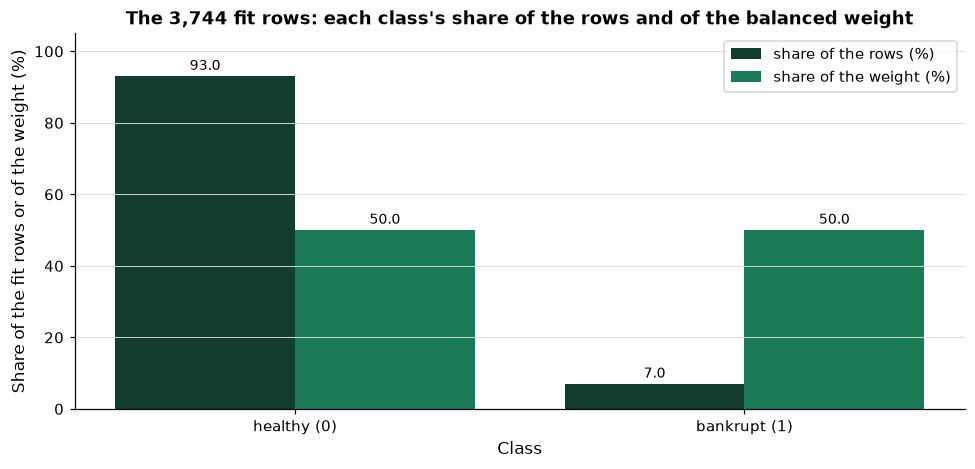

In [15]:
# each class's share of the fit rows and of the total weight, in percent
is_bankrupt = y_fit.to_numpy() == 1
shares = pd.DataFrame({
    "share of the rows (%)": {"healthy (0)": 100 * (~is_bankrupt).mean(), "bankrupt (1)": 100 * is_bankrupt.mean()},
    "share of the weight (%)": {"healthy (0)": 100 * row_weights[~is_bankrupt].sum() / row_weights.sum(),
                                "bankrupt (1)": 100 * row_weights[is_bankrupt].sum() / row_weights.sum()},
})
shares.index.name = "Class"
fig, ax = plt.subplots(figsize=(9, 4.4))
plotkit.bars(shares, f"The {len(y_fit):,} fit rows: each class's share of the rows and of the balanced weight",
             "Share of the fit rows or of the weight (%)", ax=ax, fmt="{:.1f}")
ax.set_ylim(0, 105)
plt.tight_layout()
plt.show()

* The dark bars are the rows, the green bars the weight. Bankrupt rows are 7.0 percent of the rows and 50.0 percent of the weight; healthy rows 93.0 and 50.0. The balanced weights level the two classes' totals; inside a class every row still counts the same.

## 10.2 What the Weights Do to the Loss and to the Output

Keras takes the weights as `fit(..., class_weight=weights)`. It turns them into one weight per row before training: Keras 3.15.1's `class_weight_to_sample_weights` (in `keras/src/trainers/data_adapters/data_adapter_utils.py`) gives each row the weight of its class. Each batch's loss is then the sum of weight times log loss over the batch's rows, divided by the number of rows (the default reduction `"sum_over_batch_size"`, in `keras/src/losses/loss.py`). Both read for this course on 2026-10-06.

Q. Add `output_vs_rate` to `netkit.py`, and its test, then run today's tests.

In [16]:
%%writefile -a netkit.py


def output_vs_rate(y, output) -> pd.Series:
    """The average of a network's outputs beside the outcome rate on the same rows.

    Inputs: y, the outcomes (0 or 1); output, the network's outputs on the same rows.
    Output: a Series with mean_output, outcome_rate, and ratio (mean_output / outcome_rate). A ratio near 1 is
    what a probability shows; a class-weighted network's ratio is well above 1, so its output is a score.
    Raises ValueError on lengths that differ, labels other than 0 and 1, or no row of class 1.
    """
    labels, scores = _labels_and_scores(y, output)
    if labels.sum() == 0:
        raise ValueError("y has no row of class 1, so the ratio is undefined")
    mean_output, rate = float(scores.mean()), float(labels.mean())
    return pd.Series({"mean_output": mean_output, "outcome_rate": rate, "ratio": mean_output / rate})

Appending to netkit.py


In [17]:
%%writefile -a test_netkit.py


def test_output_vs_rate_hand():
    table = netkit.output_vs_rate([0, 0, 0, 1], [0.1, 0.2, 0.3, 0.6])
    assert table.index.tolist() == ["mean_output", "outcome_rate", "ratio"]
    assert table.tolist() == pytest.approx([0.3, 0.25, 1.2], abs=1e-12)
    with pytest.raises(ValueError):
        netkit.output_vs_rate([0, 0], [0.1, 0.2])

Appending to test_netkit.py


In [18]:
importlib.reload(netkit)
print(f"balanced_class_weight and output_vs_rate in netkit: {hasattr(netkit, 'balanced_class_weight') and hasattr(netkit, 'output_vs_rate')}")

balanced_class_weight and output_vs_rate in netkit: True


In [19]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_netkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...........................................                              [100%]
43 passed in 12.06s



* `43 passed`: day 9's 40 and today's three.
* `output_vs_rate` puts a network's mean output beside the outcome rate on the same rows, with their ratio. A ratio near 1 is what a probability shows on the rows it was fitted for; well above 1, the output is a score.

Q. Prepare the rows as Course 4 did for this file, then fit the same network twice on the fit rows, once without weights and once with the balanced weights, stopping on the stopping rows.

In [20]:
# Course 4's preparation for this file: missing values filled with the fit rows' medians, a 0/1 column added for
# every column that had a gap, then each value mapped by its rank onto a normal curve
transformer = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                        ("quantile", QuantileTransformer(output_distribution="normal", random_state=SEED))])
# fit_arrays fits a copy on the fit rows only and transforms the stopping rows with it
fitted, A_fit, A_stop = netkit.fit_arrays(transformer, X_fit, X_stop)


def fit_network(A_fit, A_stop, class_weight=None, units=(16, 8), dropout=0.0):
    """A network of 16 and 8 units on the fit rows, early stopping on the stopping rows."""
    # dense_classifier sets the seed before it draws the starting weights
    model = netkit.dense_classifier(A_fit.shape[1], units=units, dropout=dropout)
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
    history = model.fit(A_fit, y_fit_32, validation_data=(A_stop, y_stop_32), epochs=200, batch_size=64,
                        class_weight=class_weight, callbacks=[stop], verbose=0)
    return model, history


plain, history_plain = fit_network(A_fit, A_stop)
weighted, history_weighted = fit_network(A_fit, A_stop, class_weight=weights)
print(f"inputs per company: {A_fit.shape[1]} ({X_fit.shape[1]} columns and {len(fitted.named_steps['impute'].indicator_.features_)} gap indicators)")
for name, history in [("no weights", history_plain), ("balanced weights", history_weighted)]:
    print(f"{name}: best epoch {netkit.best_epoch(history)} of {len(history.history['loss'])}")

inputs per company: 112 (64 columns and 48 gap indicators)
no weights: best epoch 30 of 40
balanced weights: best epoch 38 of 48


* The network has two hidden layers of 16 and 8 ReLU units, a quarter of the width of the course's default, without dropout, fitted at batch 64 with early stopping on the 936 stopping rows. The narrower width keeps every batch inside the course's size regime: with 112 inputs, a first layer of 64 units at batch 64 printed different digits on one thread and on every core when this notebook was built, and so did a class-weighted first layer of 32 units in some runs; 16 units did not. Both runs start from the same weights; only `class_weight` differs.
* 112 inputs per company: the 64 ratio columns and 48 gap indicators, one for each column with a missing value in the fit rows.

Q. Is Keras's weighted loss the weighted log loss you would work out by hand? Compare it on the fit rows, with the weighted network's outputs.

In [21]:
# the weighted network's outputs on the fit rows, and each row's log loss
# kept 1e-7 away from 0 and 1, as Keras keeps them before taking logarithms (day 1)
output_fit = np.clip(weighted.predict(A_fit, verbose=0).ravel().astype("float64"), 1e-7, 1 - 1e-7)
outcome = y_fit.to_numpy("float64")
row_loss = -(outcome * np.log(output_fit) + (1 - outcome) * np.log(1 - output_fit))

# by hand: weight times log loss, added up, over the sum of the weights (Excel's SUMPRODUCT over SUM)
weighted_loss = (row_weights * row_loss).sum() / row_weights.sum()
# Keras: the same rows, scored with one weight per row
keras_loss = weighted.evaluate(A_fit, y_fit_32, sample_weight=row_weights, verbose=0)
print(f"weighted mean log loss by hand: {weighted_loss:.6f}; Keras: {keras_loss:.6f}")
print(f"equal within 1e-6 (Keras works in float32): {abs(weighted_loss - keras_loss) < 1e-6}")
print(f"the same outputs, unweighted mean log loss: {row_loss.mean():.6f}")

# weights that do not add up to the number of rows: 1 for healthy, 5 for bankrupt
other = np.where(outcome == 1, 5.0, 1.0)
keras_other = float(keras.losses.BinaryCrossentropy()(y_fit_32[:, None], output_fit[:, None], sample_weight=other))
by_rows = (other * row_loss).sum() / len(other)
by_sum = (other * row_loss).sum() / other.sum()
print(f"weights 1 and 5: Keras {keras_other:.6f}; divided by the rows {by_rows:.6f}; divided by the sum of the weights {by_sum:.6f}")
print(f"Keras divides by: {'the number of rows' if abs(keras_other - by_rows) < 1e-6 else 'the sum of the weights'}")

weighted mean log loss by hand: 0.213971; Keras: 0.213971
equal within 1e-6 (Keras works in float32): True
the same outputs, unweighted mean log loss: 0.228344
weights 1 and 5: Keras 0.283352; divided by the rows 0.283352; divided by the sum of the weights 0.221568
Keras divides by: the number of rows


* With the balanced weights the two agree within 1e-6: 0.213971. Section 10.1 showed why: the balanced weights add up to the number of rows, so dividing by the rows and dividing by the sum of the weights are the same thing.
* With weights of 1 and 5 they are not the same. Keras returned 0.283352, the weighted sum divided by the number of rows; the weighted mean is 0.221568. Keras's weighted loss is a weighted sum scaled by the row count, so larger weights also mean a larger loss and larger gradients, much like a larger learning rate. The balanced weights keep the scale.

Q. Draw both networks' loss by epoch, on the fit rows and on the stopping rows, with the epoch early stopping kept.

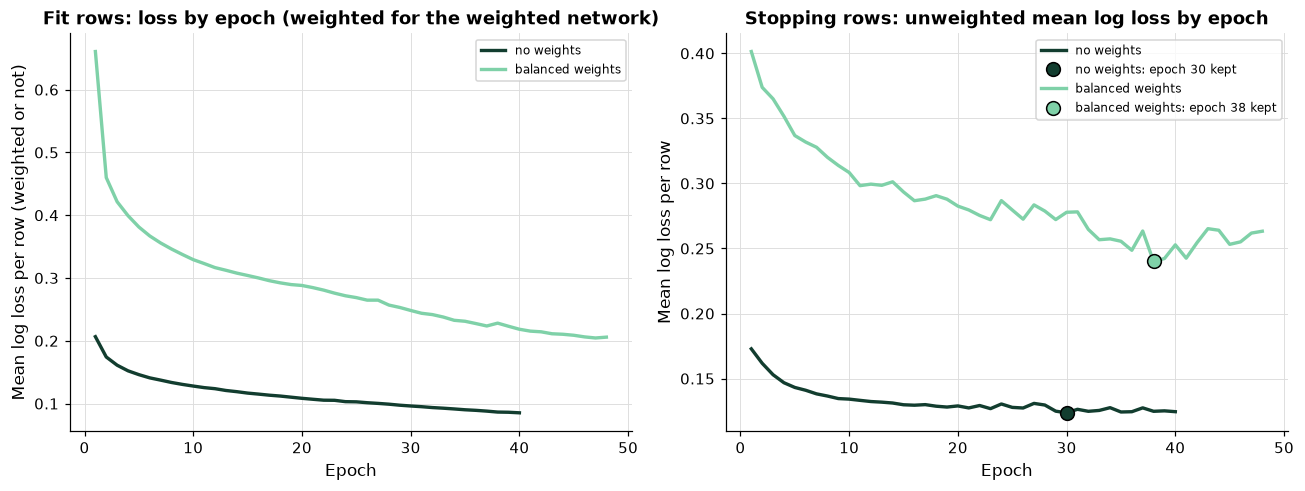

In [22]:
# the fit rows' loss is weighted for the weighted network; the stopping rows' loss is not (Keras applies
# class_weight to the rows it fits on, never to validation_data)
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.6))
for name, history, colour in [("no weights", history_plain, plotkit.GREEN_DARK),
                              ("balanced weights", history_weighted, plotkit.GREEN_LIGHT)]:
    record = netkit.history_table(history)
    kept = netkit.best_epoch(history)
    left.plot(record.index, record["loss"], color=colour, linewidth=2.2, label=name)
    right.plot(record.index, record["val_loss"], color=colour, linewidth=2.2, label=name)
    right.plot(kept, record.loc[kept, "val_loss"], "o", color=colour, markersize=9, markeredgecolor="black",
               label=f"{name}: epoch {kept} kept")
left.set_title("Fit rows: loss by epoch (weighted for the weighted network)")
left.set_ylabel("Mean log loss per row (weighted or not)")
right.set_title("Stopping rows: unweighted mean log loss by epoch")
right.set_ylabel("Mean log loss per row")
for ax in (left, right):
    ax.set_xlabel("Epoch")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

* Left: both fit losses fall for as long as each network runs, the weighted one to 0.2058 and the plain one to 0.0853; they are different losses, one weighted and one not, so the two lines are not compared by height.
* Right: the stopping rows carry no weights, so both curves are the plain mean log loss. The weighted network's lowest is 0.2400 at epoch 38, above the plain network's 0.1237 at epoch 30: its outputs sit higher than the bankrupt share, and an unweighted log loss charges for that. Early stopping on the weighted network therefore watched a loss the network was not fitted to lower.

Q. What did the weights do to the outputs? Score both networks on the stopping rows with `output_vs_rate`.

In [23]:
# both networks on the 936 stopping rows: mean output beside the bankrupt share, and how each ranks the companies
output_plain = plain.predict(A_stop, verbose=0).ravel()
output_weighted = weighted.predict(A_stop, verbose=0).ravel()
stopping_table = pd.DataFrame({name: {**netkit.output_vs_rate(y_stop, output),
                                      "roc_auc": roc_auc_score(y_stop, output),
                                      "average_precision": average_precision_score(y_stop, output)}
                               for name, output in [("no weights", output_plain), ("balanced weights", output_weighted)]}).T
# higher is better in the two ranking columns; the mean output and the ratio are not scores, so they are not marked
plotkit.styled(stopping_table, ["roc_auc", "average_precision"],
               f"The same network fitted twice on the fit rows, scored on the {len(y_stop):,} stopping rows", fmt="{:.4f}")

,mean_output,outcome_rate,ratio,roc_auc,average_precision
no weights,0.0682,0.0694,0.9826,0.9382,0.7331
balanced weights,0.1919,0.0694,2.7631,0.9436,0.7480


**Rows.** Every model on the Polish file in this notebook is fitted and scored inside Course 4's 4,680 training rows: in sections 10.1 and 10.2 on 3,744 fit rows with 936 stopping rows carved from them, and from section 10.3 by five folds, with a stratified fifth of each fold's training rows to stop on; Course 4's 1,170 test rows are never scored in this course.

* Without weights the network's mean output on the stopping rows is 0.0682, against a bankrupt share of 0.0694: a ratio of 0.9826. Its output can be read as the model probability of bankruptcy in this file.
* With the balanced weights the mean output is 0.1919, 2.7631 times the bankrupt share. The weights did what section 10.1 said they would: they pulled every output up. **The weighted network's output is the model's score**, not a probability, and no reading of it as a share of companies is right.
* The ranking moved much less than the average: average precision 0.7331 without weights and 0.7480 with them, ROC AUC 0.9382 and 0.9436, on 65 bankrupt companies. One split of 936 rows cannot say much about a gap like that; the case study asks five folds.
* One setting changed: `class_weight`, none to balanced; seen on the 936 stopping rows. Nothing is chosen here.

Q. Draw each network's outputs on the stopping rows, healthy and bankrupt companies apart.

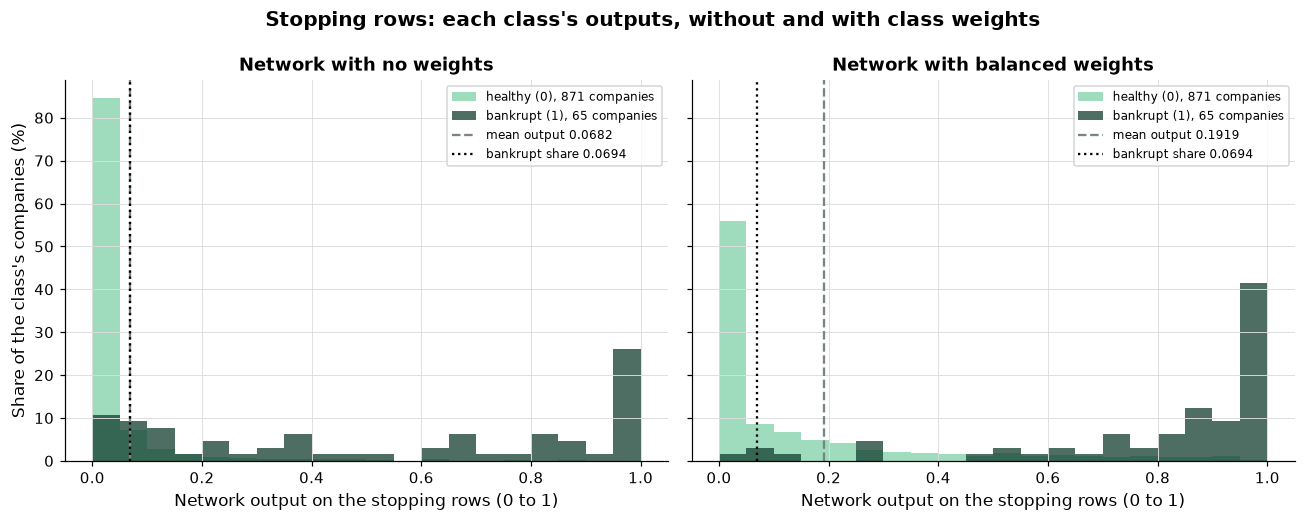

In [24]:
# each class's outputs in 20 bins from 0 to 1; each class's bars add up to 100 percent of its companies
bins = np.linspace(0, 1, 21)
outcome = y_stop.to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, (name, output) in zip(axes, [("no weights", output_plain), ("balanced weights", output_weighted)]):
    for value, label, colour in [(0, "healthy (0)", plotkit.GREEN_LIGHT), (1, "bankrupt (1)", plotkit.GREEN_DARK)]:
        part = output[outcome == value]
        ax.hist(part, bins=bins, weights=np.full(len(part), 100 / len(part)), color=colour, alpha=0.75,
                label=f"{label}, {len(part)} companies")
    ax.axvline(output.mean(), color=plotkit.GREY, linestyle="--", linewidth=1.5, label=f"mean output {output.mean():.4f}")
    ax.axvline(outcome.mean(), color="black", linestyle=":", linewidth=1.5, label=f"bankrupt share {outcome.mean():.4f}")
    ax.set_title(f"Network with {name}")
    ax.set_xlabel("Network output on the stopping rows (0 to 1)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Share of the class's companies (%)")
fig.suptitle("Stopping rows: each class's outputs, without and with class weights", fontweight="bold")
fig.tight_layout()
plt.show()

* Without weights, 84.6 percent of the healthy companies get an output below 0.05 (the first light bar); with the balanced weights, 56.0 percent do. The weights moved the healthy companies' outputs to the right, and the dashed mean line with them, away from the dotted bankrupt share.
* At 0.5, the weighted network puts 87.7 percent of the bankrupt companies above the line against 52.3 percent, and 10.2 percent of the healthy ones against 0.7 percent. Both classes moved; that is why the ranking moved so much less than the average.

Q. The balanced weights put 13.3 times the weight on a bankrupt company that a healthy one gets. Is that the right size? Fit the same network with five ratios, 1 (no weighting) to 40, with the weights always adding up to the number of fit rows, and see what each does to the outputs.

,mean output,mean output over the bankrupt share,roc_auc,average_precision,recall at 0.5,share flagged at 0.5
weight on bankrupt relative to healthy,,,,,,
1,0.0682,0.9826,0.9382,0.7331,0.5231,0.0427
2,0.0840,1.2097,0.9366,0.7174,0.5538,0.0513
5,0.1362,1.9609,0.9360,0.6709,0.6308,0.0812
13.3 (balanced),0.1919,2.7631,0.9436,0.7480,0.8769,0.1560
40,0.2084,3.0016,0.9213,0.6911,0.8308,0.1966


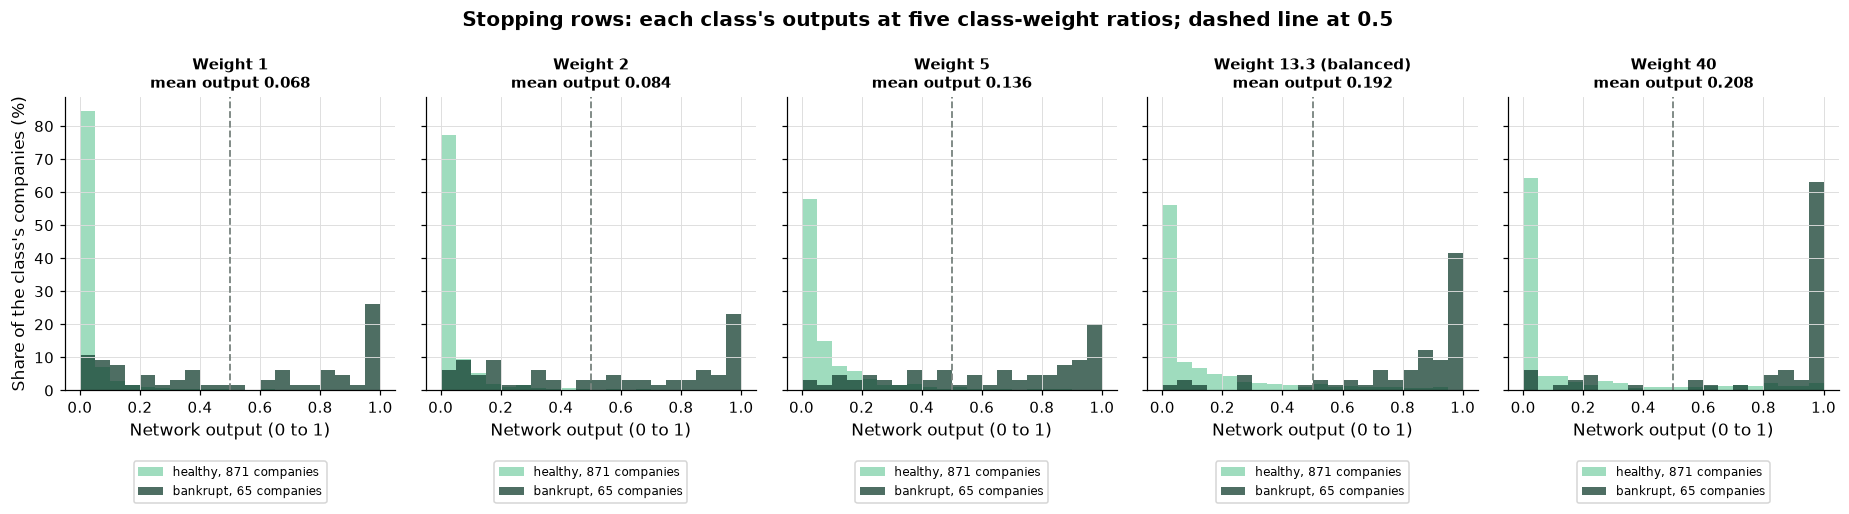

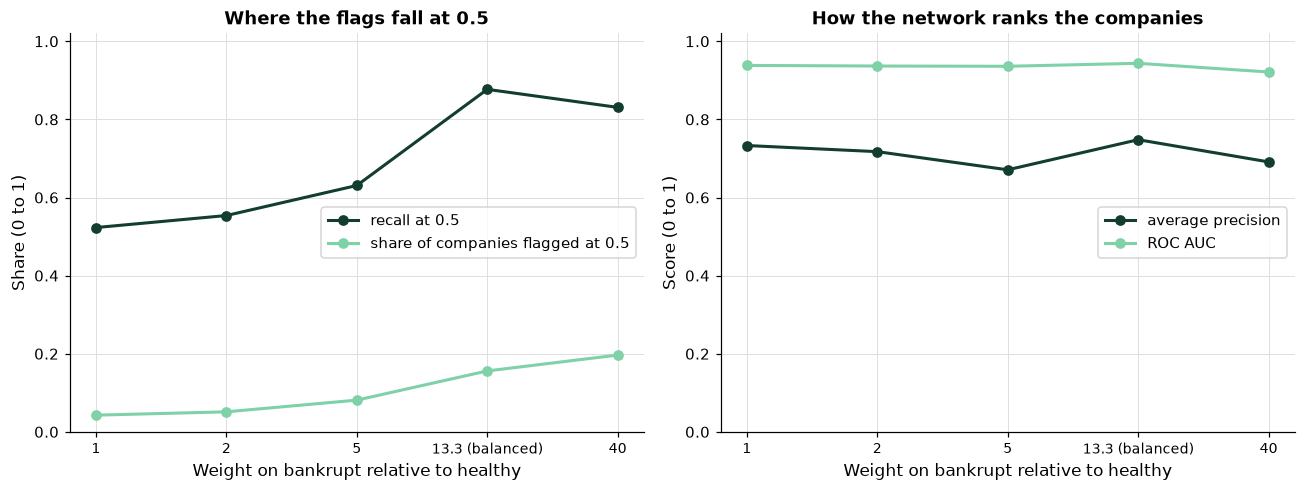

In [25]:
def weights_for_ratio(y, ratio):
    """Class weights with bankrupt : healthy equal to ratio, scaled to add up to the number of rows, as the balanced ones do."""
    n_healthy, n_bankrupt = int((y == 0).sum()), int((y == 1).sum())
    healthy = len(y) / (n_healthy + ratio * n_bankrupt)
    return {0: healthy, 1: ratio * healthy}


# the balanced weights are the ratio (n healthy) / (n bankrupt); the sweep brackets it
ratios = [1.0, 2.0, 5.0, weights[1] / weights[0], 40.0]
actual = y_stop.to_numpy()
sweep_outputs, sweep_rows = {}, {}
for ratio in ratios:
    network, _ = fit_network(A_fit, A_stop, class_weight=weights_for_ratio(y_fit, ratio))
    output = network.predict(A_stop, verbose=0).ravel()
    sweep_outputs[ratio] = output
    flag = output >= 0.5
    sweep_rows[ratio] = {"mean output": output.mean(), "mean output over the bankrupt share": output.mean() / actual.mean(),
                         "roc_auc": roc_auc_score(actual, output), "average_precision": average_precision_score(actual, output),
                         "recall at 0.5": (flag & (actual == 1)).sum() / (actual == 1).sum(), "share flagged at 0.5": flag.mean()}
sweep_table = pd.DataFrame(sweep_rows).T
sweep_table.index = [f"{ratio:.1f} (balanced)" if k == 3 else f"{ratio:g}" for k, ratio in enumerate(ratios)]
sweep_table.index.name = "weight on bankrupt relative to healthy"
# higher is better for the two ranking columns; the output, recall, and flag columns describe an operating point, not a score
display(plotkit.styled(sweep_table, ["roc_auc", "average_precision"],
                       f"The 16 and 8 network at five class-weight ratios, scored on the {len(y_stop):,} stopping rows",
                       fmt="{:.4f}"))

fig, axes = plt.subplots(1, 5, figsize=(17, 5.0), sharey=True)
bins = np.linspace(0, 1, 21)
for axis, (ratio, output), label in zip(axes, sweep_outputs.items(), sweep_table.index):
    for value, name, colour in [(0, "healthy", plotkit.GREEN_LIGHT), (1, "bankrupt", plotkit.GREEN_DARK)]:
        part = output[actual == value]
        # each class's bars add up to 100 percent of its companies
        axis.hist(part, bins=bins, weights=np.full(len(part), 100 / len(part)), color=colour, alpha=0.75, label=f"{name}, {len(part)} companies")
    axis.axvline(0.5, color=plotkit.GREY, linestyle="--", linewidth=1.2)
    axis.set_title(f"Weight {label}\nmean output {output.mean():.3f}", fontsize=10)
    axis.set_xlabel("Network output (0 to 1)")
    # the legend under the panel, where it covers no bar
    axis.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22))
axes[0].set_ylabel("Share of the class's companies (%)")
fig.suptitle("Stopping rows: each class's outputs at five class-weight ratios; dashed line at 0.5", fontweight="bold")
fig.tight_layout()
plt.show()

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.6))
positions = np.arange(len(sweep_table))
left.plot(positions, sweep_table["recall at 0.5"], marker="o", color=plotkit.GREEN_DARK, linewidth=2, label="recall at 0.5")
left.plot(positions, sweep_table["share flagged at 0.5"], marker="o", color=plotkit.GREEN_LIGHT, linewidth=2, label="share of companies flagged at 0.5")
right.plot(positions, sweep_table["average_precision"], marker="o", color=plotkit.GREEN_DARK, linewidth=2, label="average precision")
right.plot(positions, sweep_table["roc_auc"], marker="o", color=plotkit.GREEN_LIGHT, linewidth=2, label="ROC AUC")
for axis in (left, right):
    axis.set_xticks(positions, labels=sweep_table.index, fontsize=9)
    axis.set_xlabel("Weight on bankrupt relative to healthy")
    axis.set_ylim(0, 1.02)
    axis.legend(loc="center right")
left.set_title("Where the flags fall at 0.5")
left.set_ylabel("Share (0 to 1)")
right.set_title("How the network ranks the companies")
right.set_ylabel("Score (0 to 1)")
fig.tight_layout()
plt.show()

* **How to read the grid.** Each panel is one ratio, fitted on the same rows with the same seed. As the ratio rises the bankrupt companies' outputs (dark) slide toward 1, and so do the healthy companies' (light): the mean output goes from 0.0682 with no weighting, 0.98 times the bankrupt share, to 0.2084, 3.0 times it, at a ratio of 40. The weights move every output up; they are a way to move the operating point.
* **The flags follow, the ranking does not.** At 0.5 the share of companies flagged rises at every step, from 4.3 percent to 19.7 percent, and recall from 52.3 percent at no weighting to 87.7 percent at the balanced ratio. Average precision and ROC AUC wander without a trend, average precision between 0.6709 and 0.7480 on 65 bankrupt companies: a spread that size is what one fit's noise looks like.
* **Which ratio.** The picture does not choose one, because the ranking scores do not move with it. What the weights buy is flags at a threshold of 0.5 without lowering the threshold; the case study asks whether that beats lowering the threshold on an unweighted network (section 10.6). Five single fits on one carve of 936 stopping rows: one setting changed across the panels, the ratio.

### Every setting of `fit`

`fit` has 16 settings. Most were met earlier in the course: `batch_size` and `epochs` on day 4, `callbacks` on day 9. `class_weight` is today's. The table lists all of them with the default read from Keras's own signature, what each controls, and what raising and lowering it does. Two are left unused by the course: `validation_split`, because the stopping rows are carved by `ensemblekit.early_stopping_rows` and passed as `validation_data`, and `sample_weight`, because weights go in by class.

Q. Build the table from Keras itself.

In [26]:
import inspect

# the defaults come from the installed Keras's own signature, so they are never typed
signature = inspect.signature(keras.Model.fit)
defaults = {name: ("required" if p.default is p.empty else repr(p.default)) for name, p in signature.parameters.items()
            if name not in ("self", "kwargs")}

# setting: (what it controls, raising it, lowering it, tune first)
notes = {
    'x': ('the inputs: arrays, here the fit rows', 'n/a', 'n/a', ''),
    'y': ('the targets: the outcomes of the same rows', 'n/a', 'n/a', ''),
    'batch_size': ('rows per gradient step; None means 32', 'fewer, smoother steps per epoch (day 4)', 'more, noisier steps', 'tune first'),
    'epochs': ('passes over the fit rows', 'a longer fit, until early stopping ends it', 'a shorter fit', 'tune first'),
    'verbose': ("what `fit` prints: 'auto' prints a progress bar", 'the course passes 0, so nothing is printed', '0 is silent', ''),
    'callbacks': ('objects `fit` consults each epoch, such as early stopping (day 9)', 'more of them', 'None: none', 'tune first'),
    'validation_split': ('the share of the rows taken off the end to validate on, never fitted; the course does not use it', 'more rows held back', '0.0 holds none back', ''),
    'validation_data': ('rows whose loss is recorded each epoch, never fitted; the course passes the stopping rows here', 'a choice of rows', 'None records no validation loss', 'tune first'),
    'shuffle': ('whether the fit rows are reshuffled each epoch', 'True: a different order every epoch', 'False: the same order', ''),
    'class_weight': ("a weight for each class's rows in the loss; None weights every row 1", 'rare-class rows count more: the outputs rise and more rows are flagged at 0.5', 'None: every row counts the same', 'tune first'),
    'sample_weight': ('a weight for each row, as an array; None weights every row 1', 'that row counts more', 'None: every row counts the same', ''),
    'initial_epoch': ('the epoch to start counting from, for resuming a fit', 'a later start', '0 starts at the first', ''),
    'steps_per_epoch': ('the number of steps that make an epoch; None runs through all the rows', 'longer epochs', 'shorter epochs', ''),
    'validation_steps': ('the number of validation steps; None runs through all the validation rows', 'more', 'fewer', ''),
    'validation_batch_size': ('rows per validation batch; None uses `batch_size`', 'a choice', 'a choice', ''),
    'validation_freq': ('run validation every this many epochs; 1 is every epoch', 'validates less often', '1 validates every epoch', ''),
}
# every setting Keras has is described, and nothing else
assert set(notes) == set(defaults)

fit_settings = pd.DataFrame({name: [defaults[name], *notes[name]] for name in defaults},
                            index=["default", "what it controls", "raising it", "lowering it", "tune first"]).T
fit_settings.index.name = "setting"
print(f"fit has {len(defaults)} settings; the defaults are read from the installed Keras")
# a table of words: nothing is marked
plotkit.styled(fit_settings, [], "Every setting of keras.Model.fit: its default, what it controls, and what raising or lowering it does")

fit has 16 settings; the defaults are read from the installed Keras


,default,what it controls,raising it,lowering it,tune first
setting,,,,,
x,None,"the inputs: arrays, here the fit rows",n/a,n/a,
y,None,the targets: the outcomes of the same rows,n/a,n/a,
batch_size,None,rows per gradient step; None means 32,"fewer, smoother steps per epoch (day 4)","more, noisier steps",tune first
epochs,1,passes over the fit rows,"a longer fit, until early stopping ends it",a shorter fit,tune first
verbose,'auto',what `fit` prints: 'auto' prints a progress bar,"the course passes 0, so nothing is printed",0 is silent,
callbacks,None,"objects `fit` consults each epoch, such as early stopping (day 9)",more of them,None: none,tune first
validation_split,0.0,"the share of the rows taken off the end to validate on, never fitted; the course does not use it",more rows held back,0.0 holds none back,
validation_data,None,"rows whose loss is recorded each epoch, never fitted; the course passes the stopping rows here",a choice of rows,None records no validation loss,tune first
shuffle,True,whether the fit rows are reshuffled each epoch,True: a different order every epoch,False: the same order,


* 16 settings. `class_weight` defaults to `None`: every row counts 1. It acts during training only; the stopping rows' loss, recorded through `validation_data`, is never weighted, which is why section 10.2's right-hand loss curves were plain mean log losses.
* **Tune first:** `batch_size` and `epochs` (day 4), `callbacks` (day 9), `validation_data` (the stopping rows), and `class_weight`. The ratio sweep above is `class_weight`'s sweep.

## Case Study: Class Weights on Bankruptcy

### Context

Course 4's capstone fitted a logistic regression with balanced class weights to this file and opened its test rows once. Course 5's week 3 cross-validated boosters on the same 4,680 training rows and found LightGBM with its default settings ranked the companies best, by average precision. Days 6 to 9 of this course trained networks one setting at a time. A colleague asks the question this case study answers: **on this file, does a network rank the bankrupt companies as well as the models already on the desk, should it be fitted with class weights, and where does it fail?**

The answer is a description of a historical, anonymised dataset. It is not a credit view on any company, and it says nothing about what anyone should do.

### Objective

1. Prepare the rows as Course 4 did, and fit every network by five folds inside the 4,680 training rows, with stopping rows carved from each fold.
2. Change one setting at a time: at most three configurations, the last of them class weights.
3. Compare class weights against no weights against a lower threshold, by average precision and by precision at recall 0.70 from out-of-fold outputs.
4. Score Course 4's logistic regression and Course 5's LightGBM by the same folds, and put a bootstrap interval on each pooled average precision and on the paired differences.
5. Write a results workbook, and what the model shows and where it fails. Promise nothing in advance: the numbers decide what can be said.

**The test rows are not opened.** On this file every reported number is out of fold, inside the training rows.

### The data dictionary

The dataset page's "Additional Variable Information" defines the 64 features in words. These definitions are quoted from the course's `DATA.md`, which records them: "X1 net profit / total assets", "X2 total liabilities / total assets", "X10 equity / total assets", "X17 total assets / total liabilities", "X29 logarithm of total assets", "X55 working capital". The file names the features `Attr1` to `Attr64`, and the course reads `Attr`k as Xk by position (DATA.md gives the evidence: `Attr17` equals 1 / `Attr2` on every row but one, as X17 and X2 say it should). So `Attr1` is net profit over total assets and `Attr2` is total liabilities over total assets.

**What the documentation leaves open**, as Course 4 found: not every feature is a ratio (`Attr29` is a logarithm of total assets in a base the page does not state; `Attr55` is working capital in a currency it does not state), the page does not say how companies were chosen, and it does not say whether a company appears more than once.

**Place and period.** The companies are Polish, and the statements come from the 2000s and early 2010s: corporate credit there and then differs from US credit today, and nothing here describes any other country, period, or company.

## 10.3 Overview: the Rows This Course May Use

Course 4's capstone described the whole file: the missing values, the duplicates, the extreme values. That work is not repeated here: open Course 4's capstone notebook for it. This section describes only the rows the networks may use, and how the five folds cut them.

Q. How many bankrupt companies does each fold hold, and how many gaps are in the training rows?

In [27]:
# the five folds every model today is scored on: mlkit's stratified five folds, seed 42
fold_counts = pd.DataFrame([{"rows": len(held), "bankrupt": int(y_train.iloc[held].sum())}
                            for _, held in mlkit.cv_folds().split(X_train, y_train)],
                           index=[f"fold_{k}" for k in range(1, 6)])
print(fold_counts.to_string())
print(f"missing cells in the training rows: {X_train.isna().sum().sum():,} in {X_train.isna().any().sum()} of "
      f"{X_train.shape[1]} columns; rows with at least one gap: {X_train.isna().any(axis=1).sum():,}")

        rows  bankrupt
fold_1   936        65
fold_2   936        65
fold_3   936        65
fold_4   936        65
fold_5   936        66
missing cells in the training rows: 3,648 in 48 of 64 columns; rows with at least one gap: 2,248


* Each fold holds 936 or 936 companies and 65 or 66 bankruptcies. A fold's average precision rests on about 65 bankrupt companies, so it moves a lot from fold to fold; that is why the case study reports the fold mean with its spread, and pools the out-of-fold outputs for thresholds and intervals.
* 3,648 missing cells in 48 columns, and 2,248 of the 4,680 rows have at least one. A network cannot take a gap, which is why the preparation fills them.

## 10.4 Preparation

The preparation is Course 4's for this file, kept so the comparison is about the model and not the inputs: `SimpleImputer(strategy="median", add_indicator=True)` fills each gap with the fit rows' median and adds a 0/1 column for every column that had a gap, then `QuantileTransformer(output_distribution="normal")` maps each value by its rank among the fit rows onto a normal curve. Some of these columns run into the millions (the file's largest value, in `Attr60`, is above 4.8 million, as `DATA.md` records); after the quantile step no value sits far out, which a network needs. `cv_network` fits a fresh copy of the pipeline on each fold's fit rows, through `fit_arrays`, so no held-out company ever sets a median or a rank. Section 10.2's 112 inputs are what it gives.

## 10.5 Model Building by Five Folds

Model 1 is section 10.2's network: 16 and 8 ReLU units without dropout, batch 64, early stopping with patience 10 on a stratified fifth of each fold's training rows. Model 2 changes one setting, the dropout: none to 0.2 after each hidden layer, the rate day 9 used (there beside L2 at 0.001).

**The rule, set before any fold is scored:** a change is kept only if it raises the fold-mean average precision **and** is ahead on at least 4 of the 5 folds. The folds are the same for every model, so each fold's two numbers are a pair; with about 65 bankrupt companies per fold, a higher mean alone can come from one fold.

Q. Run `cv_network` for Model 1 and Model 2.

In [28]:
def model_1(n_inputs):
    """Model 1: 16 and 8 units, no dropout."""
    return netkit.dense_classifier(n_inputs, units=(16, 8), dropout=0.0)


def model_2(n_inputs):
    """Model 2: one setting changed, the dropout: 0.2."""
    return netkit.dense_classifier(n_inputs, units=(16, 8), dropout=0.2)


# five folds; inside each, stopping rows carved from the fold and the pipeline fitted on its fit rows
table_1, oof_1 = netkit.cv_network(model_1, transformer, X_train, y_train)
table_2, oof_2 = netkit.cv_network(model_2, transformer, X_train, y_train)
# one row per fold; nothing is marked: the folds are five sets of rows, not five choices
display(plotkit.styled(table_1, [], "Model 1 (16 and 8 units, no dropout), by fold: each fold scored on its own held-out "
                       "training rows", fmt="{:.4f}"))
plotkit.styled(table_2, [], "Model 2 (16 and 8 units, dropout 0.2), by fold: the same five folds", fmt="{:.4f}")

,roc_auc,average_precision,best_epoch,epochs_run
fold_1,0.9372,0.6815,50,60
fold_2,0.9364,0.7470,19,29
fold_3,0.9056,0.7102,30,40
fold_4,0.9382,0.7354,23,33
fold_5,0.9387,0.7680,33,43


,roc_auc,average_precision,best_epoch,epochs_run
fold_1,0.9337,0.6949,45,55
fold_2,0.9572,0.7474,46,56
fold_3,0.9020,0.5882,20,30
fold_4,0.9325,0.6845,37,47
fold_5,0.9421,0.7581,51,61


Q. Put the two side by side, and apply the rule.

In [29]:
ladder = pd.DataFrame({
    "units": {"Model 1": "(16, 8)", "Model 2": "(16, 8)"},
    "dropout": {"Model 1": 0.0, "Model 2": 0.2},
    "fold_mean_ap": {"Model 1": table_1["average_precision"].mean(), "Model 2": table_2["average_precision"].mean()},
    "fold_sd_ap": {"Model 1": table_1["average_precision"].std(ddof=0), "Model 2": table_2["average_precision"].std(ddof=0)},
    "pooled_ap": {"Model 1": average_precision_score(y_train, oof_1), "Model 2": average_precision_score(y_train, oof_2)},
    "pooled_roc_auc": {"Model 1": roc_auc_score(y_train, oof_1), "Model 2": roc_auc_score(y_train, oof_2)},
})
ahead = int((table_2["average_precision"] > table_1["average_precision"]).sum())
kept = ladder.loc["Model 2", "fold_mean_ap"] > ladder.loc["Model 1", "fold_mean_ap"] and ahead >= 4
print(f"folds where Model 2 is ahead: {ahead} of 5; the change is {'kept' if kept else 'not kept'}")

# the chosen network's build and its out-of-fold outputs
chosen_build, table_network, oof_network = (model_2, table_2, oof_2) if kept else (model_1, table_1, oof_1)
# higher is better in the three score columns; the fold spread is not a score, so it is not marked
plotkit.styled(ladder, ["fold_mean_ap", "pooled_ap", "pooled_roc_auc"],
               f"Model 1 against Model 2, scored by five folds inside the {len(y_train):,} training rows",
               fmt="{:.4f}").format("{:g}", subset=["dropout"])

folds where Model 2 is ahead: 2 of 5; the change is not kept


,units,dropout,fold_mean_ap,fold_sd_ap,pooled_ap,pooled_roc_auc
Model 1,"(16, 8)",0,0.7284,0.0300,0.7206,0.9270
Model 2,"(16, 8)",0.2,0.6946,0.0604,0.6899,0.9323


* Model 1's fold average precision runs from 0.6815 to 0.7680, mean 0.7284 with a standard deviation of 0.0300; early stopping chose between epoch 19 and epoch 50. Model 2's mean is 0.6946, and it is ahead on 2 of the 5 folds. **Not kept: Model 1 stands.**
* One setting changed from Model 1: the dropout, 0.0 to 0.2; chosen by five folds inside the 4,680 training rows. Not kept.
* Model 2's mean is 0.0338 lower, more than Model 1's fold standard deviation of 0.0300. On this file, dropout of 0.2 on layers of 16 and 8 units did not help.
* The marked cells: Model 1 has the higher fold mean and pooled average precision, Model 2 the higher pooled ROC AUC (0.9323 against 0.9270). The rule reads average precision, set before any fold was scored, so the ROC AUC does not reopen the choice.

Q. Draw each fold's average precision for both models.

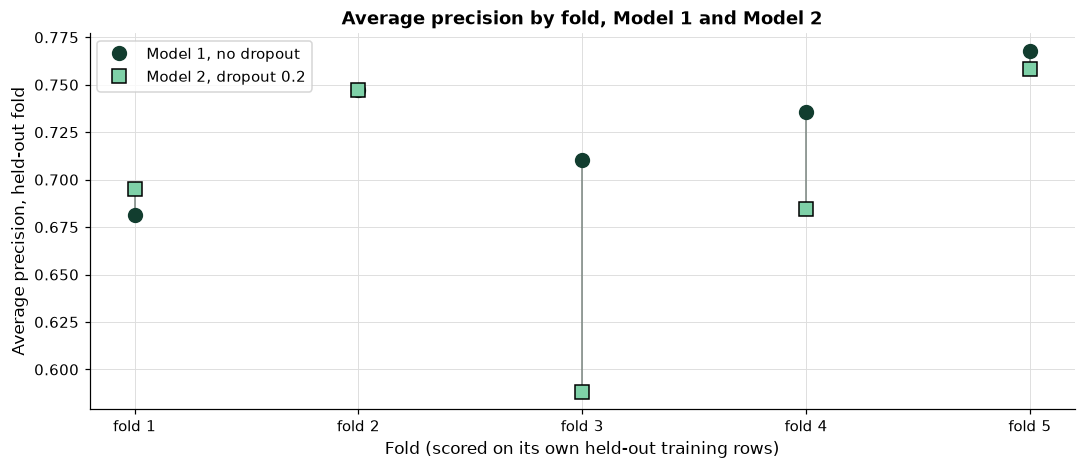

In [30]:
# the folds are pairs: the same held-out rows scored twice, so a line joins each fold's two points
fold_ap = pd.DataFrame({"Model 1": table_1["average_precision"], "Model 2": table_2["average_precision"]})
positions = np.arange(1, len(fold_ap) + 1)
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.vlines(positions, fold_ap.min(axis=1), fold_ap.max(axis=1), color=plotkit.GREY, linewidth=1)
ax.plot(positions, fold_ap["Model 1"], "o", color=plotkit.GREEN_DARK, markersize=9, label="Model 1, no dropout")
ax.plot(positions, fold_ap["Model 2"], "s", color=plotkit.GREEN_LIGHT, markersize=9, markeredgecolor="black",
        label="Model 2, dropout 0.2")
ax.set_xticks(positions, labels=[f"fold {k}" for k in positions])
ax.set_title("Average precision by fold, Model 1 and Model 2")
ax.set_xlabel("Fold (scored on its own held-out training rows)")
ax.set_ylabel("Average precision, held-out fold")
ax.legend()
plt.tight_layout()
plt.show()

* The light square is above the dark dot on 2 folds, by at most 0.0134; on fold 3 it is 0.1220 below, more than twice Model 1's fold standard deviation. The rule's "at least 4 of 5" exists for this picture: a mean can move on one fold, a count of folds cannot.

## 10.6 Class Weights Against None Against a Lower Threshold

**How it works.** There are two ways to catch more bankrupt companies. **Weighting** changes the network: bankrupt rows count more in the loss, so every fitted output rises. **A lower threshold** leaves the network alone and flags every company whose output reaches a lower cut. Both move the operating point along the same trade between recall and precision; only weighting changes the fitted network, so only it can change the ranking. You control the weights and the threshold; here every threshold is chosen on out-of-fold outputs for recall 0.70, so the two are compared at the same recall. What comes out is, for each, the pooled average precision and the precision at recall 0.70. Section 10.2 showed what the weights do to one split. Model 3 is Model 1 with the balanced class weights, by the same five folds. This section puts the two ways side by side, with every threshold chosen on out-of-fold outputs.

Q. Run `cv_network` for Model 3, with the balanced weights of the 4,680 training rows.

In [31]:
# Model 3: Model 1 with the balanced class weights of the training rows
train_weights = netkit.balanced_class_weight(y_train)
table_weighted, oof_weighted = netkit.cv_network(chosen_build, transformer, X_train, y_train, class_weight=train_weights)
# one row per fold, nothing marked
display(plotkit.styled(table_weighted, [], "Model 3 (Model 1 with balanced class weights), by fold: the same five folds",
                       fmt="{:.4f}"))

# the weights each fold's own fit rows would give, against the training rows' weights
fold_gaps = []
for train, held in mlkit.cv_folds().split(X_train, y_train):
    fold_fit_outcomes = ensemblekit.early_stopping_rows(X_train.iloc[train], y_train.iloc[train])[2]
    fold_weights = netkit.balanced_class_weight(fold_fit_outcomes)
    fold_gaps.append(max(abs(fold_weights[k] - train_weights[k]) for k in (0, 1)))
print(f"weights from the training rows: healthy {train_weights[0]:.4f}, bankrupt {train_weights[1]:.4f}; "
      f"largest difference from a fold's own fit rows: {max(fold_gaps):.4f}")

,roc_auc,average_precision,best_epoch,epochs_run
fold_1,0.9256,0.6237,22,32
fold_2,0.9440,0.7191,29,39
fold_3,0.8752,0.6889,58,68
fold_4,0.9269,0.6304,24,34
fold_5,0.9325,0.7511,60,70


weights from the training rows: healthy 0.5374, bankrupt 7.1779; largest difference from a fold's own fit rows: 0.0216


* Model 3's fold-mean average precision is 0.6826, against Model 1's 0.7284; it is below Model 1 on 5 of the 5 folds.
* The weights come from the outcomes of all 4,680 training rows, held-out folds included. Because the folds are stratified, each fold's own fit rows would give weights within 0.0216 of these, so the shortcut moves nothing that matters; the weights carry the class counts, never a company's values.
* One setting changed from Model 1: the class weights, none to balanced; chosen by five folds inside the 4,680 training rows.

Q. Flag the companies four ways: each network at 0.5, and each at its own threshold for recall 0.70 from its out-of-fold outputs.

In [32]:
threshold_network = mlkit.threshold_for_recall(y_train, oof_network, 0.70)
threshold_weighted = mlkit.threshold_for_recall(y_train, oof_weighted, 0.70)


def flag_row(output, threshold):
    """Recall, precision, and the number flagged, at one threshold, on the pooled out-of-fold outputs."""
    flags = (output >= threshold).astype(int)
    metrics = mlkit.classification_metrics(y_train, flags)
    return {"threshold": threshold, "recall": metrics["recall"], "precision": metrics["precision"], "flagged": int(flags.sum())}


class_weight_table = pd.DataFrame.from_dict({
    "network at 0.5": flag_row(oof_network, 0.5),
    "network at recall 0.70": flag_row(oof_network, threshold_network),
    "weighted network at 0.5": flag_row(oof_weighted, 0.5),
    "weighted network at recall 0.70": flag_row(oof_weighted, threshold_weighted),
}, orient="index")
# nothing is marked: the four rows sit at different thresholds, so no column ranks them
display(plotkit.styled(class_weight_table, [], f"Four ways of flagging the {len(y_train):,} training rows, on pooled "
                       "out-of-fold outputs", fmt="{:.4f}"))
for name, output in [("network", oof_network), ("weighted network", oof_weighted)]:
    summary = netkit.output_vs_rate(y_train, output)
    print(f"{name}: pooled out-of-fold average precision {average_precision_score(y_train, output):.4f}, "
          f"mean output {summary['mean_output']:.4f} against a bankrupt share of {summary['outcome_rate']:.4f}")

,threshold,recall,precision,flagged
network at 0.5,0.5000,0.5276,0.8557,201
network at recall 0.70,0.1741,0.7025,0.5797,395
weighted network at 0.5,0.5000,0.7454,0.4508,539
weighted network at recall 0.70,0.6073,0.7025,0.5078,451


network: pooled out-of-fold average precision 0.7206, mean output 0.0644 against a bankrupt share of 0.0697
weighted network: pooled out-of-fold average precision 0.6732, mean output 0.1583 against a bankrupt share of 0.0697


* **At 0.5**, the unweighted network catches 52.8 percent of the bankrupt companies and the weighted one 74.5 percent. This is what class weights are usually used for: at the default threshold of 0.5 they catch more.
* **At the threshold for recall 0.70**, chosen on each network's own out-of-fold outputs, both catch the same share, and the unweighted network does it with fewer false flags: it flags 395 companies at a precision of 0.5797, against 451 at 0.5078 for the weighted one. Lowering the unweighted network's threshold, to 0.1741, does the job the weights do at 0.5, and keeps the better ranking.
* The weighted network's threshold, 0.6073, is on the scale of a score: its mean output is 0.1583, 2.27 times the bankrupt share, while the unweighted network's is 0.0644.
* **The decision, by the numbers:** no class weights. They did not raise average precision (0.7206 pooled without, 0.6732 with; section 10.8 asks whether that gap is more than noise), and a threshold chosen on out-of-fold outputs gets the recall the desk asks for without them.

Q. Draw the four ways as confusion matrices.

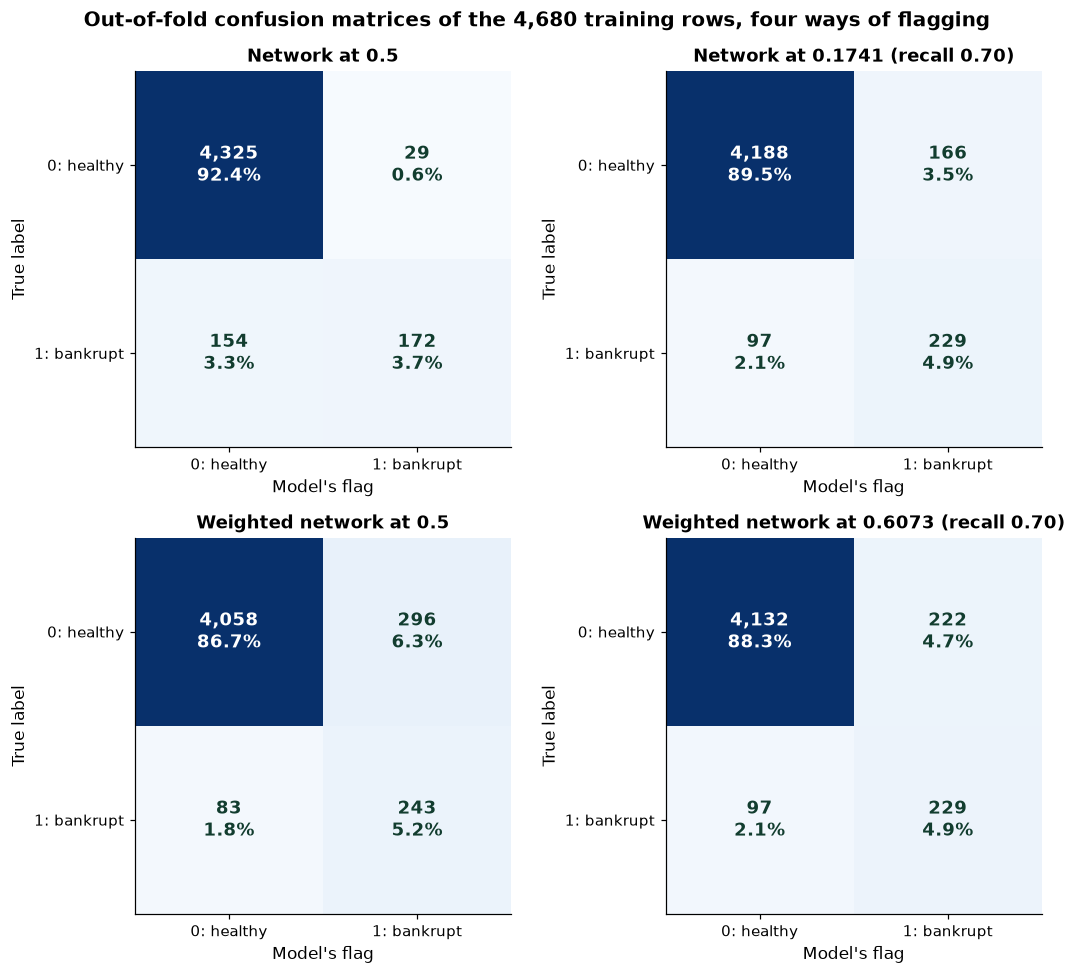

In [33]:
# the names of class 0 and class 1, used on every heatmap today
labels = ("0: healthy", "1: bankrupt")
ways = [("Network at 0.5", oof_network, 0.5),
        (f"Network at {threshold_network:.4f} (recall 0.70)", oof_network, threshold_network),
        ("Weighted network at 0.5", oof_weighted, 0.5),
        (f"Weighted network at {threshold_weighted:.4f} (recall 0.70)", oof_weighted, threshold_weighted)]
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for ax, (title, output, threshold) in zip(axes.ravel(), ways):
    plotkit.confusion_heatmap(y_train, (output >= threshold).astype(int), title, labels, ax=ax)
fig.suptitle(f"Out-of-fold confusion matrices of the {len(y_train):,} training rows, four ways of flagging",
             fontweight="bold")
fig.tight_layout()
plt.show()

* Top row, the unweighted network: at 0.5 it flags 172 bankrupt companies and 29 healthy ones; at its threshold for recall 0.70, 229 and 166.
* Bottom row, the weighted network: at 0.5, 243 and 296; at its threshold, 229 and 222. The two right-hand panels catch the same 229 bankruptcies; the top one does it with 56 fewer healthy companies flagged (the top right cell of each panel).

## 10.7 The Comparison, by the Same Folds

Course 5's LightGBM with its default settings ranked these companies best in Course 5's week 3, and Course 4's capstone model was a logistic regression with balanced class weights, prepared the same way as the networks. Both are scored here by the same five folds, through `ensemblekit.oof_threshold`, which also gives each its threshold for recall 0.70.

Q. Score both by the same folds, and put all four models in one table.

In [34]:
from lightgbm import LGBMClassifier
from sklearn.linear_model import LogisticRegression

# Course 5's LightGBM with its defaults (it takes the gaps as they are) and Course 4's capstone logistic regression
light = LGBMClassifier(random_state=SEED, n_jobs=1, verbose=-1)
logistic = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                     ("quantile", QuantileTransformer(output_distribution="normal", random_state=SEED)),
                     ("model", LogisticRegression(solver="newton-cholesky", tol=1e-8, class_weight="balanced"))])
threshold_light, oof_light = ensemblekit.oof_threshold(light, X_train, y_train)
threshold_logistic, oof_logistic = ensemblekit.oof_threshold(logistic, X_train, y_train)

oof = {"chosen_network": oof_network, "weighted_network": oof_weighted, "course5_lightgbm": oof_light,
       "course4_logistic_regression": oof_logistic}
thresholds = {"chosen_network": threshold_network, "weighted_network": threshold_weighted,
              "course5_lightgbm": threshold_light, "course4_logistic_regression": threshold_logistic}

# each model's average precision on each held-out fold, from its pooled out-of-fold outputs
folds = list(mlkit.cv_folds().split(X_train, y_train))
fold_table = pd.DataFrame({name: [average_precision_score(y_train.iloc[held], output[held]) for _, held in folds]
                           for name, output in oof.items()}, index=[f"fold_{k}" for k in range(1, 6)])
rows = {}
for name, output in oof.items():
    flags = (output >= thresholds[name]).astype(int)
    metrics = mlkit.classification_metrics(y_train, flags)
    rows[name] = {"pooled_ap": average_precision_score(y_train, output), "pooled_roc_auc": roc_auc_score(y_train, output),
                  "fold_mean_ap": fold_table[name].mean(), "fold_sd_ap": fold_table[name].std(ddof=0),
                  "threshold": thresholds[name], "precision": metrics["precision"], "recall": metrics["recall"],
                  "flagged": int(flags.sum())}
comparison = pd.DataFrame.from_dict(rows, orient="index")
# one row per fold, nothing marked
display(plotkit.styled(fold_table, [], "Average precision of each model on each held-out fold, from its pooled out-of-fold "
                       "outputs", fmt="{:.4f}"))
# higher is better in the four score columns; at the same recall, fewer flags is better
plotkit.styled(comparison, ["pooled_ap", "pooled_roc_auc", "fold_mean_ap", "precision", "flagged"],
               "Four models by the same five folds: pooled out-of-fold scores, and each at its threshold for recall 0.70",
               higher_is_better={"pooled_ap": True, "pooled_roc_auc": True, "fold_mean_ap": True, "precision": True,
                                  "flagged": False}, fmt="{:.4f}")

,chosen_network,weighted_network,course5_lightgbm,course4_logistic_regression
fold_1,0.6815,0.6237,0.7077,0.5381
fold_2,0.7470,0.7191,0.7988,0.7195
fold_3,0.7102,0.6889,0.7434,0.6186
fold_4,0.7354,0.6304,0.8013,0.6750
fold_5,0.7680,0.7511,0.8405,0.7607


,pooled_ap,pooled_roc_auc,fold_mean_ap,fold_sd_ap,threshold,precision,recall,flagged
chosen_network,0.7206,0.9270,0.7284,0.0300,0.1741,0.5797,0.7025,395
weighted_network,0.6732,0.9124,0.6826,0.0495,0.6073,0.5078,0.7025,451
course5_lightgbm,0.7759,0.9500,0.7783,0.0469,0.0818,0.7003,0.7025,327
course4_logistic_regression,0.6497,0.9264,0.6624,0.0780,0.7134,0.4761,0.7025,481


* The fold means reproduce the earlier courses: LightGBM 0.7783 and the logistic regression 0.6624, the numbers Course 5 recorded for them. The same rows, the same folds.
* By pooled average precision the order is LightGBM 0.7759, the network 0.7206, the weighted network 0.6732, and the logistic regression 0.6497. LightGBM is ahead of the network on 5 of the 5 folds; the network is ahead of the logistic regression on 5.
* At recall 0.70 LightGBM flags 327 companies at a precision of 0.7003, the network 395 at 0.5797, and the logistic regression 481 at 0.4761.
* The logistic regression was fitted with balanced class weights, so its output is a score too: its mean output is 3.00 times the bankrupt share, and its threshold, 0.7134, is on that scale.

Q. Draw every configuration's out-of-fold ROC and precision-recall curves, each on one pair of axes, with each threshold for recall 0.70 marked.

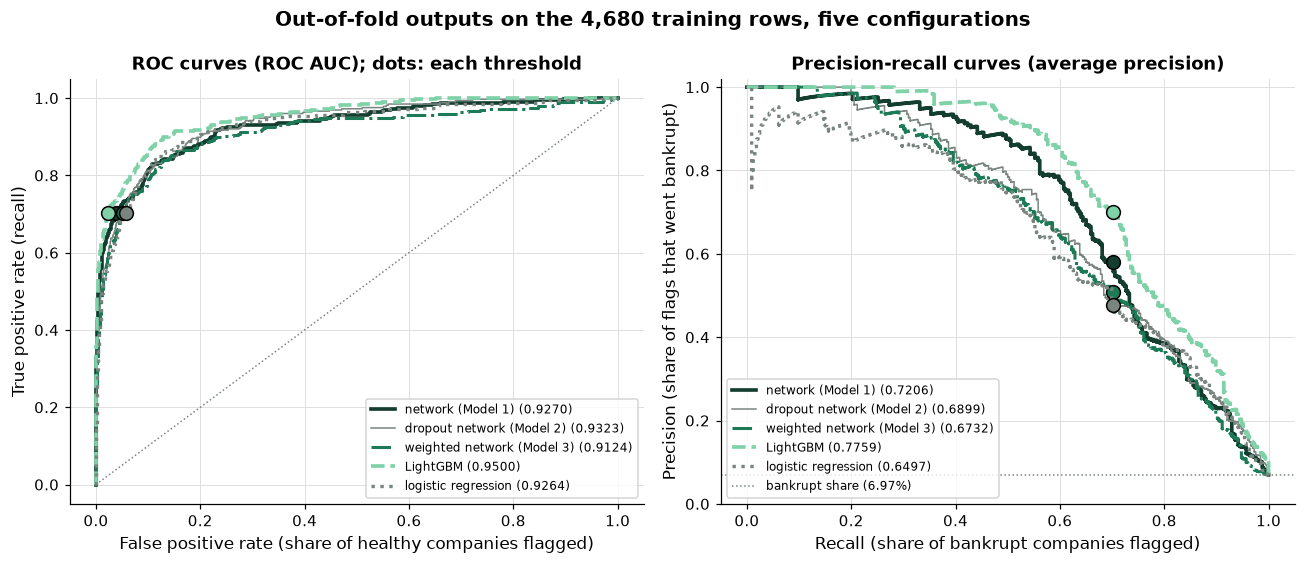

In [35]:
from sklearn.metrics import precision_recall_curve, roc_curve

# one colour and line per model, used on every chart from here on; Model 2, not kept, is the thin grey line
model_styles = {"chosen_network": ("network (Model 1)", plotkit.GREEN_DARK, "-", 2.4),
                "dropout_network": ("dropout network (Model 2)", plotkit.GREY, "-", 1.0),
                "weighted_network": ("weighted network (Model 3)", plotkit.GREEN, "-.", 2.0),
                "course5_lightgbm": ("LightGBM", plotkit.GREEN_LIGHT, "--", 2.4),
                "course4_logistic_regression": ("logistic regression", plotkit.GREY, ":", 2.2)}
curves = {"chosen_network": oof_network, "dropout_network": oof_2, "weighted_network": oof_weighted,
          "course5_lightgbm": oof_light, "course4_logistic_regression": oof_logistic}
actual = y_train.to_numpy() == 1
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 5.2))
for name, output in curves.items():
    label, colour, line, width = model_styles[name]
    false_rate, true_rate, _ = roc_curve(y_train, output)
    left.plot(false_rate, true_rate, color=colour, linestyle=line, linewidth=width,
              label=f"{label} ({roc_auc_score(y_train, output):.4f})")
    precision, recall, _ = precision_recall_curve(y_train, output)
    right.step(recall, precision, where="post", color=colour, linestyle=line, linewidth=width,
               label=f"{label} ({average_precision_score(y_train, output):.4f})")
    # the point each model reaches at its own threshold for recall 0.70 (Model 2 has none: it was not kept)
    if name in thresholds:
        flag = output >= thresholds[name]
        left.plot(flag[~actual].mean(), flag[actual].mean(), "o", color=colour, markersize=9, markeredgecolor="black")
        right.plot(flag[actual].mean(), actual[flag].mean(), "o", color=colour, markersize=9, markeredgecolor="black")
left.plot([0, 1], [0, 1], color=plotkit.GREY, linestyle=":", linewidth=1)
right.axhline(actual.mean(), color=plotkit.GREY, linestyle=":", linewidth=1, label=f"bankrupt share ({actual.mean():.2%})")
left.set_title("ROC curves (ROC AUC); dots: each threshold")
left.set_xlabel("False positive rate (share of healthy companies flagged)")
left.set_ylabel("True positive rate (recall)")
right.set_title("Precision-recall curves (average precision)")
right.set_xlabel("Recall (share of bankrupt companies flagged)")
right.set_ylabel("Precision (share of flags that went bankrupt)")
right.set_ylim(0, 1.02)
left.legend(loc="lower right", fontsize=8)
right.legend(loc="lower left", fontsize=8)
fig.suptitle(f"Out-of-fold outputs on the {len(y_train):,} training rows, five configurations", fontweight="bold")
fig.tight_layout()
plt.show()

* The scores in the legends are the pooled out-of-fold ones. LightGBM is highest on both. The two measures disagree below it: by ROC AUC the dropout network is second (0.9323) and the weighted network last (0.9124); by average precision the network is second (0.7206), the dropout network third, and the logistic regression last (0.6497). ROC AUC counts every healthy company equally; average precision reads the top of the ranking, where the 326 bankrupt companies have to be found among 4,354 healthy ones, and it is the measure the case study set before scoring.
* Every dot sits at a recall of 0.7025 on the right panel's x axis: each threshold flags the same 229 bankrupt companies out of fold, and the height of each dot is the table's precision column.

## 10.8 Intervals on the Pooled Average Precision

Every model was scored on the same 4,680 companies, so their scores rise and fall together from one resample of the rows to the next. A paired interval on each difference is the honest test, as on day 5.

Q. Put a 95 percent bootstrap interval on each pooled average precision, then a paired interval on the network's difference from each of the other three, on the same 1,000 resamples.

In [36]:
# 1,000 resamples of the training rows' out-of-fold outputs, seeded; nothing is refitted
interval_table = pd.DataFrame({name: ensemblekit.bootstrap_interval(y_train, output, average_precision_score)
                               for name, output in oof.items()}, index=["lower", "upper"]).T
interval_table.insert(0, "pooled_ap", comparison["pooled_ap"])
# nothing is marked: the intervals describe which rows were scored, they rank nothing
display(plotkit.styled(interval_table, [], "Pooled out-of-fold average precision with 95 percent bootstrap intervals "
                       "(1,000 resamples of the training rows)", fmt="{:.4f}"))

# bootstrap_interval's own steps, written out, for all four models on each resample (day 5's loop)
y_array = y_train.to_numpy()
rng = np.random.default_rng(SEED)
resampled = {name: [] for name in oof}
while len(resampled["chosen_network"]) < 1000:
    rows = rng.integers(0, len(y_array), len(y_array))
    # the function's rule: a resample with one class is drawn again
    if len(np.unique(y_array[rows])) < 2:
        continue
    for name, output in oof.items():
        resampled[name].append(average_precision_score(y_array[rows], output[rows]))
resampled = pd.DataFrame(resampled)
others = ["weighted_network", "course5_lightgbm", "course4_logistic_regression"]
for name in others:
    resampled[f"network_minus_{name}"] = resampled["chosen_network"] - resampled[name]
same = np.allclose(np.percentile(resampled["chosen_network"], [2.5, 97.5]), interval_table.loc["chosen_network", ["lower", "upper"]],
                   rtol=0, atol=1e-12)
print(f"the network's interval from the hand loop equals bootstrap_interval's within 1e-12: {same}")
paired = pd.DataFrame({name: np.percentile(resampled[f"network_minus_{name}"], [2.5, 97.5]) for name in others},
                      index=["lower", "upper"]).T
paired.insert(0, "difference", [comparison.loc["chosen_network", "pooled_ap"] - comparison.loc[name, "pooled_ap"] for name in others])
paired["network_higher_share"] = [(resampled[f"network_minus_{name}"] > 0).mean() for name in others]
# nothing is marked: each row is a difference from the network, not a model
plotkit.styled(paired, [], "Pooled average precision of the network minus each model: 95 percent paired intervals on the "
               "same 1,000 resamples", fmt="{:.4f}")

,pooled_ap,lower,upper
chosen_network,0.7206,0.6739,0.7619
weighted_network,0.6732,0.6198,0.7165
course5_lightgbm,0.7759,0.7359,0.8129
course4_logistic_regression,0.6497,0.5952,0.7021


the network's interval from the hand loop equals bootstrap_interval's within 1e-12: True


,difference,lower,upper,network_higher_share
weighted_network,0.0474,0.0248,0.0709,1.0000
course5_lightgbm,-0.0553,-0.0837,-0.0296,0.0000
course4_logistic_regression,0.0709,0.0377,0.1075,1.0000


* The network's own interval runs from 0.6739 to 0.7619, 0.0880 wide; LightGBM's from 0.7359 to 0.8129. Two separate intervals overlap, and on their own they would not settle anything.
* **Against LightGBM**, the paired difference is -0.0553, with an interval from -0.0837 to -0.0296: wholly below zero. The network is higher on 0.0 percent of the resamples. On these rows LightGBM ranks the bankrupt companies better than the network by more than the noise from which rows were scored.
* **Against the logistic regression**, +0.0709 (0.0377 to 0.1075), wholly above zero. **Against the weighted network**, +0.0474 (0.0248 to 0.0709), wholly above zero, with the unweighted network higher on 100.0 percent of the resamples: on these resamples the cost of the class weights is not noise. They also changed the scale of the output and lowered the precision at recall 0.70 (section 10.6).
* Every interval describes which rows were scored. None covers refitting with another seed or another set of folds; day 5 measured how much a seed alone moves a network.

Q. Draw each model's fold scores, and each pooled average precision with its interval.

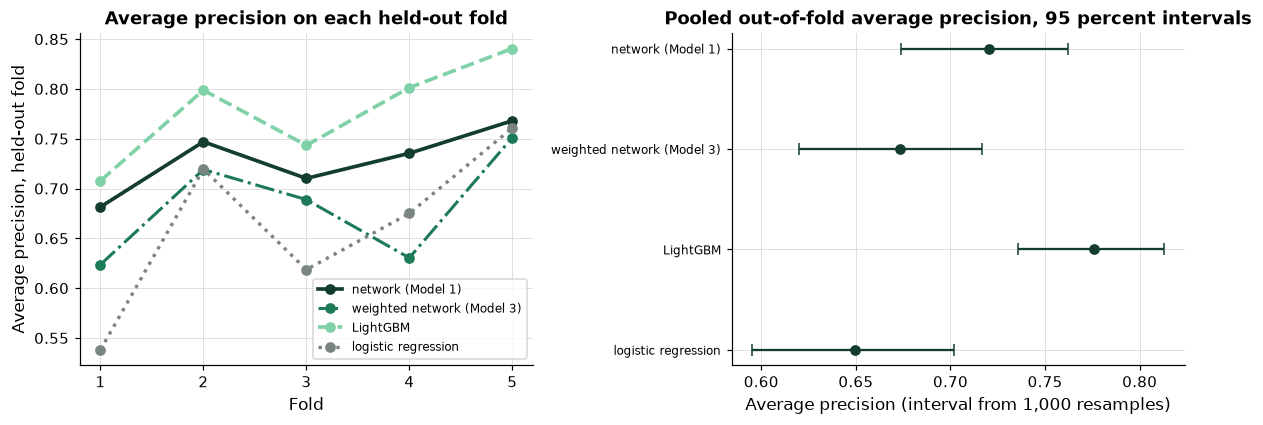

In [37]:
# plt was imported in the setup, with the course's chart style; the colours are section 10.7's
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
for name in fold_table.columns:
    label, colour, line, width = model_styles[name]
    left.plot(range(1, 6), fold_table[name], marker="o", color=colour, linestyle=line, linewidth=width, label=label)
left.set_xticks(range(1, 6))
left.set_title("Average precision on each held-out fold")
left.set_xlabel("Fold")
left.set_ylabel("Average precision, held-out fold")
left.legend(fontsize=8)

names = list(interval_table.index)
positions = np.arange(len(names))
# a bar from the lower to the upper end of each interval, and the pooled average precision as a dot
right.errorbar(interval_table["pooled_ap"], positions,
               xerr=[interval_table["pooled_ap"] - interval_table["lower"], interval_table["upper"] - interval_table["pooled_ap"]],
               fmt="o", capsize=4, color=plotkit.GREEN_DARK)
right.set_yticks(positions)
right.set_yticklabels([model_styles[name][0] for name in names], fontsize=8)
right.invert_yaxis()
right.set_title("Pooled out-of-fold average precision, 95 percent intervals")
right.set_xlabel("Average precision (interval from 1,000 resamples)")
plt.tight_layout()
plt.show()

* Left: the four lines rise and fall together from fold to fold, the reason a paired comparison is the test. LightGBM's line sits on top on 5 folds. Right: the intervals overlap, yet the paired intervals of section 10.8 separate LightGBM from the network.

## 10.9 The Results Workbook

Three sheets: `folds` (each model's average precision on each held-out fold), `comparison` (pooled scores, thresholds, precision and recall at them, and each interval), and `class_weights` (section 10.6's four ways of flagging).

Q. Write `polish_network_results.xlsx` with `pd.ExcelWriter`, then read it back and check that nothing changed on the way.

In [38]:
# one table per sheet: the fold scores, the comparison with its intervals, and the class-weight decision
fold_sheet = fold_table.rename_axis("fold").reset_index()
comparison_sheet = comparison.join(interval_table[["lower", "upper"]]).rename_axis("model").reset_index()
weights_sheet = class_weight_table.rename_axis("setting").reset_index()

# ExcelWriter with openpyxl, one sheet per table; the workbook goes in the work folder, never in the course folder
with pd.ExcelWriter("polish_network_results.xlsx", engine="openpyxl") as writer:
    fold_sheet.to_excel(writer, sheet_name="folds", index=False)
    comparison_sheet.to_excel(writer, sheet_name="comparison", index=False)
    weights_sheet.to_excel(writer, sheet_name="class_weights", index=False)

# sheet_name=None reads every sheet, in the workbook's order
back = pd.read_excel("polish_network_results.xlsx", sheet_name=None)
print(f"sheets: {list(back)}; rows {[len(frame) for frame in back.values()]}")
for name, frame in [("folds", fold_sheet), ("comparison", comparison_sheet), ("class_weights", weights_sheet)]:
    pd.testing.assert_frame_equal(back[name], frame, check_exact=False, rtol=1e-12)
print("all three sheets equal after the round trip")

sheets: ['folds', 'comparison', 'class_weights']; rows [5, 4, 4]
all three sheets equal after the round trip


* Three sheets, in the order written, and every number back within 1e-12. Excel opened this workbook too (Excel Side by Side).

## 10.10 What the Model Shows, and Where It Fails

Every number of the case study in one place: each model on every set of rows it may open, at its out-of-fold threshold for recall 0.70. The two networks were fitted once on the 3,744 fit rows and stopped on the 936 stopping rows in section 10.2, and by five folds from section 10.5; LightGBM and the logistic regression are fitted here on all 4,680 training rows, and by five folds in section 10.7. The test rows are not among them.

Q. Build the results table across every model and set of rows.

In [39]:
# both scikit-learn models fitted on all the training rows, to score them on the rows they were fitted on
light.fit(X_train, y_train)
logistic.fit(X_train, y_train)
fit_rows, stop_rows, oof_rows = f"fit rows ({len(y_fit):,})", f"stopping rows ({len(y_stop):,})", f"out of fold ({len(y_train):,})"
train_rows = f"training rows ({len(y_train):,})"
scored = {("chosen_network", fit_rows): (y_fit, plain.predict(A_fit, verbose=0).ravel()),
          ("chosen_network", stop_rows): (y_stop, output_plain),
          ("chosen_network", oof_rows): (y_train, oof_network),
          ("weighted_network", fit_rows): (y_fit, weighted.predict(A_fit, verbose=0).ravel()),
          ("weighted_network", stop_rows): (y_stop, output_weighted),
          ("weighted_network", oof_rows): (y_train, oof_weighted)}
for name, model in [("course5_lightgbm", light), ("course4_logistic_regression", logistic)]:
    scored[(name, train_rows)] = (y_train, model.predict_proba(X_train)[:, 1])
    scored[(name, oof_rows)] = (y_train, oof[name])

result_rows = {}
for (name, rows_name), (outcome, output) in scored.items():
    flag = (output >= thresholds[name]).astype(int)
    measures = mlkit.classification_metrics(outcome, flag)
    result_rows[(name, rows_name)] = {"roc_auc": roc_auc_score(outcome, output),
                                      "average_precision": average_precision_score(outcome, output),
                                      "recall": measures["recall"], "precision": measures["precision"],
                                      "flagged": int(flag.sum())}
results_table = pd.DataFrame(result_rows).T
results_table["flagged"] = results_table["flagged"].astype(int)
results_table.index.names = ["model", "rows"]
# nothing is marked: the rows mix models and sets of rows, and a model's own fitted rows flatter it
plotkit.styled(results_table, [], "Every model on every set of rows it may open, at its out-of-fold threshold for recall 0.70",
               fmt="{:.4f}")

<styled table: Every model on every set of rows it may open, at its out-of-fold threshold for recall 0.70>

* Read each model's rows from top to bottom. LightGBM's average precision on the rows it was fitted on is 1.0000, against 0.7759 out of fold: its trees rank their own rows perfectly, and flag every bankrupt company there. The network's is 0.8341 on its fit rows, 0.7331 on its stopping rows, and 0.7206 out of fold; the logistic regression's 0.7206 and 0.6497.
* A score on a model's own fitted rows measures how well it fits them, which is why no choice in this case study was made on one. Out of fold every recall is 0.7025, by construction; on the fitted rows it is what the threshold gave there.

Q. Draw the average precision and the ROC AUC of each model on the rows it was fitted on and out of fold.

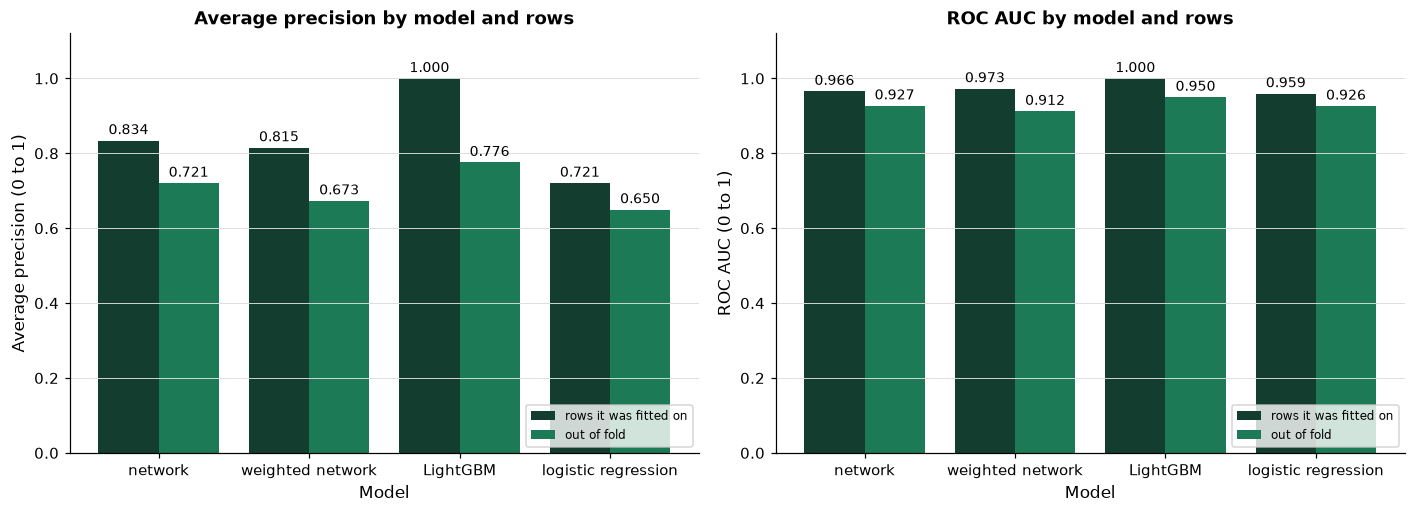

In [40]:
short = {"chosen_network": "network", "weighted_network": "weighted network", "course5_lightgbm": "LightGBM",
         "course4_logistic_regression": "logistic regression"}
fitted_on = {"chosen_network": fit_rows, "weighted_network": fit_rows, "course5_lightgbm": train_rows,
             "course4_logistic_regression": train_rows}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, score, label in zip(axes, ["average_precision", "roc_auc"], ["Average precision", "ROC AUC"]):
    frame = pd.DataFrame({"rows it was fitted on": {short[n]: results_table.loc[(n, fitted_on[n]), score] for n in short},
                          "out of fold": {short[n]: results_table.loc[(n, oof_rows), score] for n in short}})
    frame.index.name = "Model"
    plotkit.bars(frame, f"{label} by model and rows", f"{label} (0 to 1)", ax=ax, fmt="{:.3f}")
    ax.set_ylim(0, 1.12)
    ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

* The dark bar of each pair is the model on its own fitted rows, the green bar out of fold. LightGBM's pair is furthest apart in average precision (0.2241), the network's 0.1136, the logistic regression's 0.0709. Out of fold, the green bars of average precision are the case study's order: LightGBM, the network, the weighted network, the logistic regression.

Q. Draw the network's confusion matrices at its out-of-fold threshold on its fit rows, its stopping rows, and out of fold.

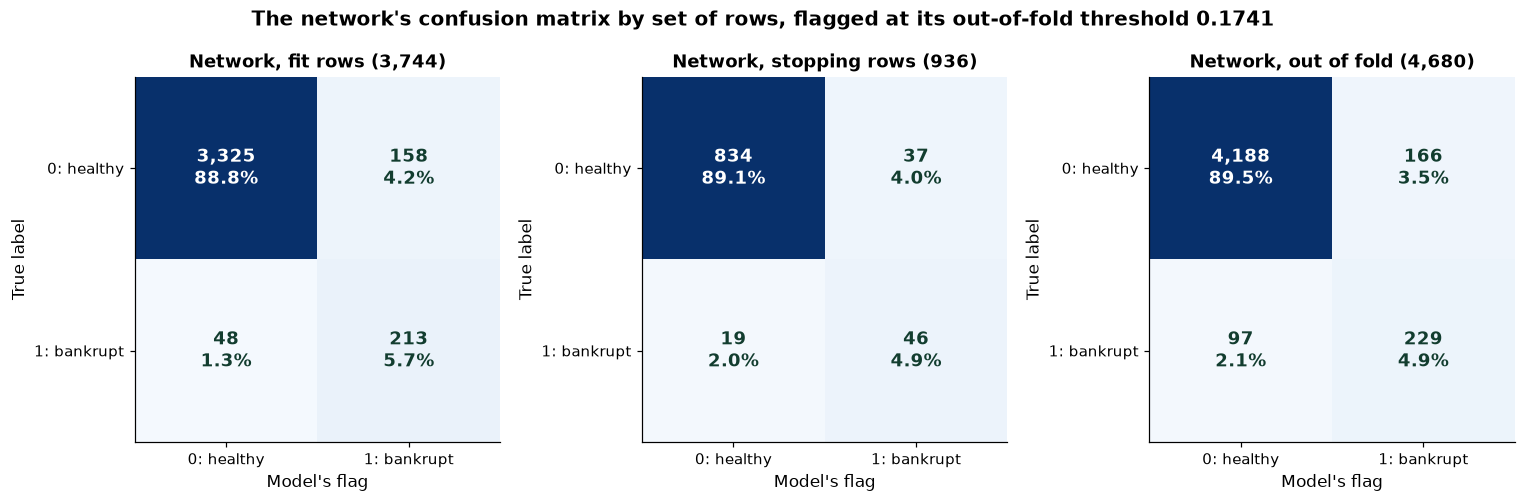

In [41]:
# a Keras model has no predict_proba, so each panel is drawn from its outputs flagged at the out-of-fold threshold
network_splits = {fit_rows: scored[("chosen_network", fit_rows)], stop_rows: scored[("chosen_network", stop_rows)],
                  oof_rows: scored[("chosen_network", oof_rows)]}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
for ax, (rows_name, (outcome, output)) in zip(axes, network_splits.items()):
    plotkit.confusion_heatmap(outcome, (output >= threshold_network).astype(int), f"Network, {rows_name}", labels, ax=ax)
fig.suptitle(f"The network's confusion matrix by set of rows, flagged at its out-of-fold threshold {threshold_network:.4f}",
             fontweight="bold")
fig.tight_layout()
plt.show()

* What happened down the side ("True label"), the network's flag across the top; each cell holds its count and its share of that panel's rows.
* Recall 81.6 percent on the fit rows, 70.8 percent on the stopping rows, 70.2 percent out of fold. The first two panels are section 10.2's single fit, the third the five folds' networks; the threshold is the same in all three.

Q. Draw LightGBM's and the logistic regression's confusion matrices at their thresholds on the training rows and out of fold.

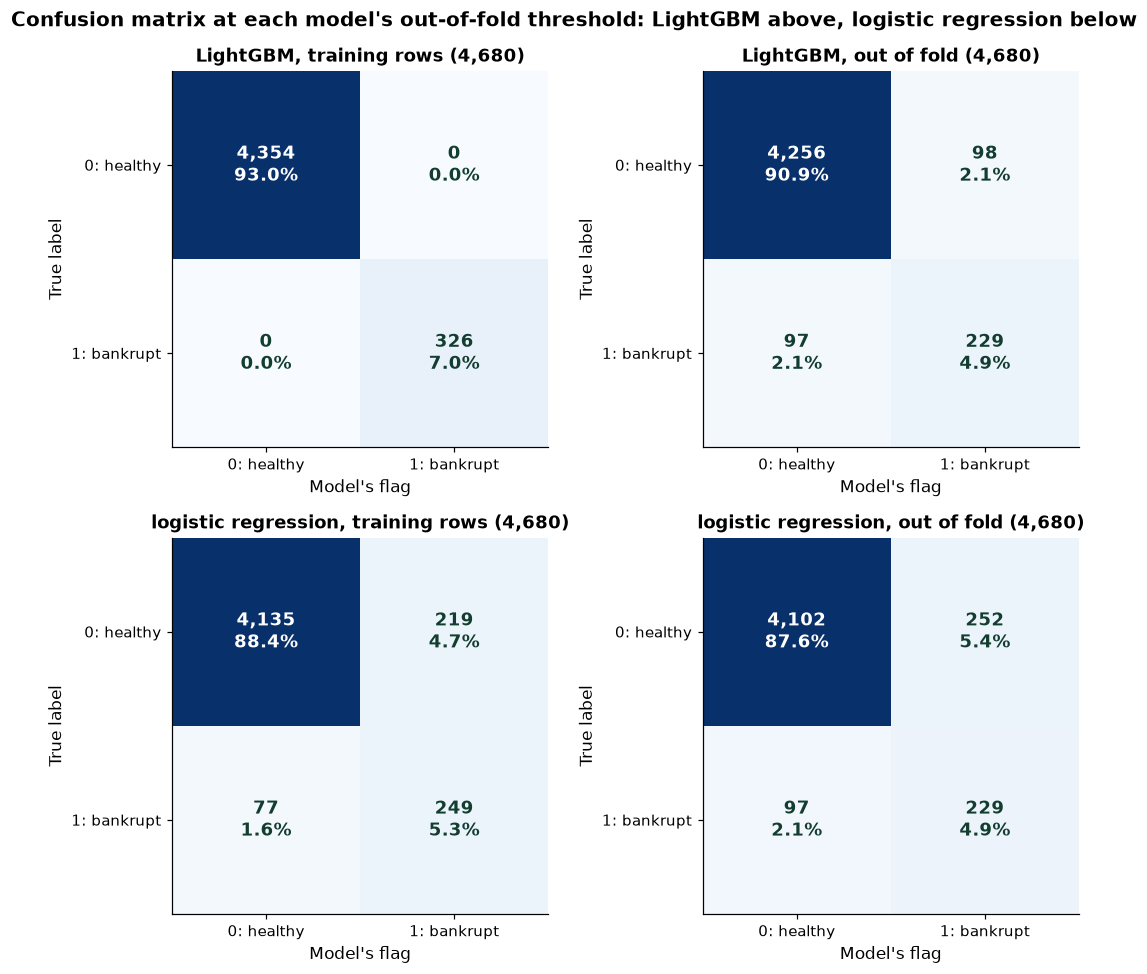

In [42]:
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for row_axes, name in zip(axes, ["course5_lightgbm", "course4_logistic_regression"]):
    for ax, rows_name in zip(row_axes, [train_rows, oof_rows]):
        outcome, output = scored[(name, rows_name)]
        plotkit.confusion_heatmap(outcome, (output >= thresholds[name]).astype(int), f"{short[name]}, {rows_name}", labels, ax=ax)
fig.suptitle("Confusion matrix at each model's out-of-fold threshold: LightGBM above, logistic regression below",
             fontweight="bold")
fig.tight_layout()
plt.show()

* LightGBM flags 100.0 percent of the bankrupt companies in the rows it was fitted on and 70.2 percent out of fold, a gap of 29.8 points, against 6.1 for the logistic regression. Out of fold is the panel to compare.

Q. Which companies does the network get wrong at its threshold? Compare the median net profit to total assets (`Attr1`) and total liabilities to total assets (`Attr2`) of the bankrupt companies it misses and flags, and of the healthy companies it flags and leaves alone, and count the bankruptcies all three models miss.

In [43]:
# the network's flags at its out-of-fold threshold, on the pooled out-of-fold outputs
flags = (oof_network >= threshold_network).astype(int)
missed = (y_train == 1) & (flags == 0)
caught = (y_train == 1) & (flags == 1)
false_flags = (y_train == 0) & (flags == 1)
left_alone = (y_train == 0) & (flags == 0)
medians = pd.DataFrame({group: X_train.loc[mask, ["Attr1", "Attr2"]].median()
                        for group, mask in [("bankrupt, missed", missed), ("bankrupt, flagged", caught),
                                            ("healthy, flagged", false_flags), ("healthy, not flagged", left_alone)]}).T
medians["companies"] = [missed.sum(), caught.sum(), false_flags.sum(), left_alone.sum()]
# nothing is marked: the rows are groups of companies, not models
display(plotkit.styled(medians, [], "Median Attr1 (net profit / total assets) and Attr2 (total liabilities / total assets) "
                       "by group, at the network's threshold, out of fold", fmt="{:.4f}"))

# the bankruptcies that none of the three models flags at its own threshold
missed_by_all = (y_train == 1) & (flags == 0) & (oof_light < threshold_light) & (oof_logistic < threshold_logistic)
print(f"bankruptcies missed by all three models: {missed_by_all.sum():,} of {missed.sum():,} the network misses")
print(f"correlation of the network's and LightGBM's out-of-fold outputs: {np.corrcoef(oof_network, oof_light)[0, 1]:.4f}")

,Attr1,Attr2,companies
"bankrupt, missed",0.0203,0.5564,97
"bankrupt, flagged",-0.1195,0.7634,229
"healthy, flagged",-0.0588,0.7156,166
"healthy, not flagged",0.0549,0.4295,"4,188"


bankruptcies missed by all three models: 63 of 97 the network misses
correlation of the network's and LightGBM's out-of-fold outputs: 0.8759


* The bankrupt companies the network misses look healthier on paper than the ones it flags: a median net profit to total assets of 0.0203 against -0.1195, and liabilities at 55.6 percent of total assets against 76.3 percent. The healthy companies it flags look the other way: a median net profit to total assets of -0.0588, a loss, and liabilities at 71.6 percent of assets, against 0.0549 and 42.9 percent for the healthy companies it leaves alone. The network finds bankruptcies mostly in weak statements, and a statement that looks sound is where it fails.
* 63 of the 97 bankruptcies the network misses are missed by all three models, and the network's outputs correlate 0.8759 with LightGBM's. Different kinds of model, fitted on the same statements, miss many of the same companies.

Q. Write the description, and check its words.

In [44]:
row = comparison.loc["chosen_network"]
low, high = interval_table.loc["chosen_network", ["lower", "upper"]]
light_low, light_high = paired.loc["course5_lightgbm", ["lower", "upper"]]
# the weighted network's paired difference: clear of zero, or not
weights_clear = paired.loc["weighted_network", "lower"] > 0
description = (
    f"On Course 4's {len(X_train):,} training rows of the UCI Polish file (financial statements of Polish companies, "
    f"{y_train.sum():,} of them followed by bankruptcy), scored by five folds, a dense network with two hidden layers "
    f"of 16 and 8 units had a pooled out-of-fold average precision of {row['pooled_ap']:.4f} "
    f"(bootstrap interval {low:.4f} to {high:.4f}). Course 5's LightGBM had "
    f"{comparison.loc['course5_lightgbm', 'pooled_ap']:.4f} and Course 4's logistic regression "
    f"{comparison.loc['course4_logistic_regression', 'pooled_ap']:.4f}. On 1,000 paired resamples the network's "
    f"difference from LightGBM ran from {light_low:.4f} to {light_high:.4f}, wholly below zero. Balanced class "
    f"weights gave the network an average precision of {comparison.loc['weighted_network', 'pooled_ap']:.4f}, "
    f"{'below the unweighted network beyond' if weights_clear else 'within'} the resampling noise, and "
    f"lifted its mean output well above the bankrupt share, so the weighted output is a score. At the threshold for "
    f"a recall of 0.70, set on out-of-fold outputs, the network flagged {flags.sum():,} companies, of which "
    f"{row['precision']:.2%} went bankrupt. The bankrupt companies it did not flag had a median net profit to total "
    f"assets of {medians.loc['bankrupt, missed', 'Attr1']:.4f}, against {medians.loc['bankrupt, flagged', 'Attr1']:.4f} "
    f"for the ones it flagged. The file covers one country and one period, and the page does not say how the "
    f"companies were chosen."
)
# stops on a forecast, advice, lending, or cause word; a reminder, not a proof
ensemblekit.assert_described(description)
print(description)

On Course 4's 4,680 training rows of the UCI Polish file (financial statements of Polish companies, 326 of them followed by bankruptcy), scored by five folds, a dense network with two hidden layers of 16 and 8 units had a pooled out-of-fold average precision of 0.7206 (bootstrap interval 0.6739 to 0.7619). Course 5's LightGBM had 0.7759 and Course 4's logistic regression 0.6497. On 1,000 paired resamples the network's difference from LightGBM ran from -0.0837 to -0.0296, wholly below zero. Balanced class weights gave the network an average precision of 0.6732, below the unweighted network beyond the resampling noise, and lifted its mean output well above the bankrupt share, so the weighted output is a score. At the threshold for a recall of 0.70, set on out-of-fold outputs, the network flagged 395 companies, of which 57.97% went bankrupt. The bankrupt companies it did not flag had a median net profit to total assets of 0.0203, against -0.1195 for the ones it flagged. The file covers on

The description passes the check, and it was read sentence by sentence as well, because the check is a reminder, not a proof. Every number in it is out of fold: no company was scored by a model that fitted, stopped, or scaled on it.

**What the model shows.** On this file, a small dense network, prepared as Course 4 prepared the file and stopped on carved rows, ranks the bankrupt companies at a pooled average precision of 0.7206: above Course 4's logistic regression and below Course 5's LightGBM, each by more than the noise from which rows were scored. Balanced class weights lowered its average precision by more than the resampling noise and turned its output into a score; a threshold chosen on out-of-fold outputs reached recall 0.70 without them, at a higher precision.

**Where it fails.**

* **On companies.** Bankrupt companies whose statements look sound are mostly missed, and healthy companies with a loss and high liabilities are often flagged. At its threshold, 42.0 percent of the companies it flags did not go bankrupt. The other two models miss most of the same bankruptcies.
* **Against LightGBM.** A tree ensemble ranked these companies better, on 5 of 5 folds and in the paired interval. The network's preparation (a filled gap and a rank) may lose something a tree reads from the raw values and the gaps themselves; this case study did not test that.
* **On the choice.** Two networks and one class-weight setting were tried, by the rule set in advance. Other widths, depths, dropout rates, learning rates, or more seeds might have done better; none was tried here.
* **On the threshold.** A threshold set for recall 0.70 on out-of-fold outputs describes these rows. It is not a guarantee on other companies, and there are no other rows here to check it on: the test rows stay closed.
* **On the seed and the folds.** The intervals cover which rows were scored, not the seed or the fold split.

**What the data cannot support.** The companies are Polish, and the statements come from the 2000s and early 2010s: corporate credit there and then differs from US credit today, and nothing here describes any other country, period, or company. The page does not say how the companies were chosen, whether a company appears more than once, or the currency of the amounts, and bankruptcy is the page's flag, with no horizon beyond the page's own wording. The outputs describe this file; they are not a credit view on any company, and no threshold here is a rule for anything.

**What was not tested.** The test rows, by the course's rule; other architectures and longer searches; class weights other than balanced (exercise 1 tries one); preparation without the quantile step; calibration of the unweighted network beyond its mean; and any cost attached to a missed bankruptcy or a false flag, which this course does not assign.

## Excel Side by Side

Excel has no network training, no class weights inside a fit, no cross-validation, and no seeded bootstrap, so the fitting and the resampling stay in Python. What Excel can do is the arithmetic around them: the balanced weights, a weighted log loss, flags and counts at a threshold, percentiles of resampled scores, and the workbook. Every formula below was typed into Excel by script (Excel 16.0 build 20430, 2026-10-06) on values pasted in from this notebook: on a sheet named `weights`, the 3,744 fit rows' outcomes in A2:A3745 and the weighted network's outputs on them in B2:B3745; on a sheet named `flags`, the 4,680 training rows' outcomes and the network's out-of-fold outputs, with its threshold, 0.1741, in F1; on a sheet named `resamples`, the 1,000 resampled average precisions of section 10.8.

| Job | Python | Excel | Excel returned |
| --- | --- | --- | --- |
| Healthy weight | `netkit.balanced_class_weight(y_fit)[0]` | `=ROWS(A2:A3745)/(2*COUNTIF(A2:A3745,0))` in F1 | 0.5375 |
| Bankrupt weight | `netkit.balanced_class_weight(y_fit)[1]` | `=ROWS(A2:A3745)/(2*COUNTIF(A2:A3745,1))` in F2 | 7.1724 |
| Each row's weight | `row_weights` | `=IF(A2=1,$F$2,$F$1)` in C2, filled down | |
| Each row's log loss | `row_loss` | `=-(A2*LN(B2)+(1-A2)*LN(1-B2))` in D2, filled down | |
| Weighted mean log loss | `(row_weights * row_loss).sum() / row_weights.sum()` | `=SUMPRODUCT(C2:C3745,D2:D3745)/SUM(C2:C3745)` | 0.213971 |
| Sum of the weights | `row_weights.sum()` | `=SUM(C2:C3745)` | 3,744.000000 |
| Share of the weight on bankrupt rows | section 10.1 | `=SUMPRODUCT(C2:C3745,A2:A3745)/SUM(C2:C3745)` | 0.500000 |
| Unweighted mean log loss | `row_loss.mean()` | `=AVERAGE(D2:D3745)` | 0.228344 |
| Bankrupt companies flagged (TP) | `mlkit.confusion_counts(...)["tp"]` | `=COUNTIFS(A2:A4681,1,C2:C4681,1)` | 229 |
| Healthy companies flagged (FP) | `["fp"]` | `=COUNTIFS(A2:A4681,0,C2:C4681,1)` | 166 |
| Bankrupt companies missed (FN) | `["fn"]` | `=COUNTIFS(A2:A4681,1,C2:C4681,0)` | 97 |
| Healthy companies not flagged (TN) | `["tn"]` | `=COUNTIFS(A2:A4681,0,C2:C4681,0)` | 4,188 |
| Precision | `comparison.loc["chosen_network", "precision"]` | `=F3/(F3+F4)` | 0.5797 |
| Recall | `comparison.loc["chosen_network", "recall"]` | `=F3/(F3+F5)` | 0.7025 |
| The network's interval | `bootstrap_interval(...)` | `=PERCENTILE.INC(A2:A1001,0.025)` and `=PERCENTILE.INC(A2:A1001,0.975)` | 0.6739 to 0.7619 |
| Paired interval against LightGBM | `paired.loc["course5_lightgbm"]` | `=PERCENTILE.INC(D2:D1001,0.025)` and `=PERCENTILE.INC(D2:D1001,0.975)` | -0.0837 to -0.0296 |
| Paired interval against the logistic regression | `paired.loc["course4_logistic_regression"]` | `=PERCENTILE.INC(E2:E1001,0.025)` and `=PERCENTILE.INC(E2:E1001,0.975)` | 0.0377 to 0.1075 |
| Share of resamples where the network is higher than LightGBM | `(resampled[...] > 0).mean()` | `=COUNTIF(D2:D1001,">0")/COUNT(D2:D1001)` | 0.0000 |

**The weights.** `ROWS` counts the rows and `COUNTIF(...,1)` the bankrupt ones, so `ROWS(A2:A3745)/(2*COUNTIF(A2:A3745,1))` is n / (2 n1), the bankrupt weight, and the same with 0 is the healthy weight. `IF(A2=1,$F$2,$F$1)` in C2, filled down, gives each row its class's weight: Keras's one weight per row.

**The weighted loss.** The log loss column is day 1's formula. `SUMPRODUCT` of the weight column and the loss column, over `SUM` of the weights, is the weighted mean log loss of section 10.2, and Keras's loss for these rows, because `SUM` of the balanced weights returned the number of rows. `SUMPRODUCT` of the weights and the outcomes over `SUM` of the weights returned 0.5: half the weight on bankrupt rows.

**Flags, counts, and percentiles.** As on day 5: `IF(B2>=$F$1,1,0)` filled down is the flag column, the four `COUNTIFS` are the confusion counts and add up to 4,680, and `PERCENTILE.INC` at 0.025 and 0.975 on the resampled average precisions returned `bootstrap_interval`'s two ends and the paired intervals. The resampling itself comes from Python's seeded generator.

**The workbook.** `Workbooks.Open` on `polish_network_results.xlsx` showed the sheets `folds`, `comparison`, `class_weights`, in that order, with 5, 4, and 4 rows below the headers. Each of the 76 numbers Excel holds equals Python's within 1e-12.

Q. Do Excel's numbers equal Python's?

In [45]:
# what Excel returned (from the course's Excel check), beside the same numbers from Python
counts = mlkit.confusion_counts(y_train, flags)
excel = {"healthy weight": 0.537467700258398, "bankrupt weight": 7.172413793103448,
         "weighted mean log loss": 0.21397054993126635, "sum of the weights": 3743.999999999895,
         "share of the weight on bankrupt rows": 0.5000000000000159, "unweighted mean log loss": 0.2283439973354206,
         "bankrupt flagged (TP)": 229, "healthy flagged (FP)": 166,
         "bankrupt missed (FN)": 97, "healthy not flagged (TN)": 4188,
         "precision": 0.579746835443038, "recall": 0.7024539877300614,
         "network interval, lower": 0.6739234343678346, "network interval, upper": 0.7619195346951653,
         "network minus LightGBM, lower": -0.08369040282693321, "network minus LightGBM, upper": -0.029583900018317566,
         "network minus logistic, lower": 0.03771982438169692, "network minus logistic, upper": 0.10753566064576804,
         "share where the network is higher than LightGBM": 0.0}
python = {"healthy weight": weights[0], "bankrupt weight": weights[1],
          "weighted mean log loss": weighted_loss, "sum of the weights": row_weights.sum(),
          "share of the weight on bankrupt rows": (row_weights * y_fit.to_numpy()).sum() / row_weights.sum(),
          "unweighted mean log loss": row_loss.mean(),
          "bankrupt flagged (TP)": counts["tp"], "healthy flagged (FP)": counts["fp"],
          "bankrupt missed (FN)": counts["fn"], "healthy not flagged (TN)": counts["tn"],
          "precision": comparison.loc["chosen_network", "precision"], "recall": comparison.loc["chosen_network", "recall"],
          "network interval, lower": interval_table.loc["chosen_network", "lower"],
          "network interval, upper": interval_table.loc["chosen_network", "upper"],
          "network minus LightGBM, lower": paired.loc["course5_lightgbm", "lower"],
          "network minus LightGBM, upper": paired.loc["course5_lightgbm", "upper"],
          "network minus logistic, lower": paired.loc["course4_logistic_regression", "lower"],
          "network minus logistic, upper": paired.loc["course4_logistic_regression", "upper"],
          "share where the network is higher than LightGBM": paired.loc["course5_lightgbm", "network_higher_share"]}

side_by_side = pd.DataFrame({"Excel": excel, "Python": python}).astype(float)
side_by_side["within 1e-9"] = (side_by_side["Excel"] - side_by_side["Python"]).abs() < 1e-9
plotkit.styled(side_by_side, [], "Excel against Python: the weights, the losses, the network's counts, and the intervals, to 4 decimals",
               fmt="{:.4f}")

,Excel,Python,within 1e-9
healthy weight,0.5375,0.5375,True
bankrupt weight,7.1724,7.1724,True
weighted mean log loss,0.2140,0.2140,True
sum of the weights,3744.0000,3744.0000,True
share of the weight on bankrupt rows,0.5000,0.5000,True
unweighted mean log loss,0.2283,0.2283,True
bankrupt flagged (TP),229.0000,229.0000,True
healthy flagged (FP),166.0000,166.0000,True
bankrupt missed (FN),97.0000,97.0000,True
healthy not flagged (TN),4188.0000,4188.0000,True


* Every number matches, the four counts exactly. The comparison column says "within 1e-9" because the sum of the weights is a sum of 3,744 numbers, added in a different order by Excel and by numpy; every other number matched within 1e-12 in the check.
* The bars of sections 10.1 and 10.10 are what Excel draws as a clustered column chart from the same table pasted into a sheet.

## Save the Day with Git

Week 2 ends today, and the day's Git step compares the end of week 2 with the end of week 1. The work folder is new, so it has no history yet: the first commit rebuilds week 1's module, the second holds today's, and the experiment log follows. Each end of week gets its name with `git tag`.

Week 1's module is easy to rebuild, because every day only adds to `netkit.py`: week 1's file is the start of today's, up to the first line day 6 added.

Q. Make the work folder a repository.

In [46]:
# stop here, with the steps to install it, if Git is not on this machine
if shutil.which("git") is None:
    raise RuntimeError("Git is not installed. Install Git for Windows from https://git-scm.com/downloads "
                       "(or run  winget install --id Git.Git  where your firm allows it), restart VS Code, "
                       "and run this cell again. Colab has Git already.")

# -C "{work}" points every Git command at the work folder, whatever folder the notebook is in
!git -C "{work}" --version
# make the work folder a repository
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, a reserved example email, line endings left as they are,
# and no commit signing, so a signing setup on your machine does not ask for a key here
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false

git version 2.50.1.windows.1


Q. Is Git working in the work folder, and only there?

In [47]:
# the guard: Git must report the work folder as the top of this repository, or the notebook stops
top = subprocess.run(["git", "-C", str(work), "rev-parse", "--show-toplevel"],
                     capture_output=True, text=True, check=True).stdout.strip()
assert os.path.samefile(top, work), "Git is not working in the work folder. Stop, and run the setup cell again."
print(f"Git is working in {work.name} and nowhere else")

Git is working in pfi_course6_10_zeioh9un and nowhere else


Q. Tell Git which files never to track: Python's bytecode cache, pytest's cache, Excel workbooks, and saved Keras models.

In [48]:
%%writefile .gitignore
__pycache__/
.pytest_cache/
*.xlsx
*.keras

Writing .gitignore


Q. Cut `netkit.py` and `test_netkit.py` back to week 1, keeping today's text, and commit week 1 with the name `week1`.

In [49]:
# today's two files, kept exactly, to put back after the week 1 commit
module_today, tests_today = Path("netkit.py").read_bytes(), Path("test_netkit.py").read_bytes()

# week 1's files: everything before the first line day 6 added (every day only appends)
day6_module_start = "\n\n\nfrom sklearn.model_selection import train_test_split  # a random fifth of a fold's training rows to stop on"
day6_tests_start = "\n\n\ndef regression_frame("
module_text, tests_text = Path("netkit.py").read_text(encoding="utf-8"), Path("test_netkit.py").read_text(encoding="utf-8")
Path("netkit.py").write_text(module_text[:module_text.index(day6_module_start)] + "\n", encoding="utf-8")
Path("test_netkit.py").write_text(tests_text[:tests_text.index(day6_tests_start)] + "\n", encoding="utf-8")
print(f"week 1's netkit.py: {len(Path('netkit.py').read_text(encoding='utf-8').splitlines()):,} lines; "
      f"today's: {len(module_text.splitlines()):,}")

week 1's netkit.py: 323 lines; today's: 558


In [50]:
# commit week 1's module, then put the name week1 on that commit
!git -C "{work}" add .gitignore mlkit.py ensemblekit.py netkit.py test_netkit.py
!git -C "{work}" commit -q -m "Week 1's netkit: from tensors to cv_network, 24 tests"
!git -C "{work}" tag week1

Q. Put today's files back, commit them, then add the experiment log.

In [51]:
# today's files, byte for byte as they were
Path("netkit.py").write_bytes(module_today)
Path("test_netkit.py").write_bytes(tests_today)
print(f"netkit.py back to {len(Path('netkit.py').read_text(encoding='utf-8').splitlines()):,} lines")

netkit.py back to 558 lines


In [52]:
!git -C "{work}" add netkit.py test_netkit.py
!git -C "{work}" commit -q -m "Week 2's netkit: losses to class weights, ending with output_vs_rate, 43 tests"
!git -C "{work}" log --oneline --decorate

eed1f55 (HEAD -> main) Week 2's netkit: losses to class weights, ending with output_vs_rate, 43 tests
44335c2 (tag: week1) Week 1's netkit: from tensors to cv_network, 24 tests


In [53]:
# rows = "cv": pooled out-of-fold outputs on the training rows, flagged at each model's own threshold
log_rows = []
for name in oof:
    flag_oof = (oof[name] >= thresholds[name]).astype(int)
    log_rows.append({"model": name, "rows": "cv", "roc_auc": comparison.loc[name, "pooled_roc_auc"],
                     "average_precision": comparison.loc[name, "pooled_ap"], "threshold": thresholds[name],
                     **mlkit.classification_metrics(y_train, flag_oof)})
results = pd.DataFrame(log_rows)
# 4 decimals and LF line endings, so a later diff shows a real change and prints the same everywhere
results.to_csv("results.csv", index=False, float_format="%.4f", lineterminator="\n")
print((work / "results.csv").read_text(encoding="utf-8"))
print(f"accuracy of flagging no company (all-zero baseline) on the training rows: {1 - y_train.mean():.4f}")

model,rows,roc_auc,average_precision,threshold,accuracy,precision,recall,f1
chosen_network,cv,0.9270,0.7206,0.1741,0.9438,0.5797,0.7025,0.6352
weighted_network,cv,0.9124,0.6732,0.6073,0.9318,0.5078,0.7025,0.5894
course5_lightgbm,cv,0.9500,0.7759,0.0818,0.9583,0.7003,0.7025,0.7014
course4_logistic_regression,cv,0.9264,0.6497,0.7134,0.9254,0.4761,0.7025,0.5675

accuracy of flagging no company (all-zero baseline) on the training rows: 0.9303


In [54]:
# commit the log, then put the name week2 on that commit
!git -C "{work}" add results.csv
!git -C "{work}" commit -q -m "Experiment log: four Polish models, pooled out-of-fold outputs at recall 0.70 thresholds"
!git -C "{work}" tag week2
!git -C "{work}" log --oneline --decorate

bee78b5 (HEAD -> main, tag: week2) Experiment log: four Polish models, pooled out-of-fold outputs at recall 0.70 thresholds
eed1f55 Week 2's netkit: losses to class weights, ending with output_vs_rate, 43 tests
44335c2 (tag: week1) Week 1's netkit: from tensors to cv_network, 24 tests


Q. What did week 2 change? Compare `week1` with `week2`, file by file.

In [55]:
# --stat prints one line per changed file: its name and how many lines changed
!git -C "{work}" diff --stat week1 week2

 netkit.py      | 235 +++++++++++++++++++++++++++++++++++++++++++++++++++++++++
 results.csv    |   5 ++
 test_netkit.py | 210 +++++++++++++++++++++++++++++++++++++++++++++++++++
 3 files changed, 450 insertions(+)


* Three files: `netkit.py` and `test_netkit.py` grew by everything days 6 to 10 added (from 24 tests to 43), and `results.csv` is new. `mlkit.py` and `ensemblekit.py` are not in the list: week 2 never changed them.
* On the `cv` rows every recall is at least 0.70, by construction, because each threshold was set there. Accuracy sits beside the all-zero baseline (0.9303) and chooses nothing: flagging no company at all would be right 93.0 percent of the time.

## Bring It Home

Add today's two functions and their tests to your own `my_bondmath` folder, run the tests, commit, and name the end of week 2. Open a PowerShell terminal in VS Code.

**Step 1.** Go to your folder and open the two files.

```powershell
Set-Location "$HOME\projects\my_bondmath"
code netkit.py
code test_netkit.py
```

**Step 2.** At the end of `netkit.py`, paste the code of the two `%%writefile -a netkit.py` cells (sections 10.1 and 10.2), without their first lines, one after the other. At the end of `test_netkit.py`, paste the two `%%writefile -a test_netkit.py` cells the same way. Save both.

**Step 3.** Run the tests.

```powershell
python -m pytest -q test_netkit.py
```

The last line says `43 passed`.

**Step 4.** Read the change, commit, name the week, and compare it with week 1.

```powershell
git diff --stat
git add netkit.py test_netkit.py
git commit -m "Week 2's netkit: losses to class weights, ending with output_vs_rate, 43 tests"
git tag week2
git diff --stat week1 week2
```

The last line works if you tagged `week1` on day 5. Your folder keeps code only. The results workbook and `results.csv` stay in the work folder.

**In Colab**, download `netkit.py` and `test_netkit.py` from the work folder under `/tmp` in the file browser.

## You Can Now

* Work out balanced class weights with `balanced_class_weight`, and say why they add up to the number of rows and put half the weight on the rare class.
* Say what `class_weight` does inside `fit`: one weight per row, a weighted sum of log losses divided by the number of rows.
* Show with `output_vs_rate` that a class-weighted network's output is a score, not a probability.
* Compare class weights against a lower threshold by average precision and by precision at a recall chosen on out-of-fold outputs.
* Put a network beside logistic regression and LightGBM by the same folds, with separate and paired bootstrap intervals, and say what the numbers support.
* Write what a network shows and where it fails on a rare outcome, and compare two weeks of work with `git diff --stat`.

Next, day 11 opens week 3 on the Treasury curve: windows of past changes, and walk-forward scoring of a network on dates it never fitted.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`. Give each exercise a real try first, then check your work against it.

The exercises use the case study's rows and models: Course 4's 4,680 Polish training rows, scored by five folds inside them, the test rows closed. Every answer describes this file. Replace each `...` with your own code, then run the check cell.

Q. Run the next cell first. It checks that the case study's variables are there (run the notebook from the top if one is missing) and defines `check`.

In [56]:
# the exercises use the case study's variables: stop if the notebook was not run from the top
needed = ["X_train", "y_train", "X_fit", "y_fit", "transformer", "chosen_build", "oof_network", "threshold_network",
          "oof_light", "oof_logistic"]
missing = [name for name in needed if name not in globals()]
assert not missing, f"run the notebook from the top first: {missing} not defined"


def check(label, answer, expected):
    """Compare an exercise answer with the expected value and print the result."""
    if answer is ...:
        print(f"{label}: not attempted yet")
        return
    if isinstance(expected, float):
        # numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 1e-6
    else:
        correct = answer == expected
    if correct:
        print(f"{label}: correct")
    else:
        print(f"{label}: not yet. You have {answer}.")

### Exercise 1

Q. Fit the chosen network by the same five folds with class weights of 1 for a healthy company and 5 for a bankrupt one, `class_weight={0: 1.0, 1: 5.0}`, through `netkit.cv_network(chosen_build, transformer, X_train, y_train, class_weight=...)`. Store the fold-mean average precision in **ex1_fold_mean_ap** and the mean of the pooled out-of-fold outputs in **ex1_mean_output**. Where do they land between section 10.6's unweighted and balanced networks?

In [57]:
ex1_fold_mean_ap = ...
ex1_mean_output = ...

In [58]:
check("Exercise 1 fold-mean average precision", ex1_fold_mean_ap, 0.7083615232970331)
check("Exercise 1 mean output", ex1_mean_output, 0.1121812609483118)

Exercise 1 fold-mean average precision: not attempted yet
Exercise 1 mean output: not attempted yet


### Exercise 2

Q. Repeat section 10.7's comparison for a desk that asks for a recall of 0.60. For the network, LightGBM, and the logistic regression, choose the threshold with `mlkit.threshold_for_recall(y_train, ..., 0.60)` on the out-of-fold outputs (`oof_network`, `oof_light`, `oof_logistic`), flag the training rows at it, and store a dictionary of model name (`chosen_network`, `course5_lightgbm`, `course4_logistic_regression`) to precision, rounded to 4 decimals, in **ex2_precision**.

In [59]:
ex2_precision = ...

In [60]:
check("Exercise 2 precision at recall 0.60", ex2_precision, {'chosen_network': 0.7778, 'course5_lightgbm': 0.8559, 'course4_logistic_regression': 0.5921})

Exercise 2 precision at recall 0.60: not attempted yet


### Exercise 3

Q. Add a function to your module. `flag_count(y_score, threshold)` returns how many outputs are at or above the threshold, as a whole number, and raises `ValueError` on an empty input or a threshold outside 0 to 1. Write the docstring first. Then add `test_flag_count_hand`, which checks two small cases by hand and both errors. Run pytest, reload the module, and store `netkit.flag_count(oof_network, threshold_network)` in **ex3_flagged**.

Write the function in the cell that starts with `%%writefile -a netkit.py` and the test in the one that starts with `%%writefile -a test_netkit.py`, and run each of those cells once.

In [61]:
%%writefile -a netkit.py


# Exercise 3: write flag_count(y_score, threshold) below this line

Appending to netkit.py


In [62]:
%%writefile -a test_netkit.py


# Exercise 3: write test_flag_count_hand() below this line

Appending to test_netkit.py


In [63]:
# run pytest, reload the module, then use your function
ex3_flagged = ...

In [64]:
check("Exercise 3 companies flagged", ex3_flagged, 395)

Exercise 3 companies flagged: not attempted yet


### Exercise 4

Q. Section 10.2's sweep scaled its class weights to add up to the number of rows. Run the next cell first: it defines `weights_for_ratio` as section 10.2 did. Then, for a bankrupt : healthy ratio of 20 on the fit rows, store the bankrupt company's weight in **ex4_w1** and the sum of all the fit rows' weights (one weight per row, by its class) in **ex4_total**. How does the sum compare with `len(y_fit)`?

In [65]:
def weights_for_ratio(y, ratio):
    """Class weights with bankrupt : healthy equal to ratio, scaled to add up to the number of rows, as the balanced ones do."""
    n_healthy, n_bankrupt = int((y == 0).sum()), int((y == 1).sum())
    healthy = len(y) / (n_healthy + ratio * n_bankrupt)
    return {0: healthy, 1: ratio * healthy}


print("weights_for_ratio defined")

weights_for_ratio defined


In [66]:
# the weights for a ratio of 20, then the sum of one weight per fit row
ex4_w1 = ...
ex4_total = ...

In [67]:
check("Exercise 4 the bankrupt weight at ratio 20", ex4_w1, 8.60392967942089)
check("Exercise 4 the sum of the row weights", ex4_total, 3744.000000000001)

Exercise 4 the bankrupt weight at ratio 20: not attempted yet
Exercise 4 the sum of the row weights: not attempted yet


### Exercise 5: AI check

You ask an AI assistant for a function that gives the class weights for `fit`, and you give it a docstring as the request. **The docstring is the prompt.** This is what you gave it:

```
Class weights for fit(class_weight=...) that make the bankrupt and the healthy companies count equally
    in the loss.

    Input: y, the outcomes of the fit rows (1 bankrupt, 0 healthy).
    Output: {0: the weight of a healthy company, 1: the weight of a bankrupt company}, each n / (2 x the count
    of its own class), so the rare class gets the larger weight.
```

The function below came back. It was written for this course in the style of an AI assistant's answer. It runs without an error, returns the two right numbers, and contains one bug.

In [68]:
# written for this course in the style of an AI assistant's answer. It runs, and it contains one bug.
def bankrupt_weights(y):
    """Class weights for fit(class_weight=...) that make the bankrupt and the healthy companies count equally
    in the loss.

    Input: y, the outcomes of the fit rows (1 bankrupt, 0 healthy).
    Output: {0: the weight of a healthy company, 1: the weight of a bankrupt company}, each n / (2 x the count
    of its own class), so the rare class gets the larger weight.
    """
    y = np.asarray(y)
    n, n_bankrupt = len(y), int(y.sum())
    n_healthy = n - n_bankrupt
    # rows divided by twice the class count
    return {0: n / (2 * n_bankrupt), 1: n / (2 * n_healthy)}

Q. Before you run the next cell: which weight will the bankrupt companies get, and what share of the total weight will sit on them? Section 10.1 found half.

In [69]:
ai_weights = bankrupt_weights(y_fit)
print(f"bankrupt_weights: {ai_weights}")
ai_row_weights = np.where(y_fit.to_numpy() == 1, ai_weights[1], ai_weights[0])
print(f"share of the weight on bankrupt rows: {(ai_row_weights * y_fit.to_numpy()).sum() / ai_row_weights.sum():.4f}")

bankrupt_weights: {0: 7.172413793103448, 1: 0.537467700258398}
share of the weight on bankrupt rows: 0.0056


Q. Test the function against its docstring before you trust it: the rare class must get the larger weight, and each weight must equal `balanced_class_weight`'s.

In [70]:
# the test, written from the docstring before the code is trusted
ai_weights = bankrupt_weights(y_fit)
expected = netkit.balanced_class_weight(y_fit)

# the rare class must get the larger weight, and each weight must be the balanced weight of its own class
assert ai_weights[1] > ai_weights[0], (f"bankrupt weight {ai_weights[1]:.4f} is not above the healthy weight "
                                       f"{ai_weights[0]:.4f}")
assert all(abs(ai_weights[k] - expected[k]) < 1e-12 for k in (0, 1)), f"weights {ai_weights}, balanced {expected}"
print(f"bankrupt_weights equal to balanced_class_weight within 1e-12: healthy {ai_weights[0]:.4f}, bankrupt {ai_weights[1]:.4f}")

AssertionError: bankrupt weight 0.5375 is not above the healthy weight 7.1724

Q. Read the test's message, fix the function in the cell that defines it, and run that cell and the test again until the test passes. Then store the fixed function's bankrupt weight, `bankrupt_weights(y_fit)[1]`, in **ex5_bankrupt_weight**.

In [71]:
# fix the function above and run the test again, then store the answer
ex5_bankrupt_weight = ...

In [72]:
check("Exercise 5 the fixed bankrupt weight", ex5_bankrupt_weight, 7.172413793103448)

Exercise 5 the fixed bankrupt weight: not attempted yet


## Tidying Up

The work folder stays where it is, so you can open it: its name was printed by the setup cell, and on Windows it is under `$env:TEMP`. Every run of the setup cell makes a new one. To delete a work folder, run these lines in a cell of the same notebook session. Git marks its own files read-only, and on Windows a plain delete stops at them with a `PermissionError`, so the handler clears that flag and tries again.

```python
import stat

def clear_read_only(function, path, error):
    """Make a read-only file writable, then retry the delete that failed on it."""
    os.chmod(path, stat.S_IWRITE)
    function(path)

os.chdir(notebook_folder)
shutil.rmtree(work, onexc=clear_read_only)
print(f"{work.name} exists: {work.exists()}")
```